# ITRPA4 Mini Dissertation: Experiment Notebook
**Predicting Epidemic Outbreaks from Sparse Twitter Data: Statistical vs. Machine Learning Approaches**

Dataset: *Influenza Outbreak Event Prediction via Twitter*, Zhao, L. (2015), UCI Machine Learning Repository, https://doi.org/10.24432/C5CP7V (CC BY 4.0).

This notebook runs the methodology from the ITRMA4 proposal (Section 3) from start to finish:

| Section | Proposal link |
|---|---|
| 1. Setup and data loading | 3.2 |
| 2. Sparsity analysis | 3.3.1, RQ1 |
| 3. Class imbalance analysis | 3.3.2 |
| 4. Preprocessing comparison | 3.3.3 |
| 5. Statistical models (LR L1/L2, Poisson/NB count models, Bayesian horseshoe LR) | 3.4.1, RQ2 |
| 6. Machine learning models (RF, XGBoost, LightGBM, MLP) | 3.4.2, RQ3 |
| 7. Test-set evaluation | 3.5 |
| 8. Dimensionality reduction and imbalance-handling experiments | 3.3.3, RQ3 |
| 9. Sparsity experiments | RQ1 |
| 10. Temporal validation | 3.5 |
| 11. Calibration | 3.6, RQ4 |
| 12. Interpretability (coefficients, posterior, SHAP) | 3.6, RQ4 |
| 13. Compute time | RQ4 |
| 14. Improved models (temporal features, calibration, thresholds, ensemble) and statistical validation (block bootstrap, DeLong) | 3.5, 3.6, RQ3, RQ4 |
| 15. Save artefacts for the prototype and write the results summary | |

All random seeds are fixed (`SEED = 42`). Every number reported in the dissertation comes from the outputs of this notebook.

## 0. Optional: Google Colab upload
Run this cell only in Colab if `influenza_outbreak_dataset.mat` is not already in the working directory. Locally, it does nothing.

In [1]:
import os
DATA_PATH = "influenza_outbreak_dataset.mat"   # relative path
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB and not os.path.exists(DATA_PATH):
    from google.colab import files
    print("Please upload influenza_outbreak_dataset.mat")
    up = files.upload()
    DATA_PATH = list(up.keys())[0]
    # Colab usually has most packages already; install any that are missing
    os.system("pip -q install lightgbm xgboost shap imbalanced-learn pymc")
print("Data file:", DATA_PATH, "| exists:", os.path.exists(DATA_PATH))

Data file: influenza_outbreak_dataset.mat | exists: True


## 1. Setup and data loading

In [2]:
import time, json, warnings
import numpy as np
import pandas as pd
import scipy.io as sio
import scipy.sparse as sp
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, MaxAbsScaler, StandardScaler
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_selection import SelectKBest, chi2, SelectFromModel
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score, precision_score,
                             recall_score, matthews_corrcoef, balanced_accuracy_score, brier_score_loss,
                             accuracy_score, precision_recall_curve)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE, RandomOverSampler
import lightgbm as lgb
import xgboost as xgb

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
N_JOBS = os.cpu_count() or 2
FIG_DIR, RES_DIR, ART_DIR = "figures", "results", os.path.join("prototype", "artifacts")
for d in (FIG_DIR, RES_DIR, ART_DIR):
    os.makedirs(d, exist_ok=True)
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

FIGS = []  # registry of (number, filename, title)
def save_fig(fig, slug, title):
    """Save a Chapter 4 figure as figures/fig4_<n>_<slug>.png with a numbered title."""
    n = len(FIGS) + 1
    full = f"Figure 4.{n}: {title}"
    fig.suptitle(full, fontsize=11, fontweight="bold")
    fig.tight_layout()
    fn = os.path.join(FIG_DIR, f"fig4_{n:02d}_{slug}.png")
    fig.savefig(fn, dpi=150, bbox_inches="tight")
    plt.close(fig)
    FIGS.append((f"4.{n}", fn, title))
    display(Image(fn))
    return fn

Helper module: custom classes and functions are written to `itrpa_models.py` so the saved models can be loaded by the Streamlit prototype.

In [3]:
%%writefile itrpa_models.py
"""Custom model classes shared by the notebook and the Streamlit prototype (so joblib can unpickle them)."""
import numpy as np
from scipy import stats
from scipy.special import expit
import scipy.sparse as sp

def sparse_log1p(X):
    """log(1+x) that keeps sparse matrices sparse (module-level so pipelines can be pickled)."""
    if sp.issparse(X):
        X = X.copy().astype(np.float64); X.data = np.log1p(X.data); return X
    return np.log1p(np.asarray(X, dtype=np.float64))

class CountGLMClassifier:
    """Generative count classifier: total keyword count ~ Poisson/NB(mu(state, y)); posterior P(y=1|count, state)."""
    def __init__(self, family="poisson", n_aux=20):
        self.family, self.n_aux = family, n_aux
    def _design(self, state_idx, yflag):
        D = np.zeros((len(state_idx), self.n_states_ + 1)); D[np.arange(len(state_idx)), state_idx] = 1; D[:, -1] = yflag
        return D
    def fit(self, X, y, state_idx, n_states):
        import statsmodels.api as sm
        self.n_states_ = n_states
        c = np.asarray(X[:, self.n_aux:].sum(1)).ravel()
        D = self._design(state_idx, y)
        if self.family == "poisson":
            self.res_ = sm.GLM(c, D, family=sm.families.Poisson()).fit()
            self.params_, self.alpha_ = np.asarray(self.res_.params), None
        else:
            start = np.r_[np.asarray(sm.GLM(c, D, family=sm.families.Poisson()).fit().params), 1.0]
            self.res_ = sm.NegativeBinomial(c, D).fit(start_params=start, method="bfgs", disp=0, maxiter=2000)
            self.params_, self.alpha_ = np.asarray(self.res_.params[:-1]), float(self.res_.params[-1])
        self.prior_ = float(np.mean(y))
        return self
    def _logpmf(self, c, mu):
        if self.family == "poisson":
            return stats.poisson.logpmf(c, mu)
        n = 1.0 / self.alpha_; p = n / (n + mu)
        return stats.nbinom.logpmf(c, n, p)
    def predict_proba(self, X, state_idx):
        c = np.round(np.asarray(X[:, self.n_aux:].sum(1)).ravel())
        mu1 = np.exp(self._design(state_idx, 1) @ self.params_); mu0 = np.exp(self._design(state_idx, 0) @ self.params_)
        lo = self._logpmf(c, mu1) - self._logpmf(c, mu0) + np.log(self.prior_ / (1 - self.prior_))
        p = expit(lo); return np.c_[1 - p, p]

class BayesLogRegPosterior:
    """Bayesian logistic regression summarised by posterior draws. Preprocessing: log1p -> chi2 selection -> standardise."""
    def __init__(self, selected_idx, mu, sd, a_draws, b_draws, feature_names):
        self.selected_idx, self.mu, self.sd = np.asarray(selected_idx), mu, sd
        self.a_draws, self.b_draws, self.feature_names = a_draws, b_draws, feature_names
    def transform(self, X):
        Z = X[:, self.selected_idx]
        Z = Z.toarray() if hasattr(Z, "toarray") else np.asarray(Z)
        return (np.log1p(Z) - self.mu) / self.sd
    def predict_proba(self, X, return_draws=False):
        Z = self.transform(X)
        P = expit(self.a_draws[None, :] + Z @ self.b_draws.T)   # (n, draws)
        p = P.mean(1)
        return (np.c_[1 - p, p], P) if return_draws else np.c_[1 - p, p]
    @property
    def coef_mean(self): return self.b_draws.mean(0)

Overwriting itrpa_models.py


In [4]:
import importlib, itrpa_models; importlib.reload(itrpa_models)
from itrpa_models import sparse_log1p, CountGLMClassifier, BayesLogRegPosterior

In [5]:
mat = sio.loadmat(DATA_PATH)
print({k: (type(v).__name__, getattr(v, "shape", None)) for k, v in mat.items() if not k.startswith("__")})
states = [str(s[0]) for s in mat["flu_locs"][0]]
QUICK = os.environ.get("ITRPA_QUICK") == "1"   # developer smoke-test mode (6 states only); leave unset for the real run
if QUICK:
    states = states[:6]; print("QUICK MODE: using first 6 states only")
keywords = [str(k[0]) for k in mat["flu_keywords"][0]]
print(len(states), "locations;", len(keywords), "keywords")
print("Per-location train X:", mat["flu_X_tr"][0][0].shape, "| train Y:", mat["flu_Y_tr"][0][0].shape,
      "| test X:", mat["flu_X_te"][0][0].shape, "| test Y:", mat["flu_Y_te"][0][0].shape)

{'flu_X_tr': ('ndarray', (1, 48)), 'flu_Y_tr': ('ndarray', (1, 48)), 'flu_X_te': ('ndarray', (1, 48)), 'flu_Y_te': ('ndarray', (1, 48)), 'flu_locs': ('ndarray', (1, 48)), 'flu_keywords': ('ndarray', (1, 525))}
48 locations; 525 keywords
Per-location train X: (1095, 545) | train Y: (1095, 1) | test X: (485, 545) | test Y: (485, 1)


### 1.1 Structure checks
* The X matrices have **545 columns**, but `flu_keywords` lists **525** keywords. The checks below show that columns 0–19 are
  **monotonically non-decreasing within every row**, which looks like a cumulative profile and not keyword counts, and that
  columns 20–544 line up with the 525 keywords in order (column 20 = "flu" has by far the largest total). The dataset does not
  document columns 0–19, so here they are called `aux_00`…`aux_19`. They are kept because they are part of the provided
  input, and a keywords-only sensitivity run is reported as well.
* Each location has 1,095 training rows and 485 test rows. 48 × 1,580 = 75,840, which is close to the 75,839 instances listed on UCI.
  UCI describes each instance as a state-week, with Y = outbreak (CDC activity level "high") in the following week. The labels
  are piecewise constant, and most positive runs are multiples of 7 rows (fraction checked below; the rest are cut off by the start or end of a split), so the rows seem to be sliding
  time steps over weekly labels. This notebook uses the neutral term *time step*.

In [6]:
def stack(Xkey, Ykey, offset):
    Xs, ys, st, ts = [], [], [], []
    for i, s in enumerate(states):
        Xi = mat[Xkey][0][i].tocsr().astype(np.float64)
        yi = np.asarray(mat[Ykey][0][i]).ravel().astype(int)
        Xs.append(Xi); ys.append(yi); st += [s] * len(yi); ts.append(np.arange(len(yi)) + offset)
    return sp.vstack(Xs).tocsr(), np.concatenate(ys), np.array(st), np.concatenate(ts)

X_tr, y_tr, state_tr, t_tr = stack("flu_X_tr", "flu_Y_tr", 0)
X_te, y_te, state_te, t_te = stack("flu_X_te", "flu_Y_te", mat["flu_X_tr"][0][0].shape[0])
feature_names = [f"aux_{i:02d}" for i in range(X_tr.shape[1] - len(keywords))] + keywords
N_AUX = X_tr.shape[1] - len(keywords)
print("Long format -> train", X_tr.shape, "test", X_te.shape, "| y values", np.unique(np.r_[y_tr, y_te]))

Xd_tr_aux = X_tr[:, :N_AUX].toarray()
mono = (np.diff(Xd_tr_aux, axis=1) >= 0).all(axis=1).mean()
print(f"Fraction of train rows where aux columns 0-{N_AUX-1} are non-decreasing: {mono:.4f}")
tot = np.asarray(X_tr.sum(0)).ravel()
print("Column with largest total:", int(tot.argmax()), "->", feature_names[int(tot.argmax())])
# label run lengths
runs = []
for s in states:
    for X_, y_, st_ in ((None, y_tr, state_tr), (None, y_te, state_te)):
        yy = y_[st_ == s]
        d = np.diff(np.r_[0, yy, 0]); starts = np.where(d == 1)[0]; ends = np.where(d == -1)[0]
        runs += list(ends - starts)
runs = np.array(runs)
print(f"Positive label runs: {len(runs)}; fraction with length divisible by 7: {(runs % 7 == 0).mean():.3f}; "
      f"min/median/max length: {runs.min()}/{int(np.median(runs))}/{runs.max()}")

meta_tr = pd.DataFrame({"state": state_tr, "t": t_tr, "y": y_tr})
meta_te = pd.DataFrame({"state": state_te, "t": t_te, "y": y_te})
DATASET = dict(n_states=len(states), n_keywords=len(keywords), n_features=X_tr.shape[1], n_aux=N_AUX,
               n_train=X_tr.shape[0], n_test=X_te.shape[0], steps_train=int(mat["flu_X_tr"][0][0].shape[0]),
               steps_test=int(mat["flu_X_te"][0][0].shape[0]), aux_monotone_frac=float(mono),
               label_runs=int(len(runs)), label_runs_div7=float((runs % 7 == 0).mean()))
display(meta_tr.head())

Long format -> train (52560, 545) test (23280, 545) | y values [0 1]


Fraction of train rows where aux columns 0-19 are non-decreasing: 1.0000
Column with largest total: 20 -> flu
Positive label runs: 198; fraction with length divisible by 7: 0.788; min/median/max length: 3/21/112


,state,t,y
0,wyoming,0,0
1,wyoming,1,0
2,wyoming,2,0
3,wyoming,3,0
4,wyoming,4,0


## 2. Sparsity analysis (RQ1, proposal 3.3.1)

In [7]:
def density(X): return X.nnz / (X.shape[0] * X.shape[1])
X_all = sp.vstack([X_tr, X_te]).tocsr()
SPARSITY = {
    "density_train": density(X_tr), "density_test": density(X_te), "density_all": density(X_all),
    "density_keywords_only_all": density(X_all[:, N_AUX:]), "density_aux_only_all": density(X_all[:, :N_AUX]),
}
SPARSITY.update({k.replace("density", "sparsity"): 1 - v for k, v in list(SPARSITY.items())})
feat_nz = np.asarray((X_tr != 0).mean(0)).ravel()              # per-feature non-zero rate (train)
feat_zero = 1 - feat_nz
obs_zero = 1 - np.asarray((X_tr != 0).sum(1)).ravel() / X_tr.shape[1]   # per-observation zero rate
kw_nz = feat_nz[N_AUX:]
SPARSITY.update({
    "feature_zero_rate_median": float(np.median(feat_zero)), "feature_zero_rate_mean": float(feat_zero.mean()),
    "n_features_nonzero_lt_1pct": int((feat_nz < 0.01).sum()), "n_features_nonzero_lt_5pct": int((feat_nz < 0.05).sum()),
    "n_features_nonzero_ge_50pct": int((feat_nz >= 0.5).sum()),
    "obs_zero_rate_median": float(np.median(obs_zero)), "obs_zero_rate_mean": float(obs_zero.mean()),
    "n_obs_all_zero_train": int((obs_zero == 1).sum()), "n_obs_all_zero_test": int((np.asarray((X_te != 0).sum(1)).ravel() == 0).sum()),
    "max_count_train": float(X_tr.max()),
})
pd.Series(SPARSITY).to_frame("value")

,value
density_train,0.070463
density_test,0.055584
density_all,0.065896
density_keywords_only_all,0.042749
density_aux_only_all,0.673507
sparsity_train,0.929537
sparsity_test,0.944416
sparsity_all,0.934104
sparsity_keywords_only_all,0.957251
sparsity_aux_only_all,0.326493


In [8]:
feat_df = pd.DataFrame({"feature": feature_names, "total_count_train": np.asarray(X_tr.sum(0)).ravel(),
                        "nonzero_rate_train": feat_nz, "zero_rate_train": feat_zero})
top_kw = feat_df.iloc[N_AUX:].sort_values("total_count_train", ascending=False).head(20).reset_index(drop=True)
feat_df.to_csv(os.path.join(RES_DIR, "feature_sparsity.csv"), index=False)
top_kw.to_csv(os.path.join(RES_DIR, "top_keywords.csv"), index=False)
display(top_kw)

,feature,total_count_train,nonzero_rate_train,zero_rate_train
0,flu,849856.0,0.892827,0.107173
1,sick,71736.0,0.467295,0.532705
2,stomach,66786.0,0.449753,0.550247
3,cold,51720.0,0.421575,0.578425
4,week,26230.0,0.265145,0.734855
5,swine,22538.0,0.264764,0.735236
6,work,21655.0,0.246024,0.753976
7,days,20409.0,0.228615,0.771385
8,feeling,20118.0,0.238680,0.761320
9,home,19793.0,0.219121,0.780879


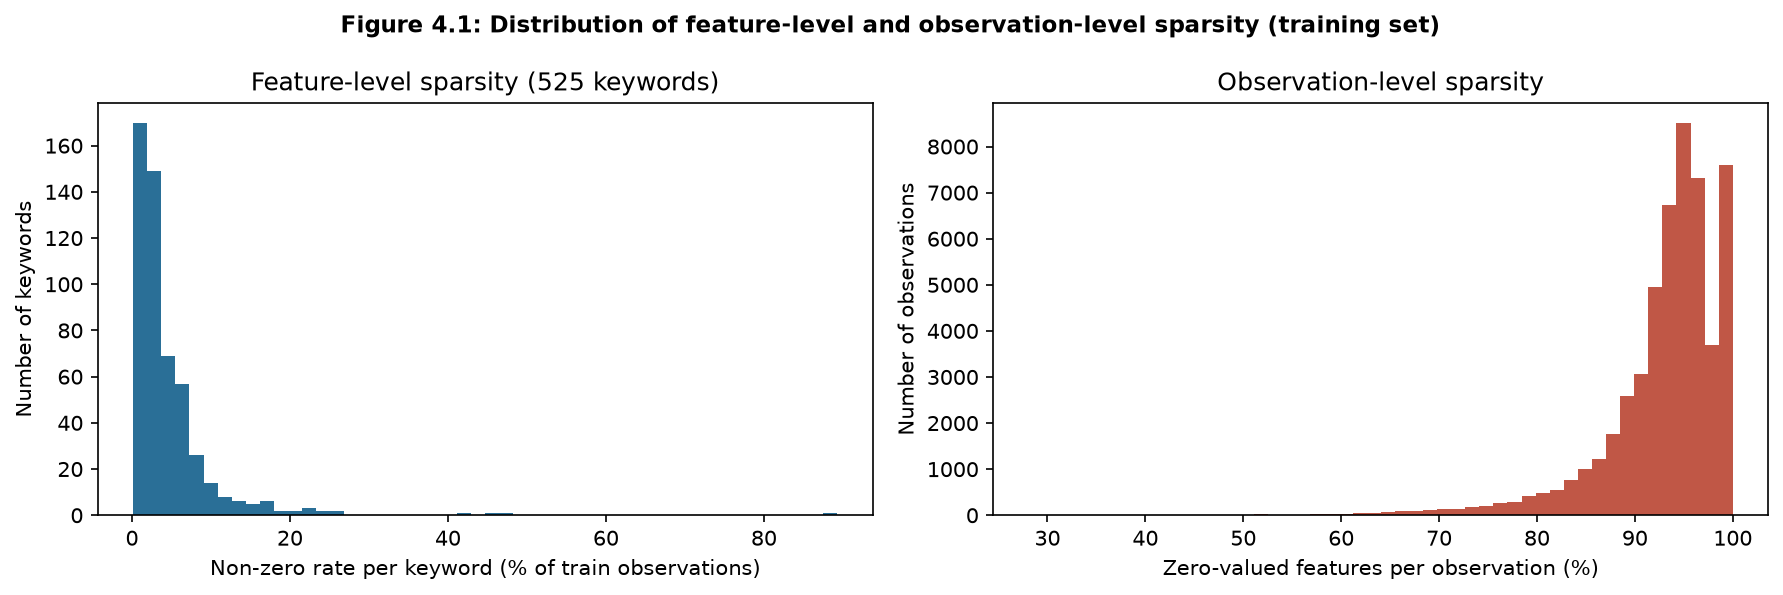

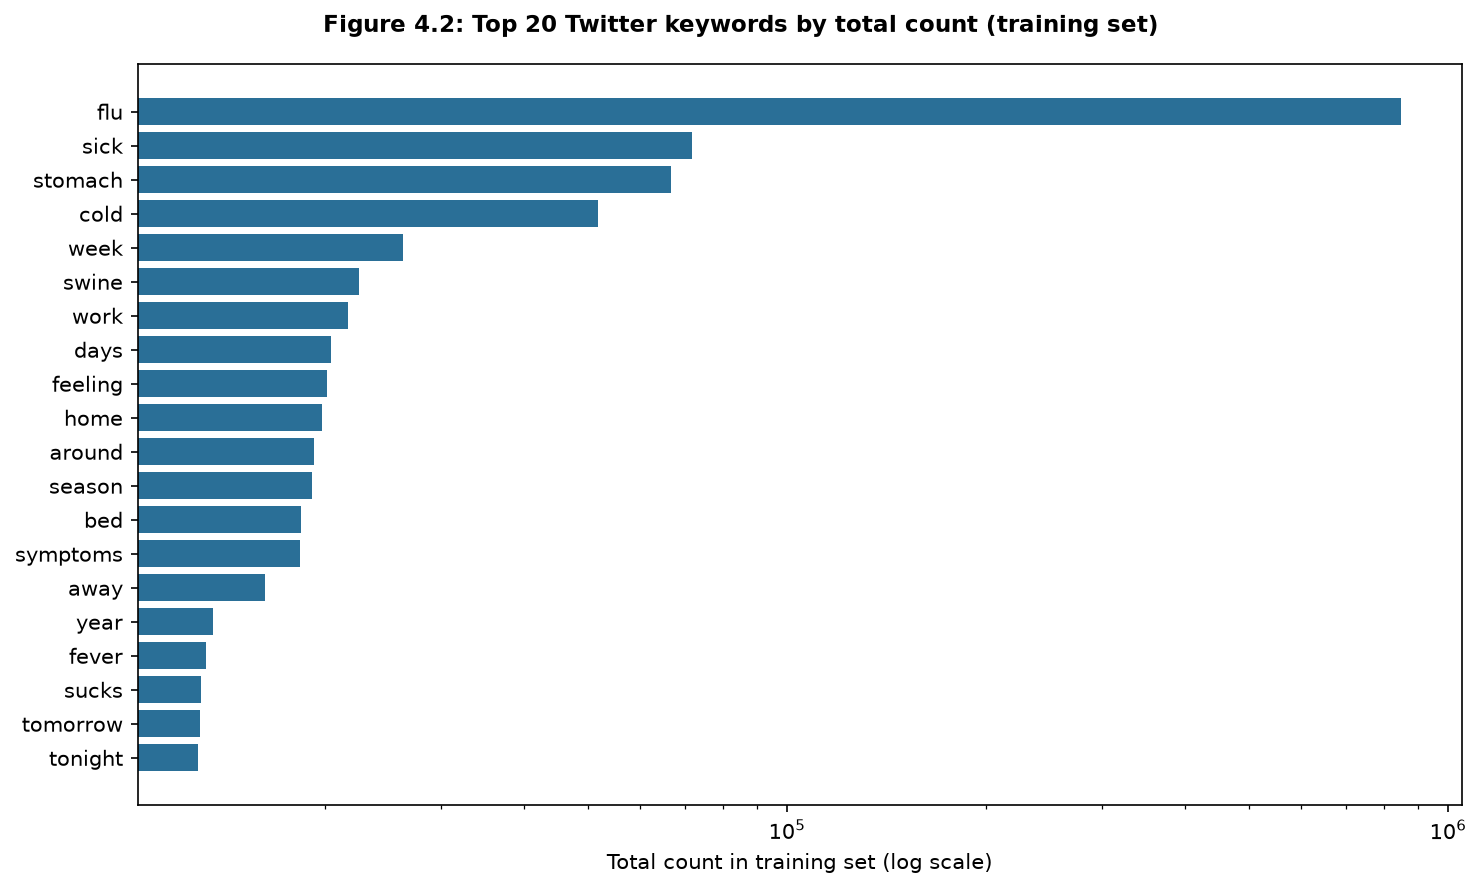

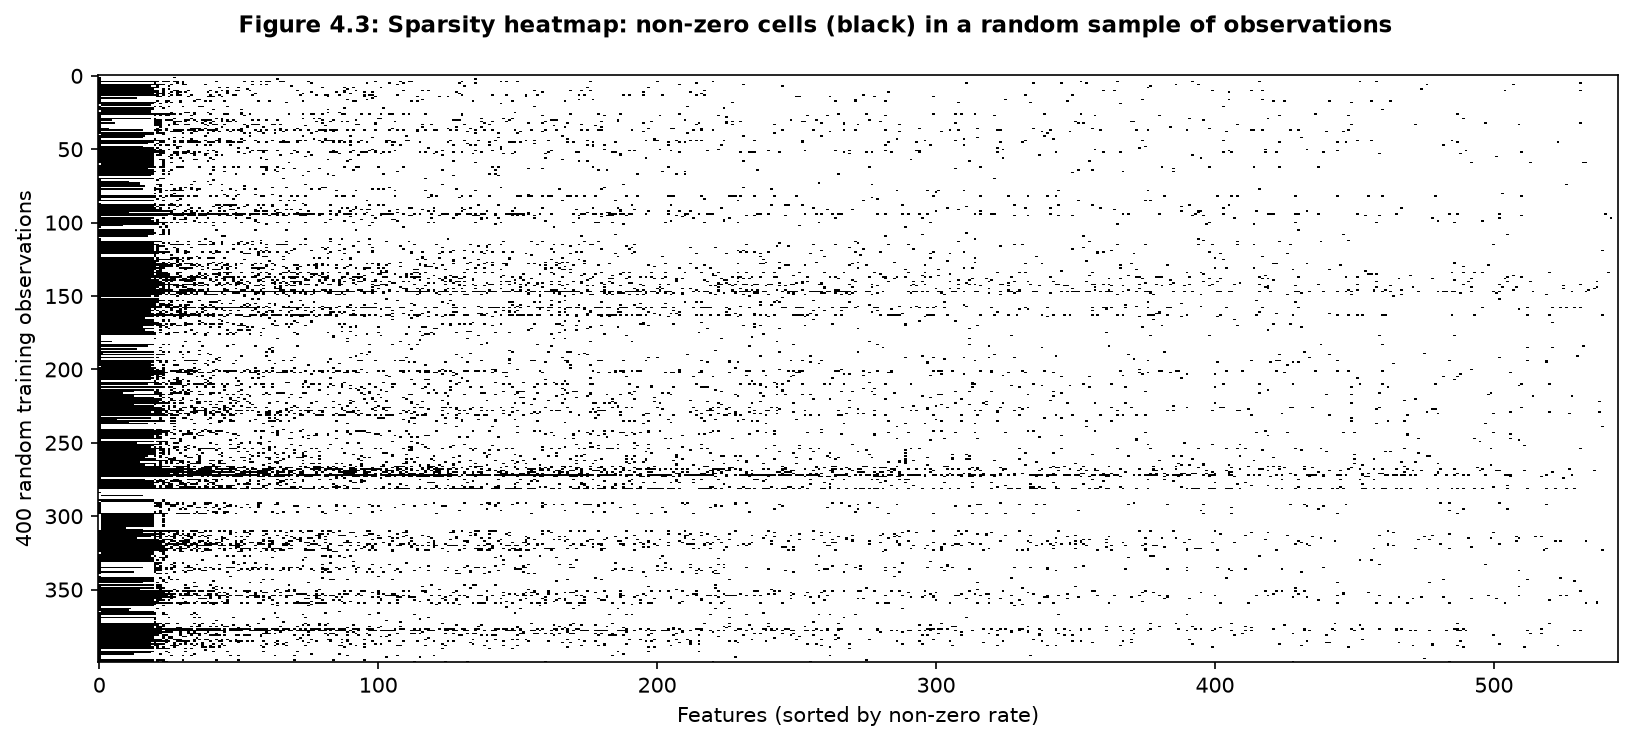

'figures/fig4_03_sparsity_heatmap.png'

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(feat_nz[N_AUX:] * 100, bins=50, color="#2a6f97")
ax[0].set_xlabel("Non-zero rate per keyword (% of train observations)"); ax[0].set_ylabel("Number of keywords")
ax[0].set_title("Feature-level sparsity (525 keywords)")
ax[1].hist(obs_zero * 100, bins=50, color="#c05746")
ax[1].set_xlabel("Zero-valued features per observation (%)"); ax[1].set_ylabel("Number of observations")
ax[1].set_title("Observation-level sparsity")
save_fig(fig, "sparsity_histograms", "Distribution of feature-level and observation-level sparsity (training set)")

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_kw["feature"][::-1], top_kw["total_count_train"][::-1], color="#2a6f97")
ax.set_xscale("log"); ax.set_xlabel("Total count in training set (log scale)")
save_fig(fig, "top_keywords", "Top 20 Twitter keywords by total count (training set)")

rng = np.random.default_rng(SEED)
rows = np.sort(rng.choice(X_tr.shape[0], 400, replace=False))
order = np.argsort(-feat_nz)
fig, ax = plt.subplots(figsize=(11, 5))
ax.imshow((X_tr[rows][:, order].toarray() != 0), aspect="auto", cmap="Greys", interpolation="nearest")
ax.set_xlabel("Features (sorted by non-zero rate)"); ax.set_ylabel("400 random training observations")
save_fig(fig, "sparsity_heatmap", "Sparsity heatmap: non-zero cells (black) in a random sample of observations")

## 3. Class imbalance analysis (proposal 3.3.2)

In [10]:
def imb(y): pos = int(y.sum()); neg = int(len(y) - pos); return dict(n=len(y), positives=pos, negatives=neg, prevalence=pos/len(y), imbalance_ratio=neg/pos if pos else np.inf)
IMB = pd.DataFrame({"train": imb(y_tr), "test": imb(y_te), "all": imb(np.r_[y_tr, y_te])}).T
display(IMB)
by_state = pd.DataFrame({
    "train_prevalence": meta_tr.groupby("state")["y"].mean(), "test_prevalence": meta_te.groupby("state")["y"].mean(),
    "train_pos": meta_tr.groupby("state")["y"].sum(), "test_pos": meta_te.groupby("state")["y"].sum()})
by_state["train_IR"] = (1 - by_state.train_prevalence) / by_state.train_prevalence.replace(0, np.nan)
by_state["test_IR"] = (1 - by_state.test_prevalence) / by_state.test_prevalence.replace(0, np.nan)
by_state = by_state.sort_values("train_prevalence", ascending=False)
by_state.to_csv(os.path.join(RES_DIR, "imbalance_by_state.csv"))
IMB.to_csv(os.path.join(RES_DIR, "imbalance_by_split.csv"))
print("States with zero positives in train:", list(by_state.index[by_state.train_pos == 0]))
print("States with zero positives in test:", list(by_state.index[by_state.test_pos == 0]))
display(by_state.head(10))

,n,positives,negatives,prevalence,imbalance_ratio
train,52560.0,2905.0,49655.0,0.055270,17.092943
test,23280.0,2282.0,20998.0,0.098024,9.201578
all,75840.0,5187.0,70653.0,0.068394,13.621168


States with zero positives in train: []
States with zero positives in test: ['new hampshire', 'maine']


,train_prevalence,test_prevalence,train_pos,test_pos,train_IR,test_IR
state,,,,,,
alabama,0.226484,0.280412,248,136,3.415323,2.566176
texas,0.156164,0.294845,171,143,5.403509,2.391608
louisiana,0.149772,0.237113,164,115,5.676829,3.217391
mississippi,0.143379,0.280412,157,136,5.974522,2.566176
oklahoma,0.124201,0.294845,136,143,7.051471,2.391608
arkansas,0.105023,0.251546,115,122,8.521739,2.975410
missouri,0.105023,0.107216,115,52,8.521739,8.326923
virginia,0.098630,0.179381,108,87,9.138889,4.574713
new jersey,0.095890,0.043299,105,21,9.428571,22.095238


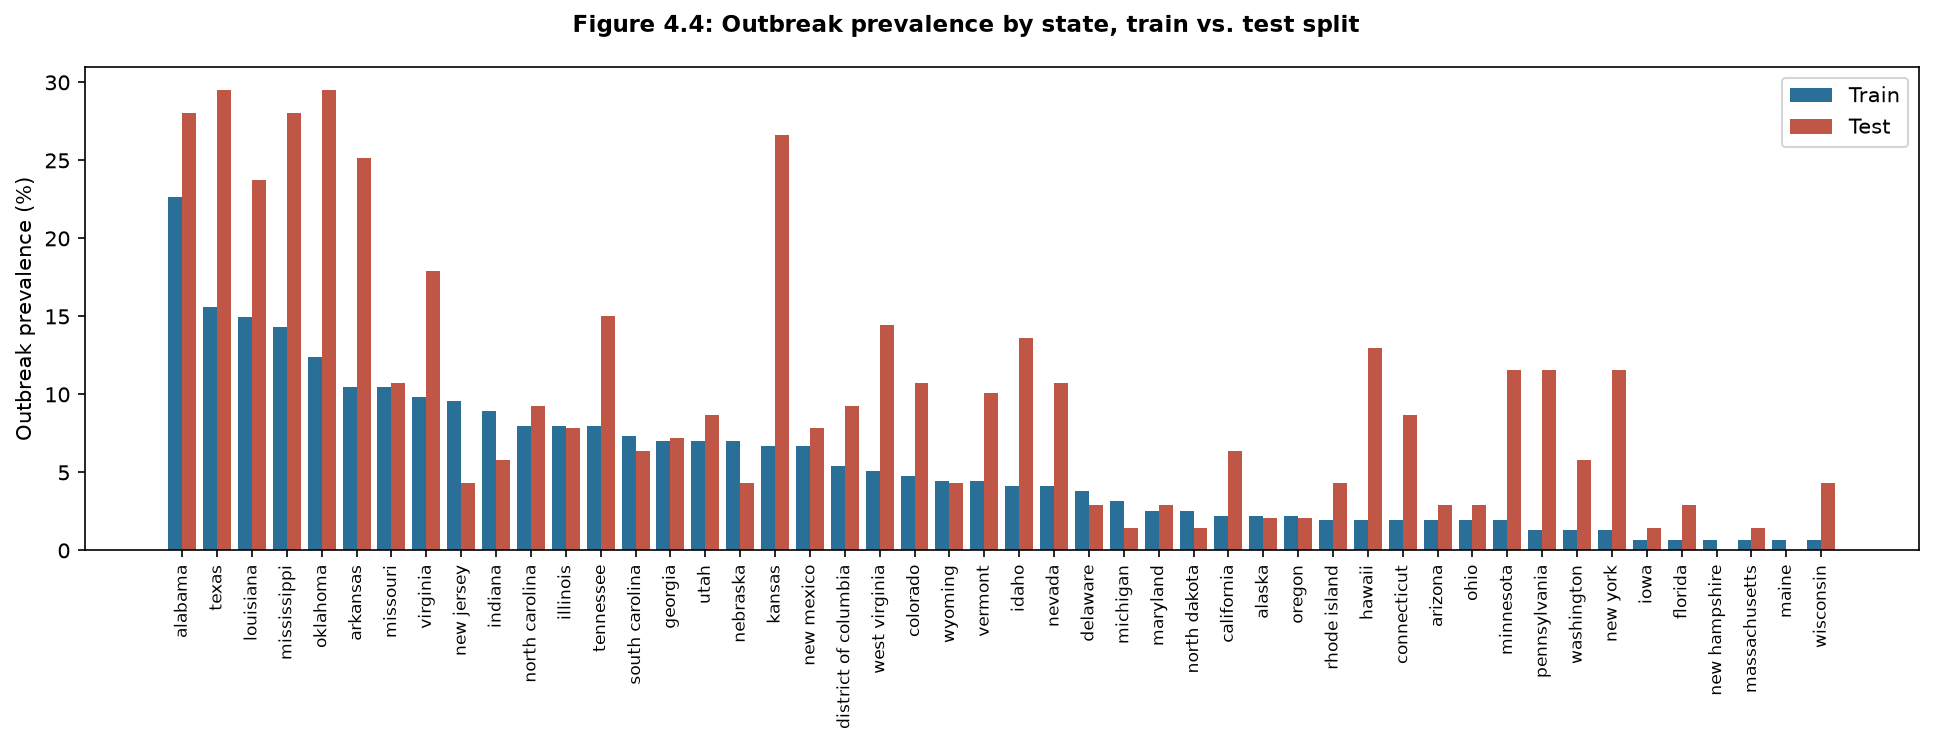

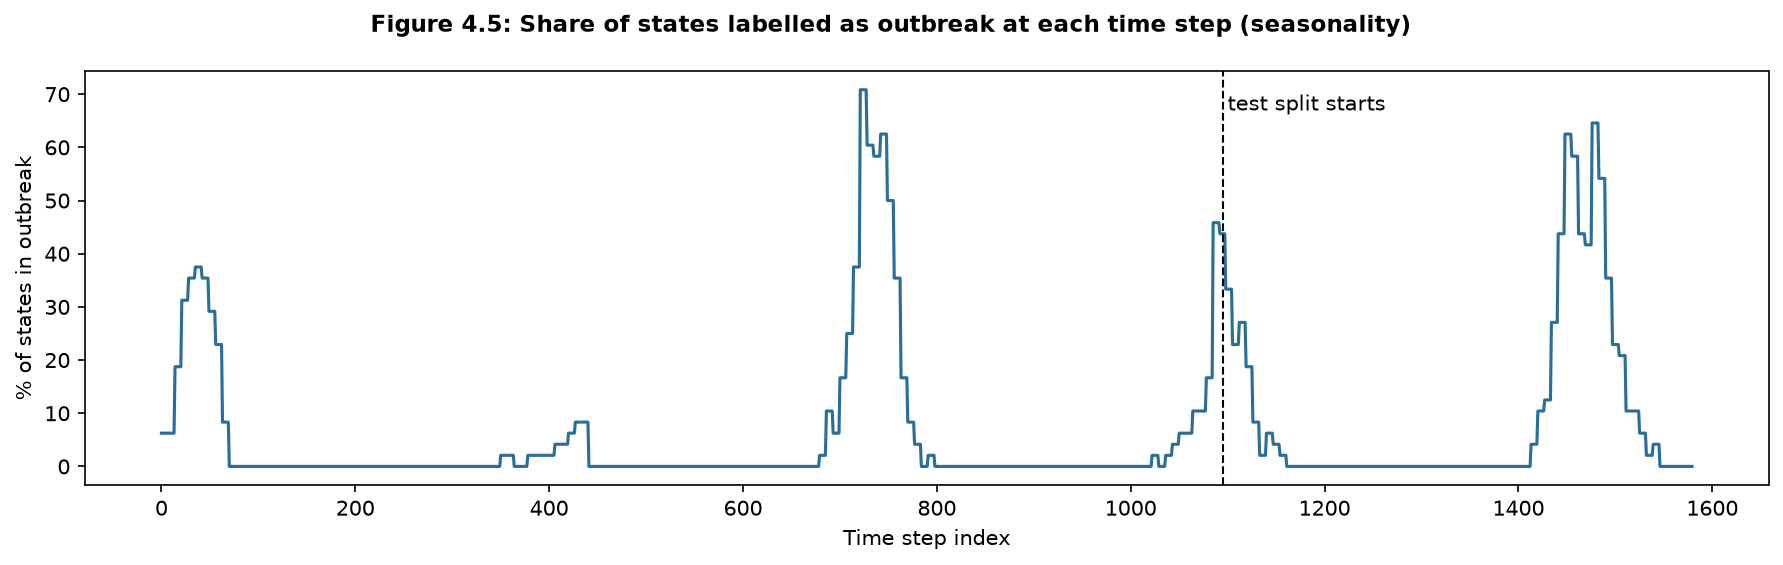

'figures/fig4_05_prevalence_over_time.png'

In [11]:
fig, ax = plt.subplots(figsize=(13, 5))
xx = np.arange(len(by_state))
ax.bar(xx - 0.2, by_state.train_prevalence * 100, 0.4, label="Train", color="#2a6f97")
ax.bar(xx + 0.2, by_state.test_prevalence * 100, 0.4, label="Test", color="#c05746")
ax.set_xticks(xx); ax.set_xticklabels(by_state.index, rotation=90, fontsize=8)
ax.set_ylabel("Outbreak prevalence (%)"); ax.legend()
save_fig(fig, "prevalence_by_state", "Outbreak prevalence by state, train vs. test split")

prev_t = pd.concat([meta_tr, meta_te]).groupby("t")["y"].mean()
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(prev_t.index, prev_t.values * 100, color="#2a6f97")
ax.axvline(DATASET["steps_train"], color="k", ls="--", lw=1); ax.text(DATASET["steps_train"] + 5, ax.get_ylim()[1] * 0.9, "test split starts")
ax.set_xlabel("Time step index"); ax.set_ylabel("% of states in outbreak")
save_fig(fig, "prevalence_over_time", "Share of states labelled as outbreak at each time step (seasonality)")

## 4. Preprocessing comparison (proposal 3.3.3)
The proposal compares min-max scaling with TF-IDF weighting. Counts are non-negative and the minimum of every column is 0, so
`MaxAbsScaler` is the same as min-max scaling, and it keeps the matrix sparse. A log1p transform followed by max-abs scaling is
added as a third option. All three are compared with an L2 logistic regression (class weights balanced) using
5-fold stratified CV PR-AUC on the training set.

In [12]:
PREPROC = {
    "minmax (MaxAbs)": lambda: [("scale", MaxAbsScaler())],
    "log1p + MaxAbs": lambda: [("log", FunctionTransformer(sparse_log1p, accept_sparse=True)), ("scale", MaxAbsScaler())],
    "TF-IDF": lambda: [("tfidf", TfidfTransformer())],
}
pre_rows = []
for name, steps in PREPROC.items():
    pipe = Pipeline(steps() + [("clf", LogisticRegression(C=1.0, class_weight="balanced", max_iter=3000, solver="liblinear", random_state=SEED))])
    p = cross_val_predict(pipe, X_tr, y_tr, cv=CV, method="predict_proba", n_jobs=N_JOBS)[:, 1]
    pre_rows.append(dict(preprocessing=name, cv_pr_auc=average_precision_score(y_tr, p), cv_roc_auc=roc_auc_score(y_tr, p)))
PRE = pd.DataFrame(pre_rows).sort_values("cv_pr_auc", ascending=False)
PRE.to_csv(os.path.join(RES_DIR, "preprocessing_comparison.csv"), index=False)
display(PRE)
BEST_PRE = PRE.iloc[0]["preprocessing"]
print("Selected preprocessing for linear models / MLP:", BEST_PRE)
def lin_pre(): return PREPROC[BEST_PRE]()

,preprocessing,cv_pr_auc,cv_roc_auc
1,log1p + MaxAbs,0.352975,0.819500
0,minmax (MaxAbs),0.331080,0.804100
2,TF-IDF,0.305331,0.817584


Selected preprocessing for linear models / MLP: log1p + MaxAbs


## 5–7. Models, tuning and test-set evaluation
**Protocol.**
* Hyperparameters are tuned with 5-fold **stratified** CV on the training split, scored by PR-AUC (`average_precision`).
* The decision threshold for F1, precision, recall, MCC and balanced accuracy is set **on training data only**: it is the
  threshold that maximises F1 on the out-of-fold (OOF) CV predictions of the tuned model. It is then applied unchanged to the test split.
* The provided **test split** (the later 485 time steps of every state) is used only for the final evaluation.
* Caveat: shuffled stratified CV on overlapping, autocorrelated time steps can leak information, so CV scores are optimistic.
  Section 10 adds a forward-chaining temporal validation to check this.

In [13]:
RESULTS, PROBS, MODELS, THRESH, TIMES, CVBEST = {}, {}, {}, {}, {}, {}

def best_f1_threshold(y, p):
    pr, rc, th = precision_recall_curve(y, p)
    f1 = 2 * pr * rc / np.clip(pr + rc, 1e-12, None)
    i = int(np.nanargmax(f1[:-1])) if len(th) else 0
    return float(th[i]) if len(th) else 0.5

def metrics(y, p, thr):
    yh = (p >= thr).astype(int)
    return dict(pr_auc=average_precision_score(y, p), roc_auc=roc_auc_score(y, p), f1=f1_score(y, yh, zero_division=0),
                precision=precision_score(y, yh, zero_division=0), recall=recall_score(y, yh, zero_division=0),
                mcc=matthews_corrcoef(y, yh), balanced_acc=balanced_accuracy_score(y, yh), accuracy=accuracy_score(y, yh),
                brier=brier_score_loss(y, p), threshold=thr)

def run_model(name, family, estimator, grid, Xtr=None, Xte=None, oof=True):
    """Tune with stratified CV, set the threshold from OOF predictions, refit on all training data and evaluate on test."""
    Xtr = X_tr if Xtr is None else Xtr; Xte = X_te if Xte is None else Xte
    t0 = time.time()
    if grid:
        gs = GridSearchCV(estimator, grid, scoring="average_precision", cv=CV, n_jobs=1 if family == "ML-heavy" else N_JOBS, refit=False)
        gs.fit(Xtr, y_tr)
        best = gs.best_params_; CVBEST[name] = dict(best_params=str(best), cv_pr_auc=gs.best_score_)
        estimator.set_params(**best)
    tune_time = time.time() - t0
    if oof:
        p_oof = cross_val_predict(estimator, Xtr, y_tr, cv=CV, method="predict_proba", n_jobs=1 if family == "ML-heavy" else N_JOBS)[:, 1]
        thr = best_f1_threshold(y_tr, p_oof)
        CVBEST.setdefault(name, {})["oof_pr_auc"] = average_precision_score(y_tr, p_oof)
    t0 = time.time(); estimator.fit(Xtr, y_tr); fit_time = time.time() - t0
    t0 = time.time(); p = estimator.predict_proba(Xte)[:, 1]; pred_time = time.time() - t0
    if not oof:
        thr = best_f1_threshold(y_tr, estimator.predict_proba(Xtr)[:, 1])
    RESULTS[name] = dict(family="ML" if family.startswith("ML") else family, **metrics(y_te, p, thr))
    PROBS[name], MODELS[name], THRESH[name] = p, estimator, thr
    TIMES[name] = dict(tuning_s=tune_time, fit_s=fit_time, predict_test_s=pred_time, predict_per_1k_ms=1000 * pred_time / Xte.shape[0] * 1000)
    print(f"{name:28s} test PR-AUC={RESULTS[name]['pr_auc']:.4f} ROC-AUC={RESULTS[name]['roc_auc']:.4f} F1={RESULTS[name]['f1']:.4f} "
          f"| fit {fit_time:.1f}s | {CVBEST.get(name, {}).get('best_params', '')}")
    return estimator

### 5. Statistical models (RQ2)
**5.1 Logistic regression with L1 (Lasso) and L2 (Ridge)**, with class weights balanced and C tuned by CV.

In [14]:
run_model("LogReg-L1", "Statistical",
          Pipeline(lin_pre() + [("clf", LogisticRegression(penalty="l1", solver="liblinear", class_weight="balanced", max_iter=5000, random_state=SEED))]),
          {"clf__C": [0.01, 0.1, 1.0, 10.0]})
run_model("LogReg-L2", "Statistical",
          Pipeline(lin_pre() + [("clf", LogisticRegression(penalty="l2", solver="liblinear", class_weight="balanced", max_iter=5000, random_state=SEED))]),
          {"clf__C": [0.001, 0.01, 0.1, 1.0, 10.0]})

LogReg-L1                    test PR-AUC=0.3761 ROC-AUC=0.7947 F1=0.3639 | fit 4.0s | {'clf__C': 0.1}


LogReg-L2                    test PR-AUC=0.3708 ROC-AUC=0.7929 F1=0.3828 | fit 0.3s | {'clf__C': 0.1}


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('log', ...), ('scale', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,545
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function spa...x7f76da3a8ea0>
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",True
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False


**5.2 Poisson and Negative Binomial count models.** These follow proposal 3.4.1. The response is the *total keyword count*
per observation (the sum of the 525 keyword columns). The GLM is `count ~ C(state) + outbreak`, and the binary outcome comes
from the predicted counts using Bayes' rule:
P(y=1 | count, state) ∝ f(count | μ(state, y=1)) · π, where f is the Poisson or NB pmf and π is the training prevalence.
This tests whether aggregate tweet *volume* predicts outbreaks independently of which keywords are used.
The NB dispersion α is estimated by maximum likelihood (statsmodels `NegativeBinomial`).

In [15]:
state_to_idx = {s: i for i, s in enumerate(states)}
sidx_tr = np.array([state_to_idx[s] for s in state_tr]); sidx_te = np.array([state_to_idx[s] for s in state_te])
for fam, name in (("poisson", "Poisson-count"), ("negbin", "NegBin-count")):
    t0 = time.time(); m = CountGLMClassifier(fam, N_AUX).fit(X_tr, y_tr, sidx_tr, len(states)); fit_time = time.time() - t0
    # threshold from 5-fold OOF on train
    p_oof = np.zeros(len(y_tr))
    for a, b in CV.split(X_tr, y_tr):
        p_oof[b] = CountGLMClassifier(fam, N_AUX).fit(X_tr[a], y_tr[a], sidx_tr[a], len(states)).predict_proba(X_tr[b], sidx_tr[b])[:, 1]
    thr = best_f1_threshold(y_tr, p_oof)
    t0 = time.time(); p = m.predict_proba(X_te, sidx_te)[:, 1]; pred_time = time.time() - t0
    RESULTS[name] = dict(family="Statistical", **metrics(y_te, p, thr)); PROBS[name], MODELS[name], THRESH[name] = p, m, thr
    TIMES[name] = dict(tuning_s=0.0, fit_s=fit_time, predict_test_s=pred_time, predict_per_1k_ms=1000 * pred_time / X_te.shape[0] * 1000)
    CVBEST[name] = dict(best_params="n/a", oof_pr_auc=average_precision_score(y_tr, p_oof))
    print(f"{name}: outbreak coefficient (log rate ratio) = {m.params_[-1]:.4f}" + (f", NB alpha = {m.alpha_:.4f}" if m.alpha_ else ""),
          f"| test PR-AUC={RESULTS[name]['pr_auc']:.4f}")
COUNT_COEFS = {n: dict(outbreak_log_rate_ratio=float(MODELS[n].params_[-1]), rate_ratio=float(np.exp(MODELS[n].params_[-1])),
                       nb_alpha=MODELS[n].alpha_) for n in ("Poisson-count", "NegBin-count")}
COUNT_COEFS

Poisson-count: outbreak coefficient (log rate ratio) = 1.3278 | test PR-AUC=0.2716


NegBin-count: outbreak coefficient (log rate ratio) = 1.2628, NB alpha = 0.6168 | test PR-AUC=0.3076


{'Poisson-count': {'outbreak_log_rate_ratio': 1.3278043608988386,
  'rate_ratio': 3.7727506880829447,
  'nb_alpha': None},
 'NegBin-count': {'outbreak_log_rate_ratio': 1.2628468868206,
  'rate_ratio': 3.535472263257271,
  'nb_alpha': 0.6168239070827136}}

**5.3 Bayesian logistic regression with a horseshoe prior (PyMC).** Full-data NUTS over all 545 features was **not feasible**
on the available hardware: a 50-feature NUTS test run with 400 iterations did not finish within ~11 minutes. The closest honest alternative is used here:
* the top **K = 50** features by χ² (fitted on training data only) after log1p, then standardised;
* a non-centred horseshoe prior: β = z·λ·τ, z ~ N(0,1), λ ~ HalfCauchy(1), τ ~ HalfCauchy(1), α ~ N(0,5);
* posterior approximated with **mean-field ADVI** (30,000 iterations, then 1,000 posterior draws). ADVI tends to underestimate posterior variance.
* The threshold is set on training-set posterior-mean predictions (no OOF), because refitting 5 times is costly.
  This is noted as a caveat.

If PyMC is not installed, the cell falls back to a Laplace (Gaussian) approximation around an L2-penalised MAP estimate.

In [16]:
BAYES_K = 50
Xl_tr = X_tr.copy(); Xl_tr.data = np.log1p(Xl_tr.data)
sel = SelectKBest(chi2, k=BAYES_K).fit(Xl_tr, y_tr); bidx = np.sort(np.where(sel.get_support())[0])
Zr = np.log1p(X_tr[:, bidx].toarray()); bmu, bsd = Zr.mean(0), Zr.std(0) + 1e-9; Z = (Zr - bmu) / bsd
t0 = time.time()
try:
    import pymc as pm
    with pm.Model() as bayes_model:
        tau = pm.HalfCauchy("tau", 1.0); lam = pm.HalfCauchy("lam", 1.0, shape=BAYES_K)
        z = pm.Normal("z", 0, 1, shape=BAYES_K); beta = pm.Deterministic("beta", z * lam * tau)
        alpha = pm.Normal("alpha", 0, 5)
        pm.Bernoulli("obs", logit_p=alpha + pm.math.dot(Z, beta), observed=y_tr)
        approx = pm.fit(30000, method="advi", random_seed=SEED, progressbar=False)
        idata = approx.sample(1000, random_seed=SEED)
    a_draws = idata.posterior["alpha"].values.reshape(-1); b_draws = idata.posterior["beta"].values.reshape(-1, BAYES_K)
    BAYES_METHOD = f"PyMC {pm.__version__} horseshoe prior, mean-field ADVI (30k iters, 1000 draws), top-{BAYES_K} chi2 features"
except ImportError:
    lr = LogisticRegression(C=1.0, max_iter=5000).fit(Z, y_tr)
    w = np.r_[lr.intercept_, lr.coef_.ravel()]; Zb = np.c_[np.ones(len(Z)), Z]; pp = lr.predict_proba(Z)[:, 1]
    H = (Zb * (pp * (1 - pp))[:, None]).T @ Zb + np.eye(len(w)); cov = np.linalg.inv(H)
    dr = np.random.default_rng(SEED).multivariate_normal(w, cov, 1000); a_draws, b_draws = dr[:, 0], dr[:, 1:]
    BAYES_METHOD = f"Laplace approximation (PyMC unavailable), top-{BAYES_K} chi2 features"
fit_time = time.time() - t0
bayes = BayesLogRegPosterior(bidx, bmu, bsd, a_draws, b_draws, [feature_names[i] for i in bidx])
thr = best_f1_threshold(y_tr, bayes.predict_proba(X_tr)[:, 1])
t0 = time.time(); (pb, P_draws) = bayes.predict_proba(X_te, return_draws=True); pred_time = time.time() - t0
p = pb[:, 1]
RESULTS["Bayesian-LR (horseshoe)"] = dict(family="Statistical", **metrics(y_te, p, thr))
PROBS["Bayesian-LR (horseshoe)"], MODELS["Bayesian-LR (horseshoe)"], THRESH["Bayesian-LR (horseshoe)"] = p, bayes, thr
TIMES["Bayesian-LR (horseshoe)"] = dict(tuning_s=0.0, fit_s=fit_time, predict_test_s=pred_time, predict_per_1k_ms=1000 * pred_time / X_te.shape[0] * 1000)
CVBEST["Bayesian-LR (horseshoe)"] = dict(best_params=BAYES_METHOD)
ci_width = np.percentile(P_draws, 97.5, axis=1) - np.percentile(P_draws, 2.5, axis=1)
BAYES_UNC = dict(mean_95ci_width=float(ci_width.mean()), mean_95ci_width_pos=float(ci_width[y_te == 1].mean()), mean_95ci_width_neg=float(ci_width[y_te == 0].mean()))
print(BAYES_METHOD, "| fit", round(fit_time, 1), "s | test PR-AUC", round(RESULTS["Bayesian-LR (horseshoe)"]["pr_auc"], 4), "|", BAYES_UNC)

Finished [100%]: Average Loss = 9,675.6


PyMC 6.4.0 horseshoe prior, mean-field ADVI (30k iters, 1000 draws), top-50 chi2 features | fit 91.6 s | test PR-AUC 0.2994 | {'mean_95ci_width': 0.035471194500449214, 'mean_95ci_width_pos': 0.08437376192244726, 'mean_95ci_width_neg': 0.03015660935629265}


### 6. Machine learning models (RQ3)
* **Random Forest**: `class_weight="balanced_subsample"`, 200 trees, max_features="sqrt"; tuned over max depth and min samples per leaf.
* **XGBoost** and **LightGBM**: both use `scale_pos_weight = neg/pos` and sparse-aware histogram training; tuned over learning rate, depth and number of estimators, with subsample 0.8.
* **MLP**: two hidden layers (128, 64), early stopping on a 10% validation split, and L2 penalty α tuned. scikit-learn's MLP has
  no dropout or class weights, so the L2 penalty takes the place of dropout and **random oversampling** handles imbalance inside the pipeline (imblearn).
  This is a documented deviation from the proposal.

In [17]:
spw = float((y_tr == 0).sum() / (y_tr == 1).sum())
run_model("RandomForest", "ML-heavy",
          RandomForestClassifier(n_estimators=200, max_features="sqrt", class_weight="balanced_subsample", n_jobs=N_JOBS, random_state=SEED),
          {"max_depth": [None, 20], "min_samples_leaf": [1, 5]})
run_model("XGBoost", "ML-heavy",
          xgb.XGBClassifier(tree_method="hist", subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw, eval_metric="aucpr",
                            n_jobs=N_JOBS, random_state=SEED, verbosity=0),
          {"learning_rate": [0.05, 0.1], "max_depth": [4, 6], "n_estimators": [200, 400]})
run_model("LightGBM", "ML-heavy",
          lgb.LGBMClassifier(subsample=0.8, subsample_freq=1, colsample_bytree=0.8, scale_pos_weight=spw, n_jobs=N_JOBS,
                             random_state=SEED, verbose=-1),
          {"learning_rate": [0.05, 0.1], "num_leaves": [15, 63], "n_estimators": [200, 400]})
run_model("MLP", "ML",
          ImbPipeline(lin_pre() + [("ros", RandomOverSampler(random_state=SEED)),
                                   ("clf", MLPClassifier(hidden_layer_sizes=(128, 64), early_stopping=True, validation_fraction=0.1,
                                                         max_iter=200, n_iter_no_change=10, random_state=SEED))]),
          {"clf__alpha": [1e-4, 1e-3, 1e-2]})

RandomForest                 test PR-AUC=0.3340 ROC-AUC=0.7433 F1=0.3176 | fit 10.4s | {'max_depth': None, 'min_samples_leaf': 5}


XGBoost                      test PR-AUC=0.3809 ROC-AUC=0.7827 F1=0.3713 | fit 0.7s | {'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 400}


LightGBM                     test PR-AUC=0.3823 ROC-AUC=0.7887 F1=0.3956 | fit 0.8s | {'learning_rate': 0.05, 'n_estimators': 400, 'num_leaves': 15}


MLP                          test PR-AUC=0.1855 ROC-AUC=0.5368 F1=0.2169 | fit 46.5s | {'clf__alpha': 0.001}


,steps,"[('log', ...), ('scale', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
n_features_in_,int,545
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function spa...x7f76da3a8ea0>
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",True
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False


### 7. Test-set results

In [18]:
RES = pd.DataFrame(RESULTS).T
num_cols = ["pr_auc", "roc_auc", "f1", "precision", "recall", "mcc", "balanced_acc", "accuracy", "brier", "threshold"]
RES[num_cols] = RES[num_cols].astype(float)
RES = RES.sort_values("pr_auc", ascending=False)
RES.to_csv(os.path.join(RES_DIR, "test_results.csv"))
CVB = pd.DataFrame(CVBEST).T; CVB.to_csv(os.path.join(RES_DIR, "cv_tuning.csv"))
display(RES.round(4)); display(CVB)
lower_better = {"brier"}
BEST_PER_METRIC = {m: (RES[m].idxmin() if m in lower_better else RES[m].idxmax()) for m in num_cols if m not in ("threshold", "accuracy")}
STAT_NAMES = [n for n in RES.index if RES.loc[n, "family"] == "Statistical"]
ML_NAMES = [n for n in RES.index if RES.loc[n, "family"] == "ML"]
BEST_STAT = RES.loc[STAT_NAMES, "pr_auc"].idxmax(); BEST_ML = RES.loc[ML_NAMES, "pr_auc"].idxmax()
print("Best per metric:", BEST_PER_METRIC); print("Best statistical (PR-AUC):", BEST_STAT, "| best ML (PR-AUC):", BEST_ML)

,family,pr_auc,roc_auc,f1,precision,recall,mcc,balanced_acc,accuracy,brier,threshold
LightGBM,ML,0.3823,0.7887,0.3956,0.4374,0.3611,0.3386,0.6553,0.8918,0.1350,0.7007
XGBoost,ML,0.3809,0.7827,0.3713,0.4808,0.3024,0.3300,0.6334,0.8996,0.1362,0.7282
LogReg-L1,Statistical,0.3761,0.7947,0.3639,0.4661,0.2984,0.3203,0.6306,0.8977,0.1530,0.7856
LogReg-L2,Statistical,0.3708,0.7929,0.3828,0.4215,0.3506,0.3241,0.6491,0.8892,0.1544,0.7381
RandomForest,ML,0.3340,0.7433,0.3176,0.4672,0.2406,0.2863,0.6054,0.8987,0.0893,0.3986
NegBin-count,Statistical,0.3076,0.7926,0.2139,0.4377,0.1415,0.2067,0.5609,0.8980,0.0871,0.1492
Bayesian-LR (horseshoe),Statistical,0.2994,0.7477,0.2904,0.4158,0.2230,0.2518,0.5945,0.8931,0.0839,0.1207
Poisson-count,Statistical,0.2716,0.7027,0.2301,0.5105,0.1486,0.2377,0.5665,0.9026,0.1003,1.0000
MLP,ML,0.1855,0.5368,0.2169,0.4415,0.1437,0.2097,0.5620,0.8982,0.1061,0.8465


,best_params,cv_pr_auc,oof_pr_auc
LogReg-L1,{'clf__C': 0.1},0.370419,0.370008
LogReg-L2,{'clf__C': 0.1},0.366089,0.36504
Poisson-count,n/a,NaN,0.349189
NegBin-count,n/a,NaN,0.399509
Bayesian-LR (horseshoe),"PyMC 6.4.0 horseshoe prior, mean-field ADVI (3...",NaN,NaN
RandomForest,"{'max_depth': None, 'min_samples_leaf': 5}",0.333764,0.332604
XGBoost,"{'learning_rate': 0.05, 'max_depth': 4, 'n_est...",0.372347,0.371122
LightGBM,"{'learning_rate': 0.05, 'n_estimators': 400, '...",0.385014,0.384338
MLP,{'clf__alpha': 0.001},0.204572,0.203593


Best per metric: {'pr_auc': 'LightGBM', 'roc_auc': 'LogReg-L1', 'f1': 'LightGBM', 'precision': 'Poisson-count', 'recall': 'LightGBM', 'mcc': 'LightGBM', 'balanced_acc': 'LightGBM', 'brier': 'Bayesian-LR (horseshoe)'}
Best statistical (PR-AUC): LogReg-L1 | best ML (PR-AUC): LightGBM


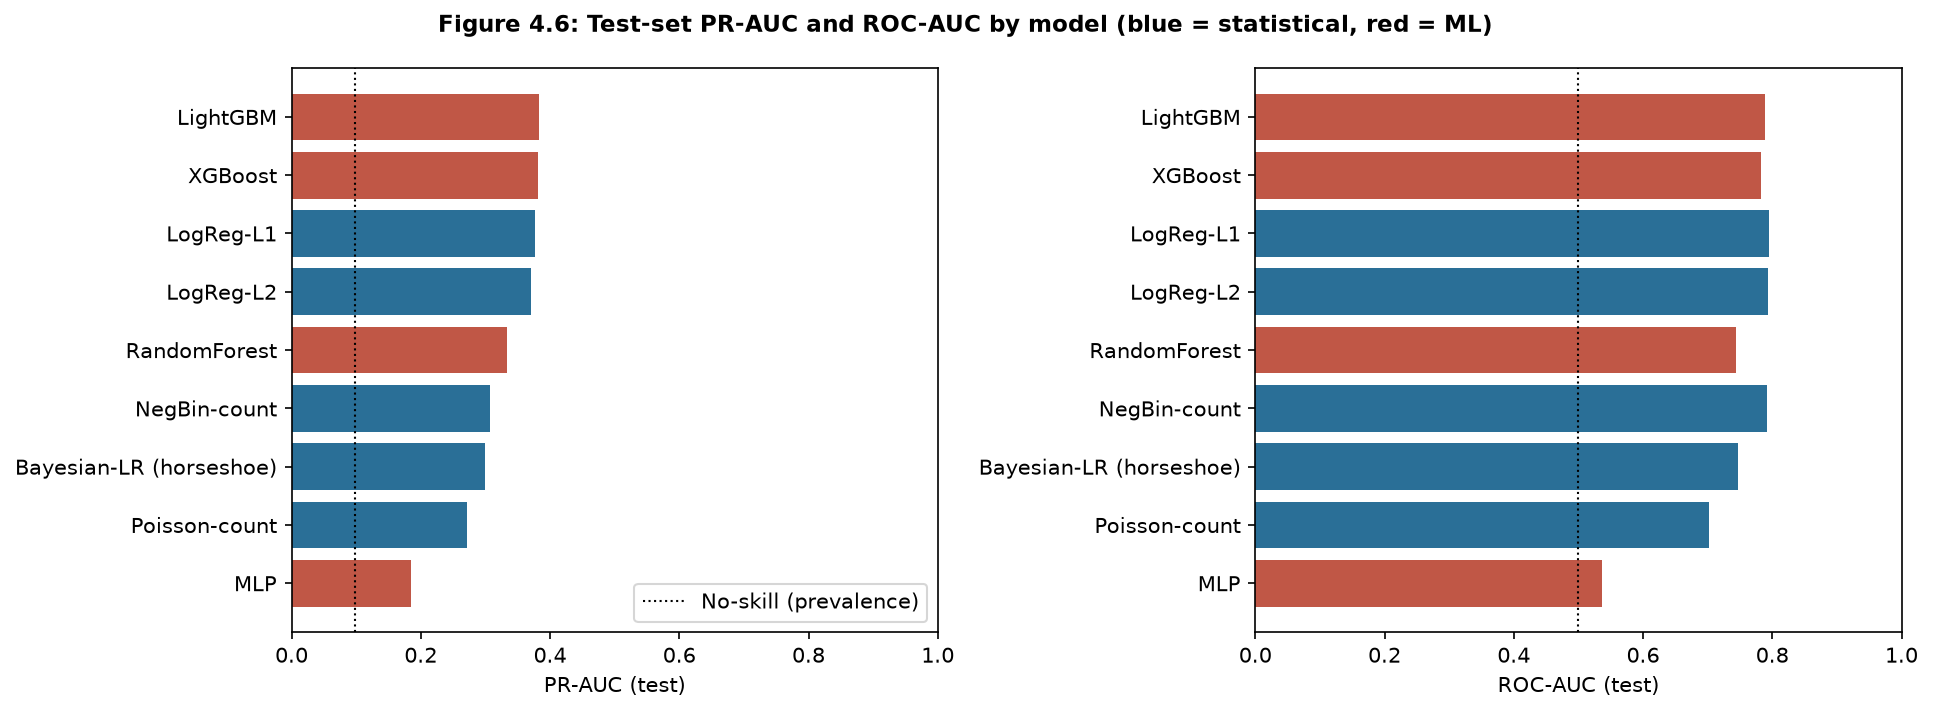

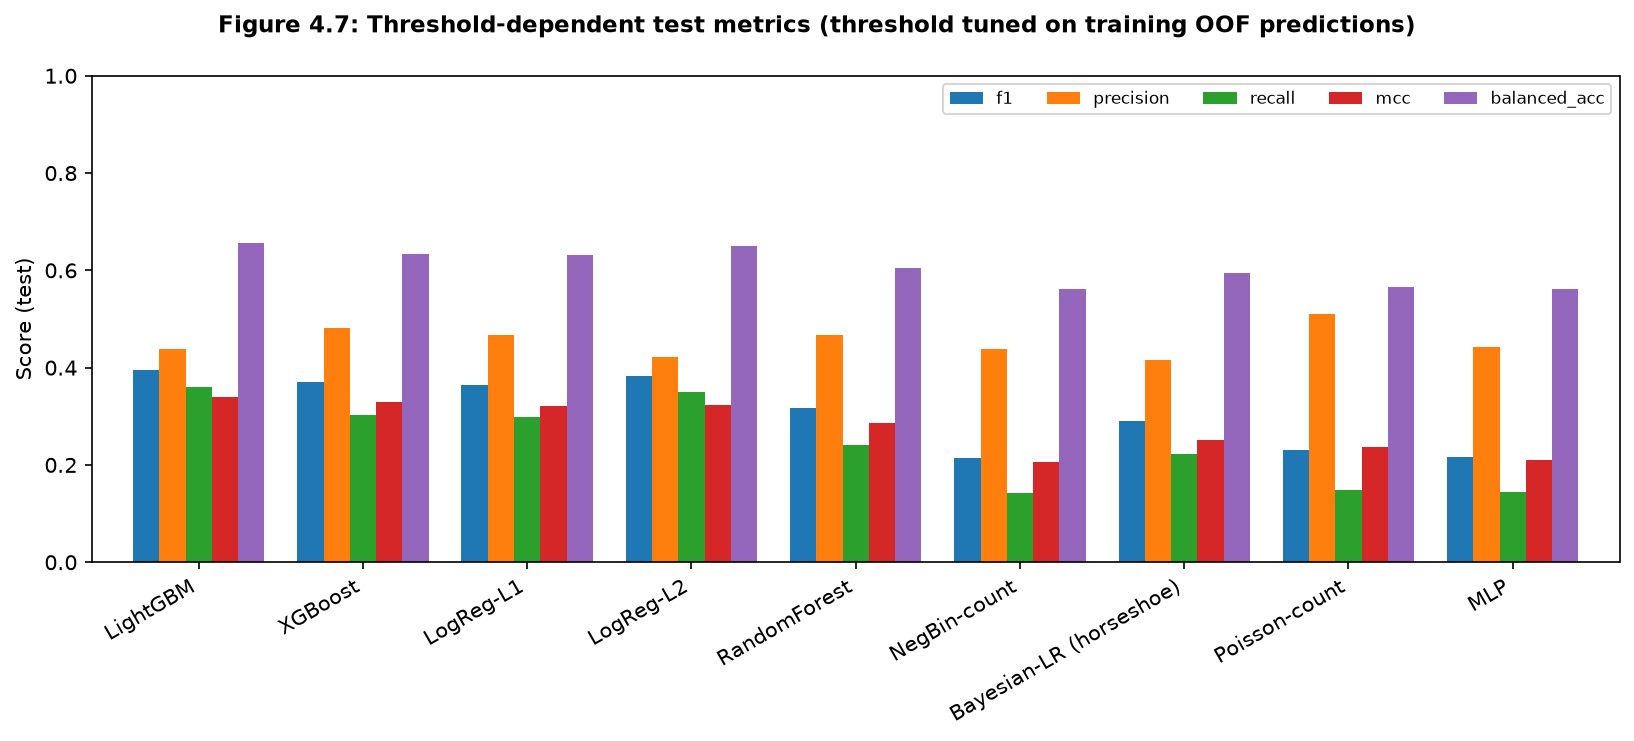

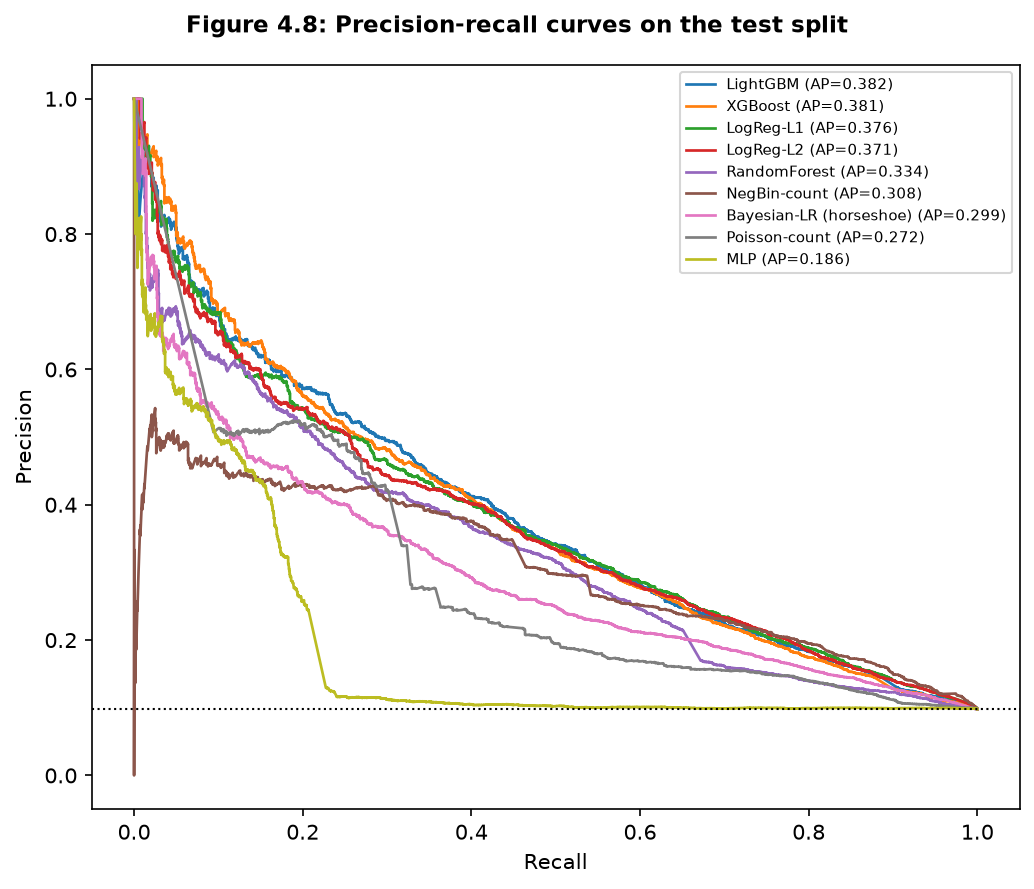

'figures/fig4_08_pr_curves.png'

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
order_m = RES.index.tolist()
cols = ["#2a6f97" if RES.loc[n, "family"] == "Statistical" else "#c05746" for n in order_m]
ax[0].barh(order_m[::-1], RES["pr_auc"][::-1], color=cols[::-1]); ax[0].set_xlabel("PR-AUC (test)")
ax[0].axvline(IMB.loc["test", "prevalence"], color="k", ls=":", lw=1, label="No-skill (prevalence)"); ax[0].legend(loc="lower right")
ax[1].barh(order_m[::-1], RES["roc_auc"][::-1], color=cols[::-1]); ax[1].set_xlabel("ROC-AUC (test)"); ax[1].axvline(0.5, color="k", ls=":", lw=1)
for a in ax: a.set_xlim(0, 1)
save_fig(fig, "model_comparison_auc", "Test-set PR-AUC and ROC-AUC by model (blue = statistical, red = ML)")

fig, ax = plt.subplots(figsize=(11, 5))
mm = ["f1", "precision", "recall", "mcc", "balanced_acc"]
RES[mm].plot.bar(ax=ax, width=0.8); ax.set_ylabel("Score (test)"); ax.set_ylim(0, 1); ax.legend(ncol=5, fontsize=8)
ax.set_xticklabels(RES.index, rotation=30, ha="right")
save_fig(fig, "model_comparison_threshold_metrics", "Threshold-dependent test metrics (threshold tuned on training OOF predictions)")

fig, ax = plt.subplots(figsize=(7, 6))
for n in RES.index:
    pr, rc, _ = precision_recall_curve(y_te, PROBS[n]); ax.plot(rc, pr, lw=1.3, label=f"{n} (AP={RES.loc[n,'pr_auc']:.3f})")
ax.axhline(IMB.loc["test", "prevalence"], color="k", ls=":", lw=1); ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.legend(fontsize=7)
save_fig(fig, "pr_curves", "Precision-recall curves on the test split")

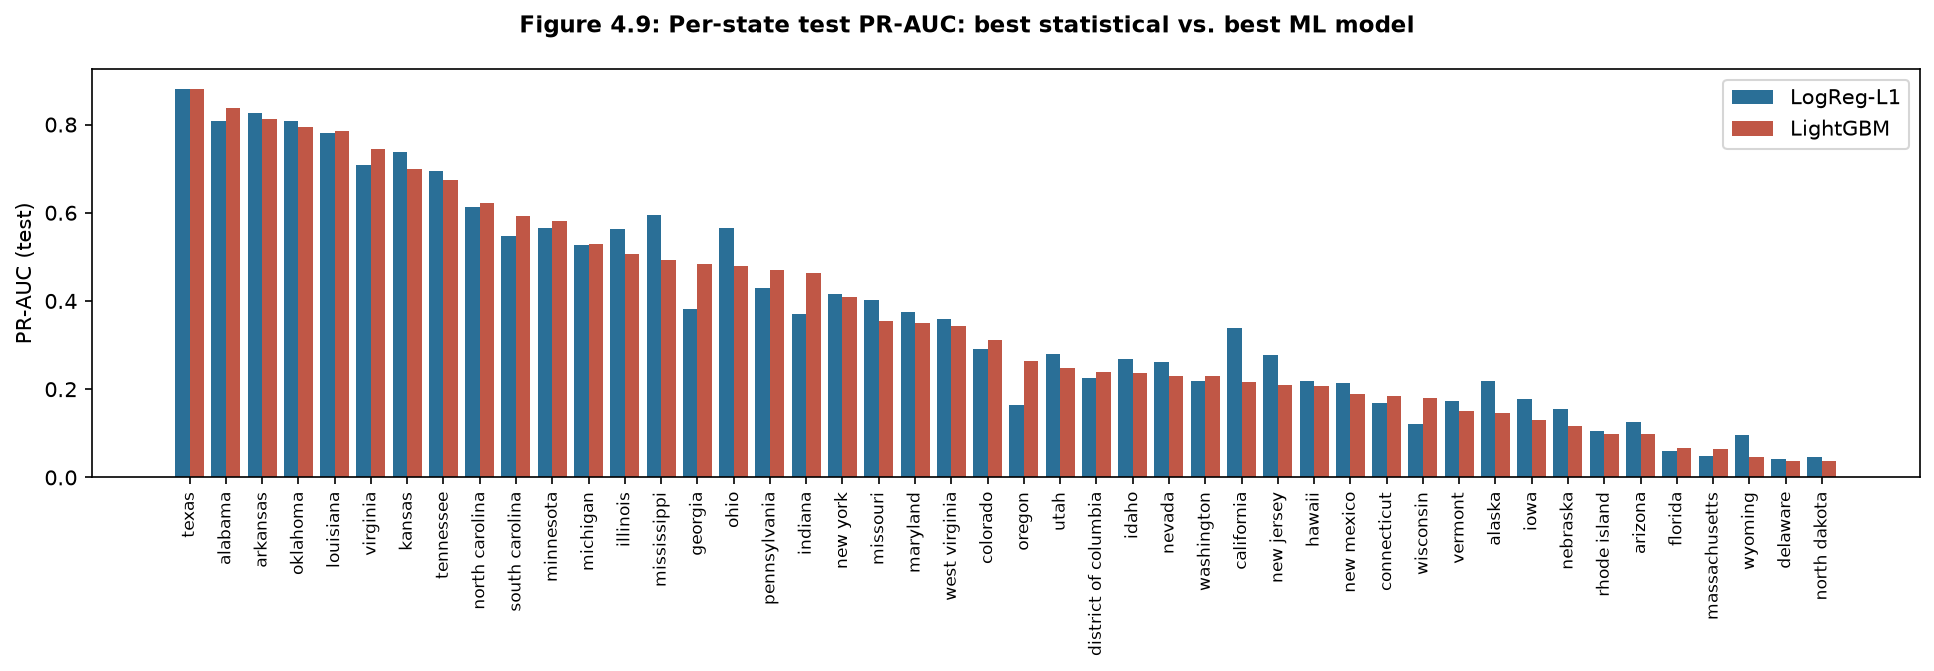

States excluded (no positives in test): ['maine', 'new hampshire']


,positives,LogReg-L1,LightGBM
count,46.0000,46.0000,46.0000
mean,49.6087,0.3750,0.3661
std,40.6172,0.2453,0.2493
min,7.0000,0.0420,0.0366
25%,21.0000,0.1741,0.1803
50%,40.0000,0.3151,0.2882
75%,61.2500,0.5649,0.5232
max,143.0000,0.8804,0.8810


In [20]:
# Per-state test PR-AUC for the best statistical and best ML model (states with at least one positive in test)
rows_ = []
for s in states:
    msk = state_te == s
    if y_te[msk].sum() == 0 or y_te[msk].sum() == msk.sum(): continue
    rows_.append(dict(state=s, positives=int(y_te[msk].sum()), **{n: average_precision_score(y_te[msk], PROBS[n][msk]) for n in (BEST_STAT, BEST_ML)}))
PER_STATE = pd.DataFrame(rows_).sort_values(BEST_ML, ascending=False); PER_STATE.to_csv(os.path.join(RES_DIR, "per_state_pr_auc.csv"), index=False)
fig, ax = plt.subplots(figsize=(13, 4.5)); xx = np.arange(len(PER_STATE))
ax.bar(xx - 0.2, PER_STATE[BEST_STAT], 0.4, label=BEST_STAT, color="#2a6f97"); ax.bar(xx + 0.2, PER_STATE[BEST_ML], 0.4, label=BEST_ML, color="#c05746")
ax.set_xticks(xx); ax.set_xticklabels(PER_STATE.state, rotation=90, fontsize=8); ax.set_ylabel("PR-AUC (test)"); ax.legend()
save_fig(fig, "per_state_pr_auc", "Per-state test PR-AUC: best statistical vs. best ML model")
print("States excluded (no positives in test):", [s for s in states if s not in set(PER_STATE.state)])
PER_STATE.describe().round(4)

## 8. Dimensionality reduction and imbalance handling (RQ3, proposal 3.3.3)
The tuned **LogReg-L2** and **LightGBM** hyperparameters are kept fixed, and one factor is changed at a time:
* **Dimensionality reduction** (imbalance handling fixed to class weights): all features; TruncatedSVD with enough
  components for ≥95% of explained variance (computed on training data and capped at 300; this replaces PCA for sparse input); χ² top-100; L1 (Lasso) selection.
* **Imbalance handling** (all features): none (threshold tuning only), class weights, SMOTE and random oversampling,
  all applied only inside the training data or training folds.

Each configuration reports 5-fold stratified CV PR-AUC on train and PR-AUC/F1 on test, with the threshold from OOF predictions.

In [21]:
Xl_full = Xl_tr  # log1p train for SVD variance computation
svd_probe = TruncatedSVD(n_components=300, random_state=SEED).fit(Xl_full)
cumv = np.cumsum(svd_probe.explained_variance_ratio_)
SVD_K = int(np.searchsorted(cumv, 0.95) + 1) if cumv[-1] >= 0.95 else 300
print(f"TruncatedSVD components for 95% variance (log1p input): {SVD_K} (cumulative at 300 = {cumv[-1]:.4f})")
lr_C = MODELS["LogReg-L2"].get_params()["clf__C"]
lgb_params = {k: v for k, v in MODELS["LightGBM"].get_params().items()}

def dr_step(kind):
    if kind == "All features": return []
    if kind == f"TruncatedSVD ({SVD_K} comp.)": return [("dr", TruncatedSVD(n_components=SVD_K, random_state=SEED))]
    if kind == "chi2 top-100": return [("dr", SelectKBest(chi2, k=100))]
    if kind == "L1 selection": return [("dr", SelectFromModel(LogisticRegression(penalty="l1", C=0.1, solver="liblinear", class_weight="balanced", random_state=SEED)))]

def make(model, dr="All features", imbal="class weights"):
    logs = [("log", FunctionTransformer(sparse_log1p, accept_sparse=True))]
    if model == "LogReg-L2":
        clf = LogisticRegression(C=lr_C, solver="liblinear", max_iter=5000, class_weight="balanced" if imbal == "class weights" else None, random_state=SEED)
        pre = logs + dr_step(dr) + [("scale", MaxAbsScaler())]
    else:
        p = dict(lgb_params); p["scale_pos_weight"] = spw if imbal == "class weights" else 1.0
        clf = lgb.LGBMClassifier(**p); pre = (logs + dr_step(dr)) if dr != "All features" else []
    samp = {"SMOTE": [("samp", SMOTE(random_state=SEED))], "random oversampling": [("samp", RandomOverSampler(random_state=SEED))]}.get(imbal, [])
    return ImbPipeline(pre + samp + [("clf", clf)])

def eval_cfg(model, dr, imbal):
    est = make(model, dr, imbal)
    t0 = time.time(); p_oof = cross_val_predict(est, X_tr, y_tr, cv=CV, method="predict_proba", n_jobs=1 if model == "LightGBM" else N_JOBS)[:, 1]
    thr = best_f1_threshold(y_tr, p_oof); est.fit(X_tr, y_tr); p = est.predict_proba(X_te)[:, 1]
    nfeat = est.named_steps["dr"].transform(X_tr[:5]).shape[1] if "dr" in est.named_steps else X_tr.shape[1]
    m = metrics(y_te, p, thr)
    return dict(model=model, dim_reduction=dr, imbalance=imbal, n_features=nfeat, cv_pr_auc=average_precision_score(y_tr, p_oof),
                test_pr_auc=m["pr_auc"], test_roc_auc=m["roc_auc"], test_f1=m["f1"], test_recall=m["recall"], test_precision=m["precision"],
                test_brier=m["brier"], seconds=time.time() - t0)

DR_ROWS = [eval_cfg(m, d, "class weights") for m in ("LogReg-L2", "LightGBM")
           for d in ("All features", f"TruncatedSVD ({SVD_K} comp.)", "chi2 top-100", "L1 selection")]
DRR = pd.DataFrame(DR_ROWS); DRR.to_csv(os.path.join(RES_DIR, "dimensionality_reduction.csv"), index=False); display(DRR.round(4))
IM_ROWS = [eval_cfg(m, "All features", i) for m in ("LogReg-L2", "LightGBM") for i in ("none (threshold only)", "class weights", "SMOTE", "random oversampling")]
IMR = pd.DataFrame(IM_ROWS); IMR.to_csv(os.path.join(RES_DIR, "imbalance_handling.csv"), index=False); display(IMR.round(4))

TruncatedSVD components for 95% variance (log1p input): 300 (cumulative at 300 = 0.9456)


,model,dim_reduction,imbalance,n_features,cv_pr_auc,test_pr_auc,test_roc_auc,test_f1,test_recall,test_precision,test_brier,seconds
0,LogReg-L2,All features,class weights,545,0.3650,0.3708,0.7929,0.3828,0.3506,0.4215,0.1544,0.7756
1,LogReg-L2,TruncatedSVD (300 comp.),class weights,300,0.3631,0.3746,0.7914,0.3614,0.2932,0.4711,0.1569,16.6357
2,LogReg-L2,chi2 top-100,class weights,100,0.3151,0.3451,0.7625,0.3498,0.2875,0.4466,0.1555,0.6227
3,LogReg-L2,L1 selection,class weights,404,0.3646,0.3696,0.7928,0.3474,0.2800,0.4574,0.1544,14.2199
4,LightGBM,All features,class weights,545,0.3843,0.3823,0.7887,0.3956,0.3611,0.4374,0.1350,4.8509
5,LightGBM,TruncatedSVD (300 comp.),class weights,300,0.3626,0.3582,0.7579,0.3671,0.3199,0.4307,0.1168,33.8484
6,LightGBM,chi2 top-100,class weights,100,0.3547,0.3541,0.7496,0.3348,0.2568,0.4807,0.1319,3.5418
7,LightGBM,L1 selection,class weights,404,0.3799,0.3801,0.7880,0.3939,0.3501,0.4501,0.1352,36.5411


,model,dim_reduction,imbalance,n_features,cv_pr_auc,test_pr_auc,test_roc_auc,test_f1,test_recall,test_precision,test_brier,seconds
0,LogReg-L2,All features,none (threshold only),545,0.3722,0.3753,0.7894,0.3583,0.2897,0.4695,0.0780,0.7180
1,LogReg-L2,All features,class weights,545,0.3650,0.3708,0.7929,0.3828,0.3506,0.4215,0.1544,0.7348
2,LogReg-L2,All features,SMOTE,545,0.3351,0.3409,0.7495,0.3349,0.2708,0.4386,0.1810,2.6504
3,LogReg-L2,All features,random oversampling,545,0.3600,0.3677,0.7916,0.3665,0.3168,0.4348,0.1543,1.9394
4,LightGBM,All features,none (threshold only),545,0.3877,0.3819,0.7900,0.3631,0.2936,0.4759,0.0770,4.9366
5,LightGBM,All features,class weights,545,0.3843,0.3823,0.7887,0.3956,0.3611,0.4374,0.1350,8.1370
6,LightGBM,All features,SMOTE,545,0.3219,0.2778,0.6760,0.3251,0.2472,0.4747,0.0820,36.1102
7,LightGBM,All features,random oversampling,545,0.3822,0.3781,0.7876,0.3843,0.3374,0.4464,0.1332,9.2088


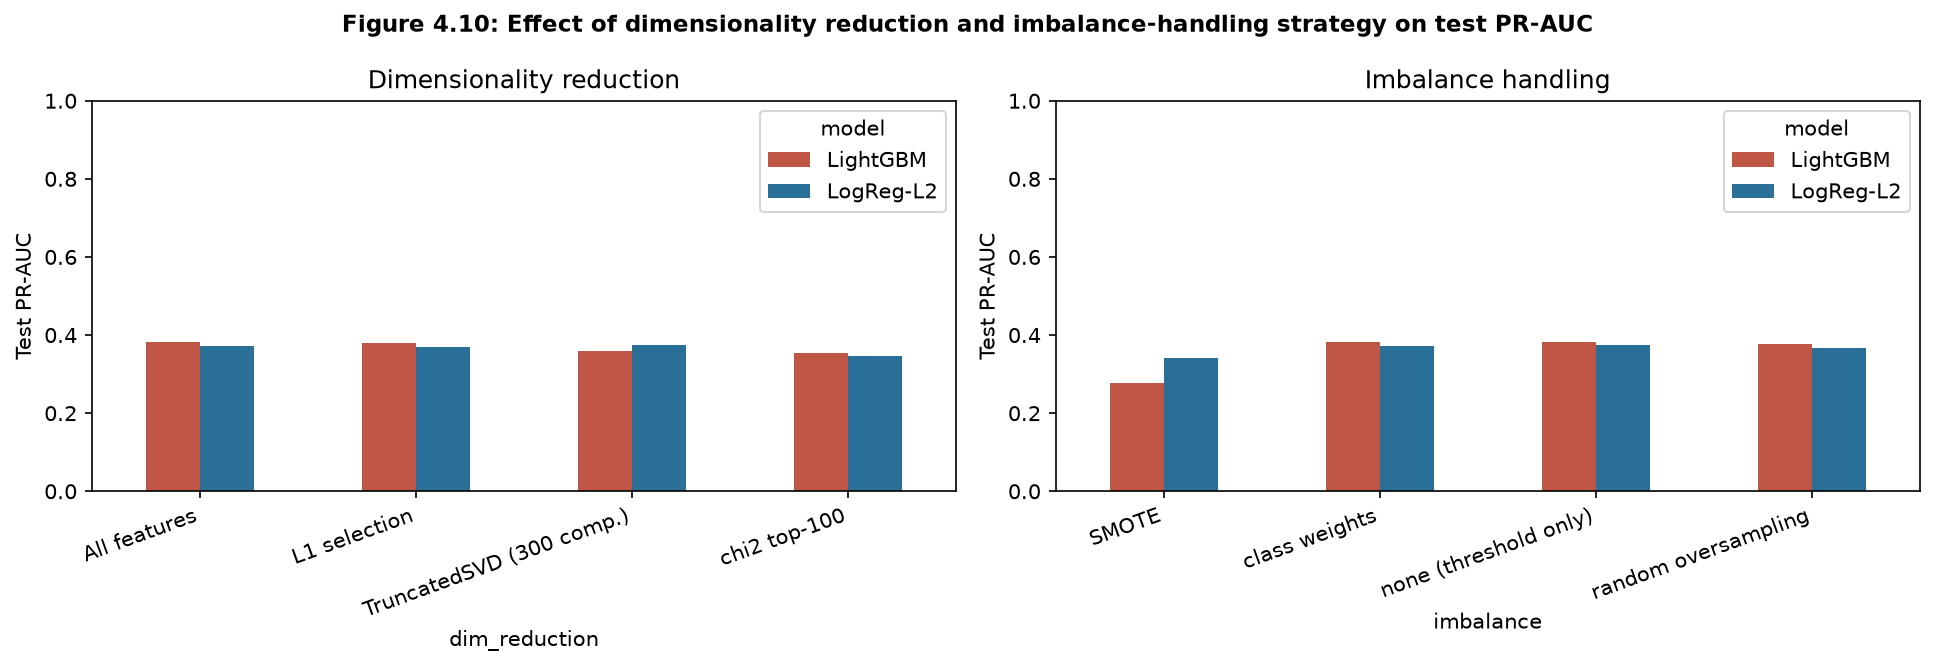

'figures/fig4_10_dr_imbalance.png'

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, df, col, ttl in ((ax[0], DRR, "dim_reduction", "Dimensionality reduction"), (ax[1], IMR, "imbalance", "Imbalance handling")):
    pv = df.pivot(index=col, columns="model", values="test_pr_auc"); pv.plot.bar(ax=a, color=["#c05746", "#2a6f97"])
    a.set_ylabel("Test PR-AUC"); a.set_title(ttl); a.set_xticklabels(pv.index, rotation=20, ha="right"); a.set_ylim(0, 1)
save_fig(fig, "dr_imbalance", "Effect of dimensionality reduction and imbalance-handling strategy on test PR-AUC")

## 9. Sparsity experiments (RQ1)
Three experiments, using LogReg-L2 and LightGBM with the tuned settings:
1. **Minimum document-frequency threshold**: keep only features whose training non-zero rate is ≥ t.
2. **Number of features kept** (top-k by χ², fitted on training data).
3. **Artificial sparsification**: randomly zero out a fraction r of the non-zero cells in both train and test (seeded),
   to simulate a sparser signal.

Since these runs are a sensitivity analysis, the reported numbers are test PR-AUC/ROC-AUC. Nothing is selected using them.

In [23]:
def fit_eval_simple(model, Xa, Xb):
    est = make(model, "All features", "class weights"); est.fit(Xa, y_tr); p = est.predict_proba(Xb)[:, 1]
    return average_precision_score(y_te, p), roc_auc_score(y_te, p)

SP_ROWS = []
for t in [0.0, 0.001, 0.01, 0.05, 0.10, 0.20, 0.30, 0.50]:
    keep = np.where(feat_nz >= t)[0]
    for m in ("LogReg-L2", "LightGBM"):
        a, r = fit_eval_simple(m, X_tr[:, keep], X_te[:, keep]); SP_ROWS.append(dict(experiment="min_df", value=t, n_features=len(keep), model=m, test_pr_auc=a, test_roc_auc=r))
Xl_te = X_te.copy(); Xl_te.data = np.log1p(Xl_te.data)
chi_scores = np.nan_to_num(chi2(Xl_tr, y_tr)[0]); chi_order = np.argsort(-chi_scores)
for k in [5, 10, 25, 50, 100, 200, 300, 545]:
    keep = np.sort(chi_order[:k])
    for m in ("LogReg-L2", "LightGBM"):
        a, r = fit_eval_simple(m, X_tr[:, keep], X_te[:, keep]); SP_ROWS.append(dict(experiment="top_k_chi2", value=k, n_features=k, model=m, test_pr_auc=a, test_roc_auc=r))
def sparsify(X, r, seed):
    X = X.copy().tocsr(); rr = np.random.default_rng(seed); X.data[rr.random(X.nnz) < r] = 0; X.eliminate_zeros(); return X
for r_ in [0.0, 0.25, 0.5, 0.75, 0.9, 0.95]:
    Xa, Xb = sparsify(X_tr, r_, SEED), sparsify(X_te, r_, SEED + 1)
    for m in ("LogReg-L2", "LightGBM"):
        a, r = fit_eval_simple(m, Xa, Xb); SP_ROWS.append(dict(experiment="sparsify", value=r_, n_features=545, density=density(Xa), model=m, test_pr_auc=a, test_roc_auc=r))
SPR = pd.DataFrame(SP_ROWS); SPR.to_csv(os.path.join(RES_DIR, "sparsity_experiments.csv"), index=False); display(SPR.round(4))

,experiment,value,n_features,model,test_pr_auc,test_roc_auc,density
0,min_df,0.000,545,LogReg-L2,0.3708,0.7929,NaN
1,min_df,0.000,545,LightGBM,0.3823,0.7887,NaN
2,min_df,0.001,545,LogReg-L2,0.3708,0.7929,NaN
3,min_df,0.001,545,LightGBM,0.3823,0.7887,NaN
4,min_df,0.010,502,LogReg-L2,0.3720,0.7931,NaN
5,min_df,0.010,502,LightGBM,0.3771,0.7874,NaN
6,min_df,0.050,175,LogReg-L2,0.3670,0.7876,NaN
7,min_df,0.050,175,LightGBM,0.3685,0.7749,NaN
8,min_df,0.100,64,LogReg-L2,0.3389,0.7723,NaN
9,min_df,0.100,64,LightGBM,0.3394,0.7540,NaN


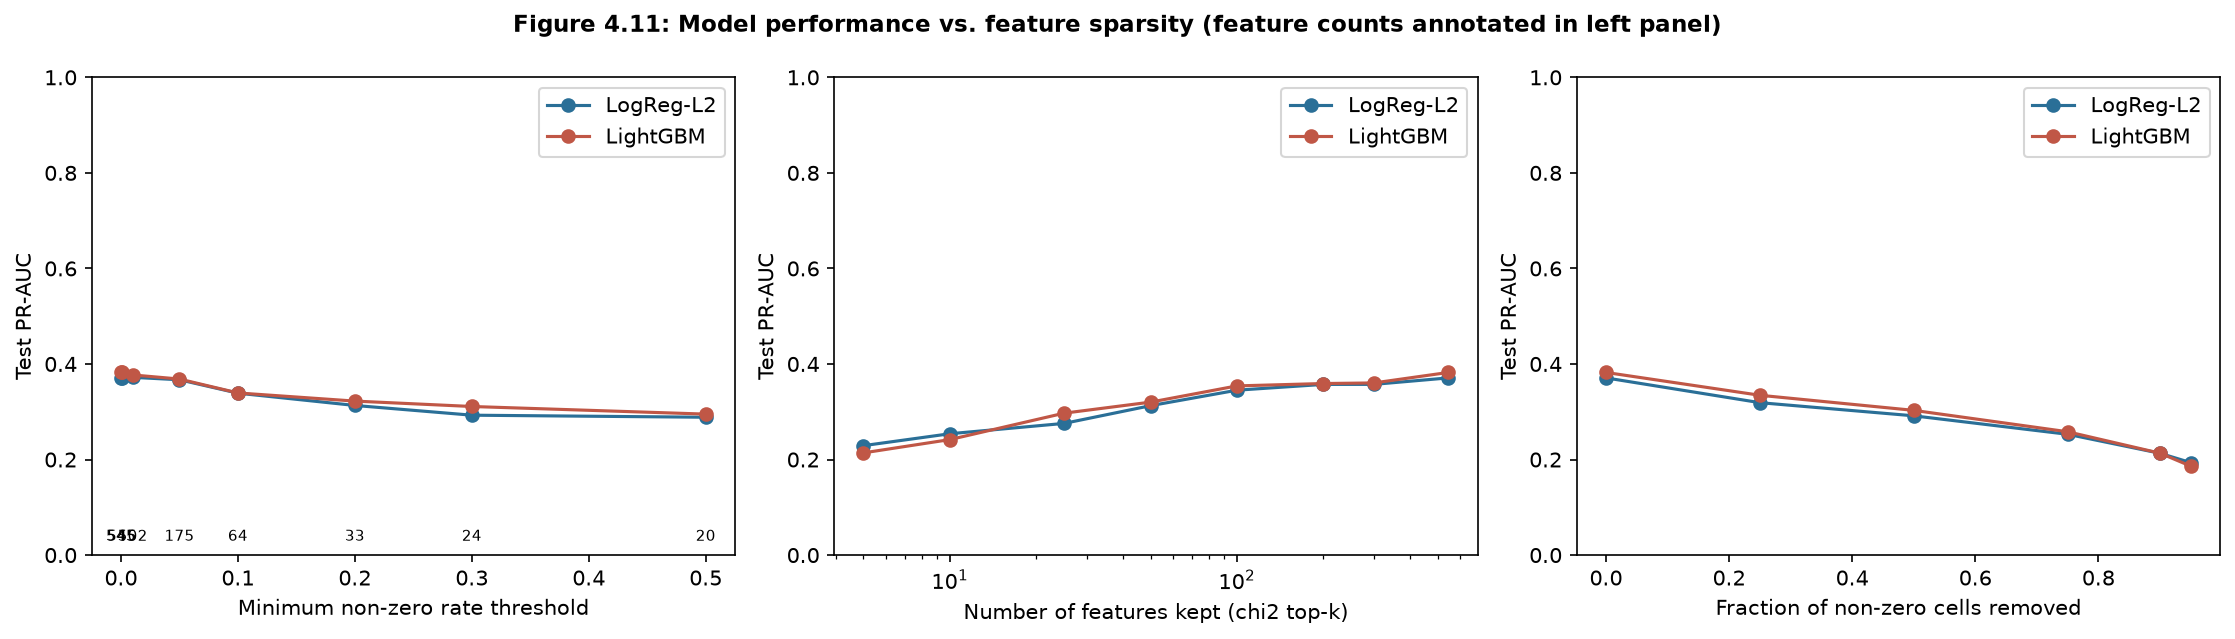

'figures/fig4_11_sparsity_experiments.png'

In [24]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
for a, ex, xl, logx in ((ax[0], "min_df", "Minimum non-zero rate threshold", False), (ax[1], "top_k_chi2", "Number of features kept (chi2 top-k)", True),
                        (ax[2], "sparsify", "Fraction of non-zero cells removed", False)):
    for m, c in (("LogReg-L2", "#2a6f97"), ("LightGBM", "#c05746")):
        d = SPR[(SPR.experiment == ex) & (SPR.model == m)]; a.plot(d.value, d.test_pr_auc, "o-", color=c, label=m)
    a.set_xlabel(xl); a.set_ylabel("Test PR-AUC"); a.legend(); a.set_ylim(0, 1)
    if logx: a.set_xscale("log")
mdf = SPR[(SPR.experiment == "min_df") & (SPR.model == "LogReg-L2")]
for v, n in zip(mdf.value, mdf.n_features): ax[0].annotate(str(n), (v, 0.03), fontsize=7, ha="center")
save_fig(fig, "sparsity_experiments", "Model performance vs. feature sparsity (feature counts annotated in left panel)")

### 9.1 Keywords-only sensitivity run (drops the 20 undocumented aux columns)

In [25]:
KW_ROWS = []
for m in ("LogReg-L2", "LightGBM"):
    a, r = fit_eval_simple(m, X_tr[:, N_AUX:], X_te[:, N_AUX:]); KW_ROWS.append(dict(model=m, features="525 keywords only", test_pr_auc=a, test_roc_auc=r))
    a, r = fit_eval_simple(m, X_tr, X_te); KW_ROWS.append(dict(model=m, features="all 545", test_pr_auc=a, test_roc_auc=r))
KWR = pd.DataFrame(KW_ROWS); KWR.to_csv(os.path.join(RES_DIR, "keywords_only.csv"), index=False); display(KWR.round(4))

,model,features,test_pr_auc,test_roc_auc
0,LogReg-L2,525 keywords only,0.3393,0.7799
1,LogReg-L2,all 545,0.3708,0.7929
2,LightGBM,525 keywords only,0.3396,0.7725
3,LightGBM,all 545,0.3823,0.7887


## 10. Temporal validation (proposal 3.5)
Forward-chaining CV on the training period: the 1,095 training time steps are split into 5 contiguous blocks. For k = 1..4 the
models train on blocks 1..k and validate on block k+1 (all states). The tuned hyperparameters are kept fixed. This is compared with the shuffled stratified CV score.

In [26]:
blocks = np.array_split(np.arange(DATASET["steps_train"]), 5)
TEMP_ROWS = []
def clone_model(name):
    from sklearn.base import clone
    return clone(MODELS[name])
for name in [n for n in RES.index if n not in ("Poisson-count", "NegBin-count", "Bayesian-LR (horseshoe)")]:
    for k in range(1, 5):
        tr_m = np.isin(t_tr, np.concatenate(blocks[:k])); va_m = np.isin(t_tr, blocks[k])
        if y_tr[tr_m].sum() == 0 or y_tr[va_m].sum() == 0:
            TEMP_ROWS.append(dict(model=name, fold=k, pr_auc=np.nan, roc_auc=np.nan, val_prevalence=y_tr[va_m].mean())); continue
        est = clone_model(name).fit(X_tr[tr_m], y_tr[tr_m]); p = est.predict_proba(X_tr[va_m])[:, 1]
        TEMP_ROWS.append(dict(model=name, fold=k, pr_auc=average_precision_score(y_tr[va_m], p), roc_auc=roc_auc_score(y_tr[va_m], p), val_prevalence=y_tr[va_m].mean()))
for name in ("Poisson-count", "NegBin-count"):
    fam = "poisson" if name.startswith("Poisson") else "negbin"
    for k in range(1, 5):
        tr_m = np.isin(t_tr, np.concatenate(blocks[:k])); va_m = np.isin(t_tr, blocks[k])
        if y_tr[tr_m].sum() == 0 or y_tr[va_m].sum() == 0:
            TEMP_ROWS.append(dict(model=name, fold=k, pr_auc=np.nan, roc_auc=np.nan, val_prevalence=y_tr[va_m].mean())); continue
        mdl = CountGLMClassifier(fam, N_AUX).fit(X_tr[tr_m], y_tr[tr_m], sidx_tr[tr_m], len(states)); p = mdl.predict_proba(X_tr[va_m], sidx_tr[va_m])[:, 1]
        TEMP_ROWS.append(dict(model=name, fold=k, pr_auc=average_precision_score(y_tr[va_m], p), roc_auc=roc_auc_score(y_tr[va_m], p), val_prevalence=y_tr[va_m].mean()))
TEMP = pd.DataFrame(TEMP_ROWS); TEMP.to_csv(os.path.join(RES_DIR, "temporal_cv_folds.csv"), index=False)
TEMP_SUM = TEMP.groupby("model").agg(temporal_cv_pr_auc_mean=("pr_auc", "mean"), temporal_cv_pr_auc_std=("pr_auc", "std"),
                                     temporal_cv_roc_auc_mean=("roc_auc", "mean"), folds_used=("pr_auc", "count"))
TEMP_SUM["stratified_cv_pr_auc_oof"] = [CVBEST.get(n, {}).get("oof_pr_auc", np.nan) for n in TEMP_SUM.index]
TEMP_SUM["test_pr_auc"] = [RES.loc[n, "pr_auc"] for n in TEMP_SUM.index]
TEMP_SUM = TEMP_SUM.sort_values("test_pr_auc", ascending=False); TEMP_SUM.to_csv(os.path.join(RES_DIR, "temporal_cv_summary.csv"))
display(TEMP.round(4)); display(TEMP_SUM.round(4))

,model,fold,pr_auc,roc_auc,val_prevalence
0,LightGBM,1,0.0399,0.6564,0.0128
1,LightGBM,2,0.0965,0.7285,0.0011
2,LightGBM,3,0.2487,0.6077,0.1492
3,LightGBM,4,0.2659,0.7944,0.0393
4,XGBoost,1,0.0499,0.6728,0.0128
5,XGBoost,2,0.1109,0.7169,0.0011
6,XGBoost,3,0.2312,0.5640,0.1492
7,XGBoost,4,0.2537,0.7872,0.0393
8,LogReg-L1,1,0.0627,0.7209,0.0128
9,LogReg-L1,2,0.0650,0.7964,0.0011


,temporal_cv_pr_auc_mean,temporal_cv_pr_auc_std,temporal_cv_roc_auc_mean,folds_used,stratified_cv_pr_auc_oof,test_pr_auc
model,,,,,,
LightGBM,0.1628,0.1119,0.6968,4,0.3843,0.3823
XGBoost,0.1614,0.0972,0.6853,4,0.3711,0.3809
LogReg-L1,0.2004,0.1663,0.7655,4,0.3700,0.3761
LogReg-L2,0.1900,0.1611,0.7424,4,0.3650,0.3708
RandomForest,0.1223,0.0999,0.7011,4,0.3326,0.3340
NegBin-count,0.2330,0.2265,0.8794,4,0.3995,0.3076
Poisson-count,0.1906,0.1800,0.8709,4,0.3492,0.2716
MLP,0.0946,0.0863,0.5038,4,0.2036,0.1855


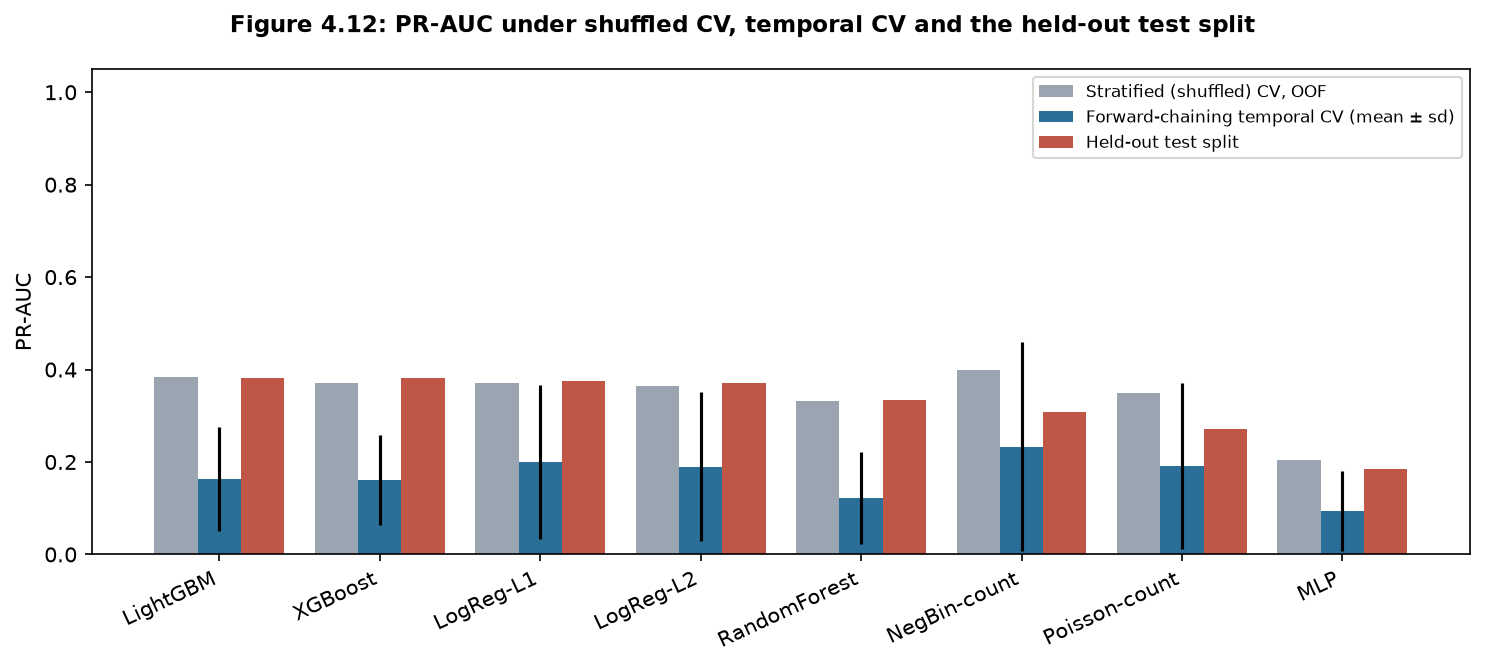

'figures/fig4_12_cv_vs_temporal_vs_test.png'

In [27]:
fig, ax = plt.subplots(figsize=(10, 4.5)); xx = np.arange(len(TEMP_SUM))
ax.bar(xx - 0.27, TEMP_SUM.stratified_cv_pr_auc_oof, 0.27, label="Stratified (shuffled) CV, OOF", color="#9aa5b1")
ax.bar(xx, TEMP_SUM.temporal_cv_pr_auc_mean, 0.27, yerr=TEMP_SUM.temporal_cv_pr_auc_std, label="Forward-chaining temporal CV (mean ± sd)", color="#2a6f97")
ax.bar(xx + 0.27, TEMP_SUM.test_pr_auc, 0.27, label="Held-out test split", color="#c05746")
ax.set_xticks(xx); ax.set_xticklabels(TEMP_SUM.index, rotation=25, ha="right"); ax.set_ylabel("PR-AUC"); ax.legend(fontsize=8); ax.set_ylim(0, 1.05)
save_fig(fig, "cv_vs_temporal_vs_test", "PR-AUC under shuffled CV, temporal CV and the held-out test split")

## 11. Calibration (RQ4)
Reliability diagrams (10 quantile bins) for every model on the test split. Post-hoc **Platt (sigmoid)** and **isotonic**
calibration (`CalibratedClassifierCV`, 5-fold on training data) is then applied to the sklearn-compatible models, with Brier
scores reported before and after.

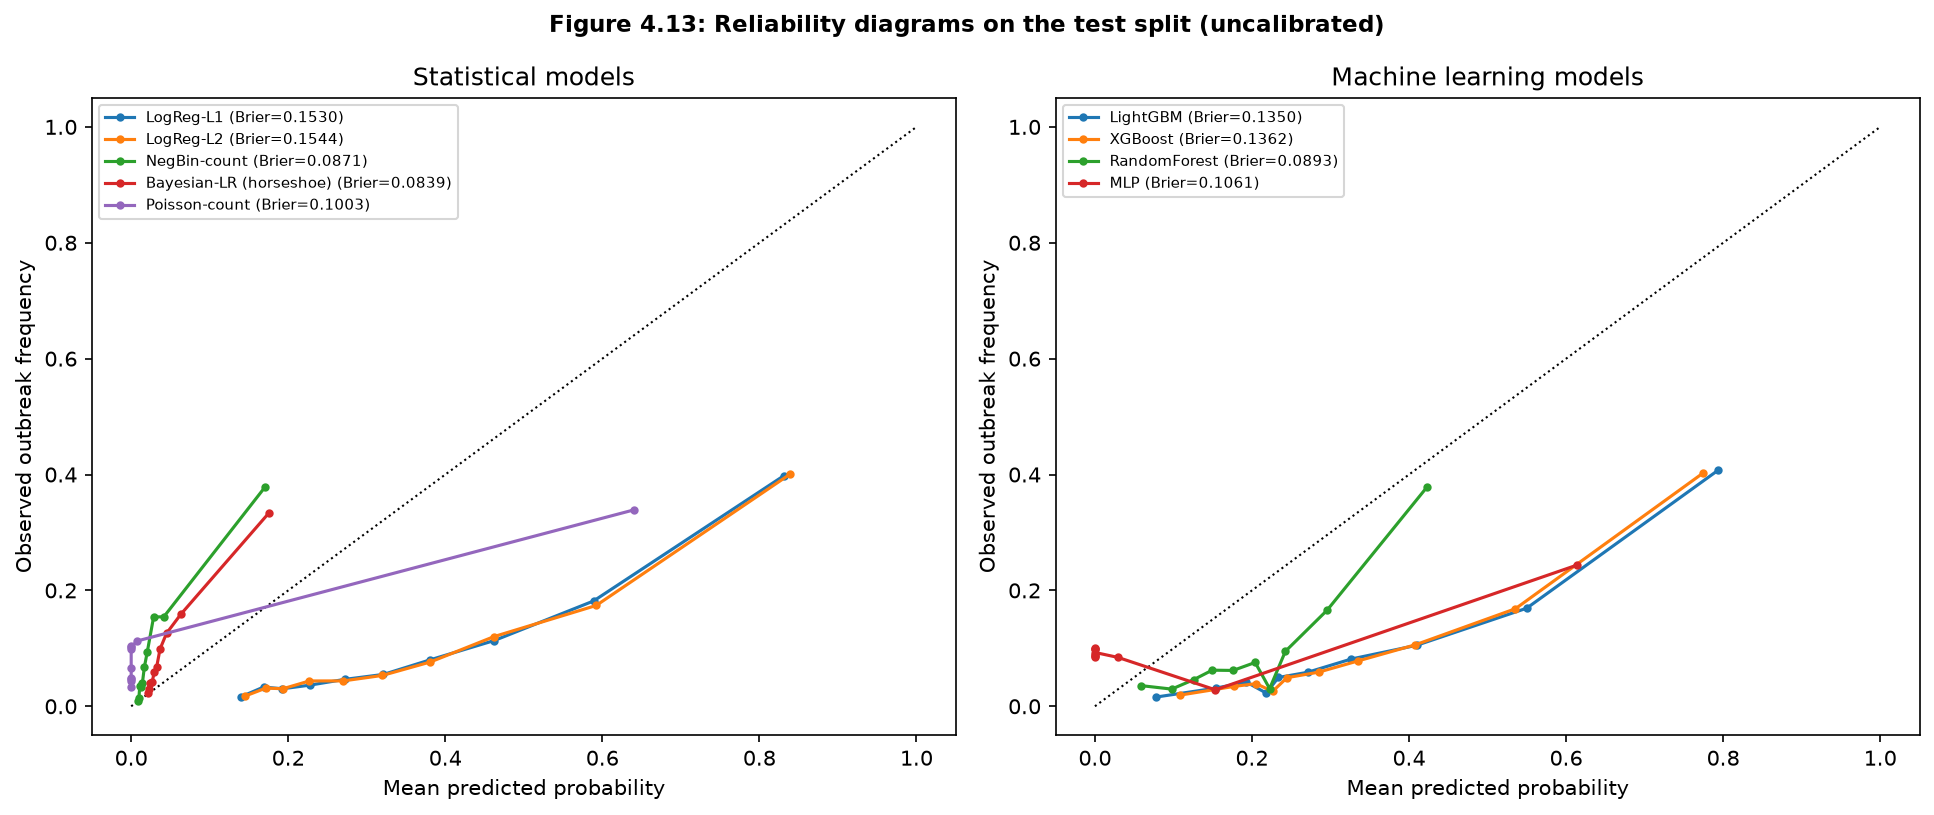

method,Platt,isotonic,uncalibrated
model,,,
LightGBM,0.07592,0.07585,0.13499
LogReg-L1,0.07757,0.07649,0.15299
LogReg-L2,0.07782,0.07674,0.15438
MLP,0.08497,0.08413,0.10613
RandomForest,0.08023,0.07953,0.08934
XGBoost,0.07592,0.07586,0.13619


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax_, names in ((axes[0], STAT_NAMES), (axes[1], ML_NAMES)):
    ax_.plot([0, 1], [0, 1], "k:", lw=1)
    for n in names:
        fp, mp = calibration_curve(y_te, PROBS[n], n_bins=10, strategy="quantile"); ax_.plot(mp, fp, "o-", ms=3, label=f"{n} (Brier={RES.loc[n,'brier']:.4f})")
    ax_.set_xlabel("Mean predicted probability"); ax_.set_ylabel("Observed outbreak frequency"); ax_.legend(fontsize=7)
axes[0].set_title("Statistical models"); axes[1].set_title("Machine learning models")
save_fig(fig, "calibration_curves", "Reliability diagrams on the test split (uncalibrated)")

CAL_ROWS, CAL_PROBS = [], {}
for n in ["LogReg-L1", "LogReg-L2", "RandomForest", "XGBoost", "LightGBM", "MLP"]:
    CAL_ROWS.append(dict(model=n, method="uncalibrated", brier=brier_score_loss(y_te, PROBS[n]), pr_auc=average_precision_score(y_te, PROBS[n])))
    for meth in ("sigmoid", "isotonic"):
        t0 = time.time(); cc = CalibratedClassifierCV(clone_model(n), method=meth, cv=CV).fit(X_tr, y_tr); p = cc.predict_proba(X_te)[:, 1]
        CAL_PROBS[(n, meth)] = p
        CAL_ROWS.append(dict(model=n, method="Platt" if meth == "sigmoid" else "isotonic", brier=brier_score_loss(y_te, p), pr_auc=average_precision_score(y_te, p), seconds=time.time() - t0))
CAL = pd.DataFrame(CAL_ROWS); CAL.to_csv(os.path.join(RES_DIR, "calibration_posthoc.csv"), index=False)
display(CAL.pivot(index="model", columns="method", values="brier").round(5))

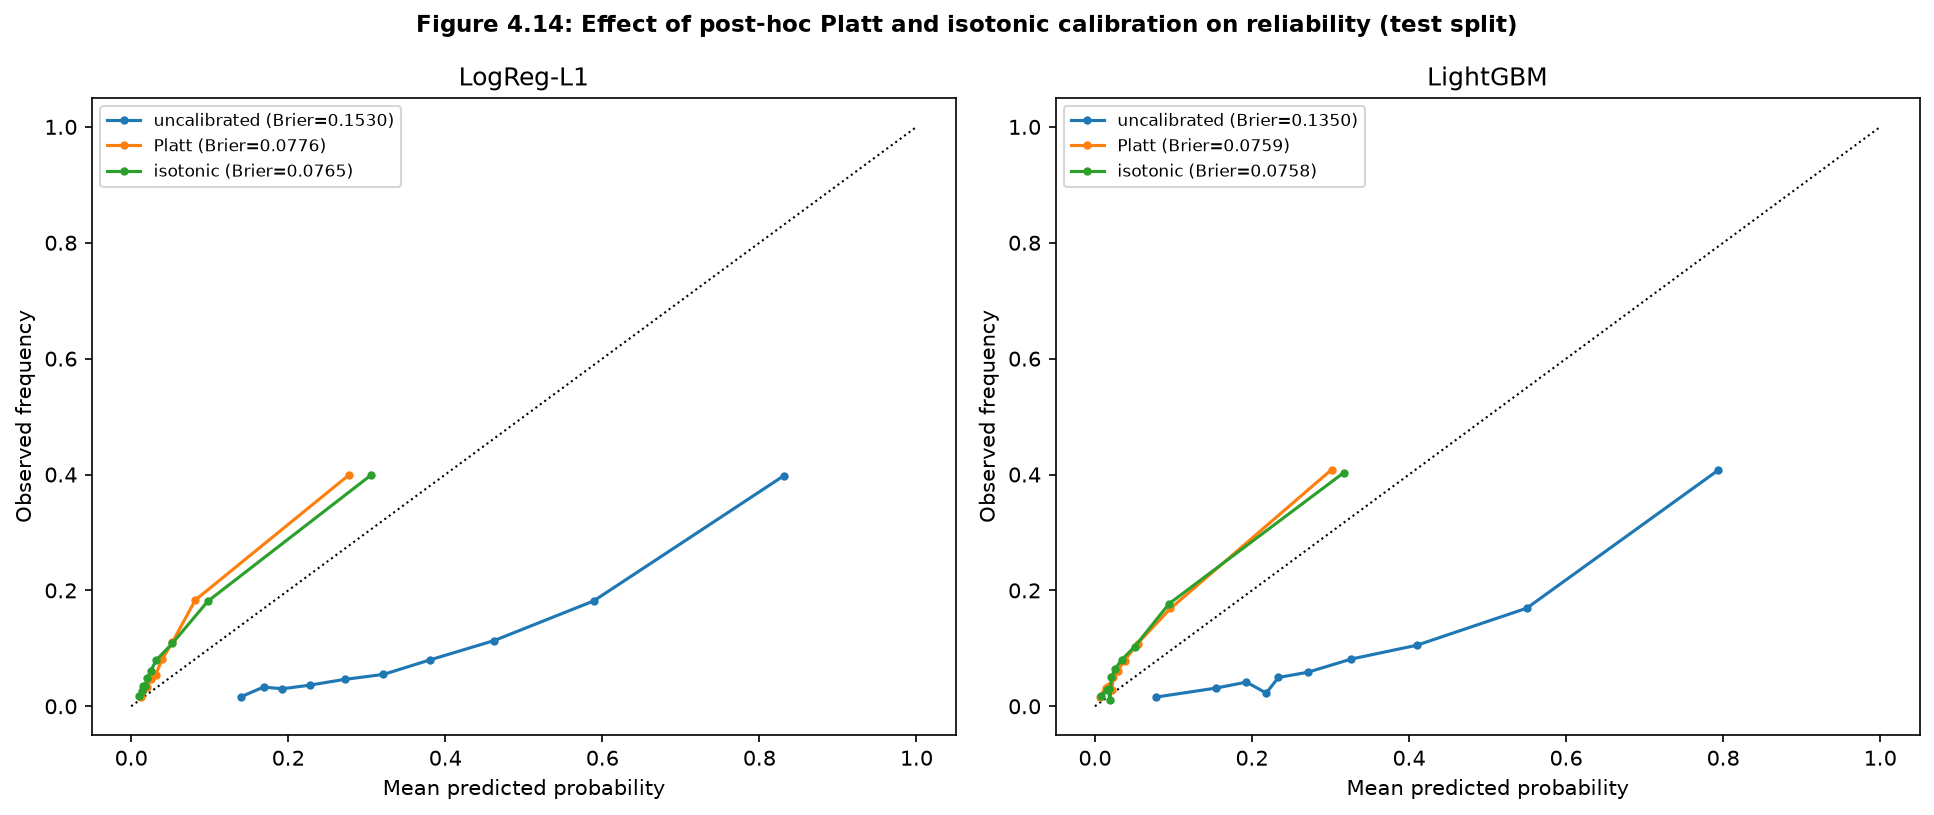

'figures/fig4_14_calibration_posthoc.png'

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax_, n in zip(axes, (BEST_STAT if BEST_STAT in ("LogReg-L1", "LogReg-L2") else "LogReg-L2", BEST_ML)):
    ax_.plot([0, 1], [0, 1], "k:", lw=1)
    for lab, p in (("uncalibrated", PROBS[n]), ("Platt", CAL_PROBS[(n, "sigmoid")]), ("isotonic", CAL_PROBS[(n, "isotonic")])):
        fp, mp = calibration_curve(y_te, p, n_bins=10, strategy="quantile"); ax_.plot(mp, fp, "o-", ms=3, label=f"{lab} (Brier={brier_score_loss(y_te, p):.4f})")
    ax_.set_title(n); ax_.set_xlabel("Mean predicted probability"); ax_.set_ylabel("Observed frequency"); ax_.legend(fontsize=8)
save_fig(fig, "calibration_posthoc", "Effect of post-hoc Platt and isotonic calibration on reliability (test split)")

## 12. Interpretability (RQ4, proposal 3.6)
* Logistic regression coefficients (on the preprocessed scale) mapped back to keyword names.
* Posterior means and 94% credible intervals of the horseshoe Bayesian LR.
* Random Forest mean decrease in impurity (MDI).
* XGBoost and LightGBM **SHAP** values (exact TreeSHAP, native implementations) on a seeded random sample of 3,000 test rows.
* Agreement between paradigms: overlap of the top-20 features (Jaccard index), plus the Spearman correlation of importance ranks across all 545 features.

In [30]:
import shap
IMP = {}
for n in ("LogReg-L1", "LogReg-L2"):
    IMP[n] = pd.Series(MODELS[n].named_steps["clf"].coef_.ravel(), index=feature_names)
b_mean = pd.Series(0.0, index=feature_names); b_mean.iloc[bidx] = bayes.coef_mean; IMP["Bayesian-LR (horseshoe)"] = b_mean
IMP["RandomForest"] = pd.Series(MODELS["RandomForest"].feature_importances_, index=feature_names)
rs = np.random.default_rng(SEED).choice(X_te.shape[0], min(3000, X_te.shape[0]), replace=False)
SHAP_VALS = {}
Xs_dense = X_te[rs].toarray()
# Exact TreeSHAP contributions from each library's native implementation (avoids shap/xgboost version clashes);
# the shap package is only used for the summary plot.
SHAP_VALS["XGBoost"] = MODELS["XGBoost"].get_booster().predict(xgb.DMatrix(Xs_dense), pred_contribs=True)[:, :-1]
SHAP_VALS["LightGBM"] = MODELS["LightGBM"].predict(Xs_dense, pred_contrib=True)[:, :-1]
for n in ("XGBoost", "LightGBM"):
    IMP[n] = pd.Series(np.abs(SHAP_VALS[n]).mean(0), index=feature_names)
nz_l1 = int((IMP["LogReg-L1"] != 0).sum()); print("LogReg-L1 non-zero coefficients:", nz_l1, "of", len(feature_names))

def top_abs(s, k=20): return s.abs().sort_values(ascending=False).head(k)
TOP20 = pd.DataFrame({n: top_abs(IMP[n]).index.tolist() for n in IMP})
TOP20.index = range(1, 21); TOP20.to_csv(os.path.join(RES_DIR, "top20_features_by_model.csv")); display(TOP20)
coef_tbl = pd.DataFrame({"feature": feature_names, "LogReg-L1_coef": IMP["LogReg-L1"].values, "LogReg-L2_coef": IMP["LogReg-L2"].values,
                         "Bayes_post_mean": IMP["Bayesian-LR (horseshoe)"].values, "RF_MDI": IMP["RandomForest"].values,
                         "XGB_mean_abs_SHAP": IMP["XGBoost"].values, "LGBM_mean_abs_SHAP": IMP["LightGBM"].values})
coef_tbl.to_csv(os.path.join(RES_DIR, "feature_importance_all.csv"), index=False)
L2_POS = IMP["LogReg-L2"].sort_values(ascending=False).head(15); L2_NEG = IMP["LogReg-L2"].sort_values().head(15)

LogReg-L1 non-zero coefficients: 300 of 545


,LogReg-L1,LogReg-L2,Bayesian-LR (horseshoe),RandomForest,XGBoost,LightGBM
1,aux_19,summer,house,flu,flu,aux_19
2,summer,swine,family,sick,jab,flu
3,swine,aux_19,tested,aux_19,vai,swine
4,tested,stomach,strep,aux_17,aku,stomach
5,jab,jab,aux_19,aux_18,lagi,summer
6,stomach,allergies,season,aux_15,condom,bird
7,allergies,tested,test,aux_14,summer,aux_02
8,flu,flu,flu,house,banget,house
9,aux_02,family,aux_18,aux_12,slime,aux_16
10,2013,bird,aux_07,aux_13,strep,around


In [31]:
from scipy.stats import spearmanr
names_imp = list(IMP)
J = pd.DataFrame(index=names_imp, columns=names_imp, dtype=float); R = J.copy()
for a in names_imp:
    for b in names_imp:
        A, B = set(TOP20[a]), set(TOP20[b]); J.loc[a, b] = len(A & B) / len(A | B)
        R.loc[a, b] = spearmanr(IMP[a].abs().values, IMP[b].abs().values).correlation
J.to_csv(os.path.join(RES_DIR, "top20_jaccard.csv")); R.to_csv(os.path.join(RES_DIR, "importance_spearman.csv"))
display(J.round(3)); display(R.round(3))
consensus = pd.concat([IMP[n].abs().rank(ascending=False) for n in names_imp], axis=1).mean(1).sort_values().head(20)
CONSENSUS = consensus.rename("mean_rank").to_frame(); CONSENSUS.to_csv(os.path.join(RES_DIR, "consensus_top20.csv")); display(CONSENSUS.round(2))

,LogReg-L1,LogReg-L2,Bayesian-LR (horseshoe),RandomForest,XGBoost,LightGBM
LogReg-L1,1.000,0.739,0.212,0.143,0.143,0.379
LogReg-L2,0.739,1.000,0.290,0.212,0.111,0.379
Bayesian-LR (horseshoe),0.212,0.290,1.000,0.290,0.143,0.212
RandomForest,0.143,0.212,0.290,1.000,0.081,0.290
XGBoost,0.143,0.111,0.143,0.081,1.000,0.111
LightGBM,0.379,0.379,0.212,0.290,0.111,1.000


,LogReg-L1,LogReg-L2,Bayesian-LR (horseshoe),RandomForest,XGBoost,LightGBM
LogReg-L1,1.000,0.856,0.195,0.298,0.533,0.727
LogReg-L2,0.856,1.000,0.220,0.158,0.499,0.718
Bayesian-LR (horseshoe),0.195,0.220,1.000,0.462,0.266,0.372
RandomForest,0.298,0.158,0.462,1.000,0.311,0.543
XGBoost,0.533,0.499,0.266,0.311,1.000,0.576
LightGBM,0.727,0.718,0.372,0.543,0.576,1.000


,mean_rank
flu,4.67
aux_19,5.00
house,13.50
family,16.33
around,16.83
strep,23.17
sick,23.17
tested,28.17
doctor,31.67
stay,36.00


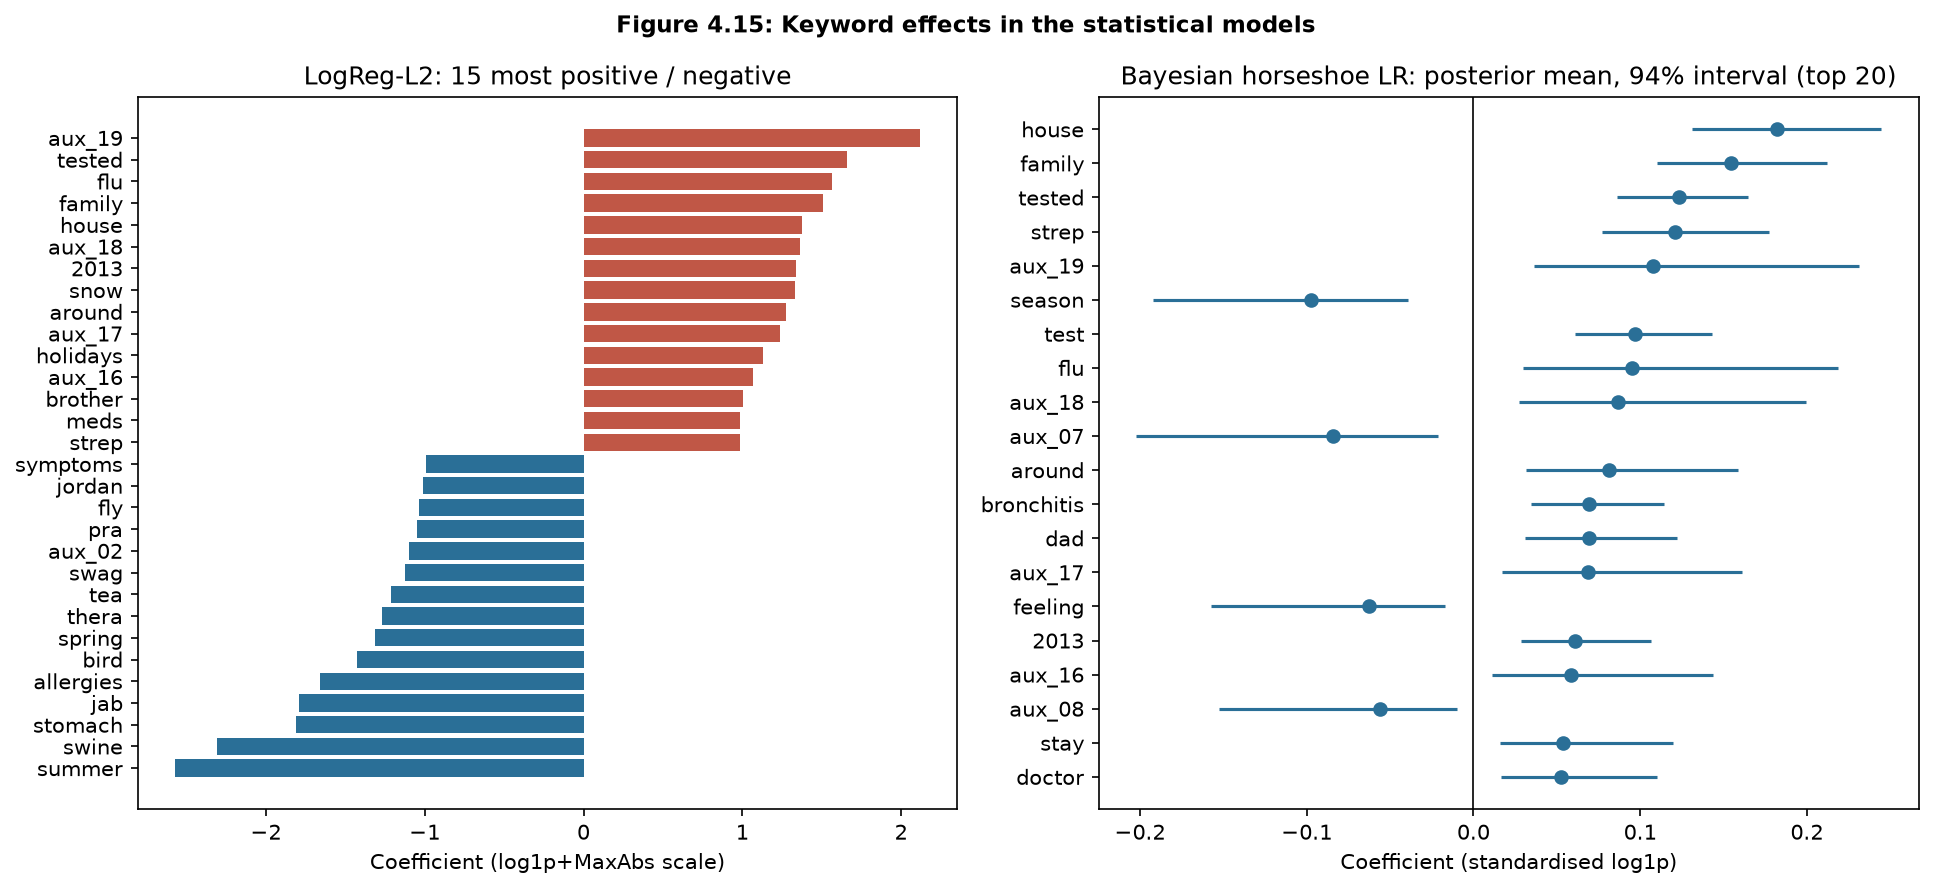

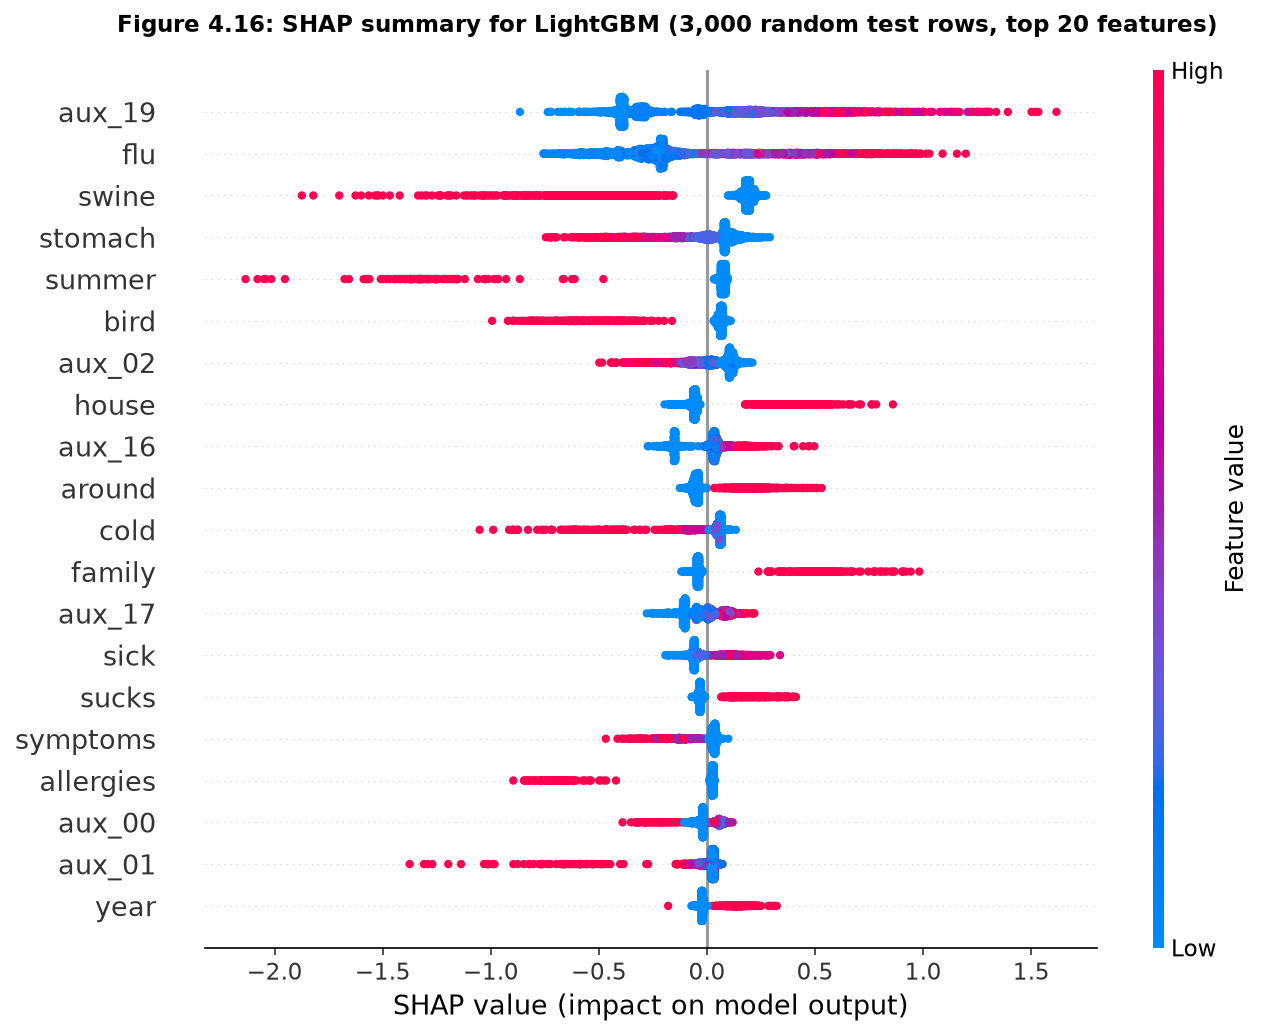

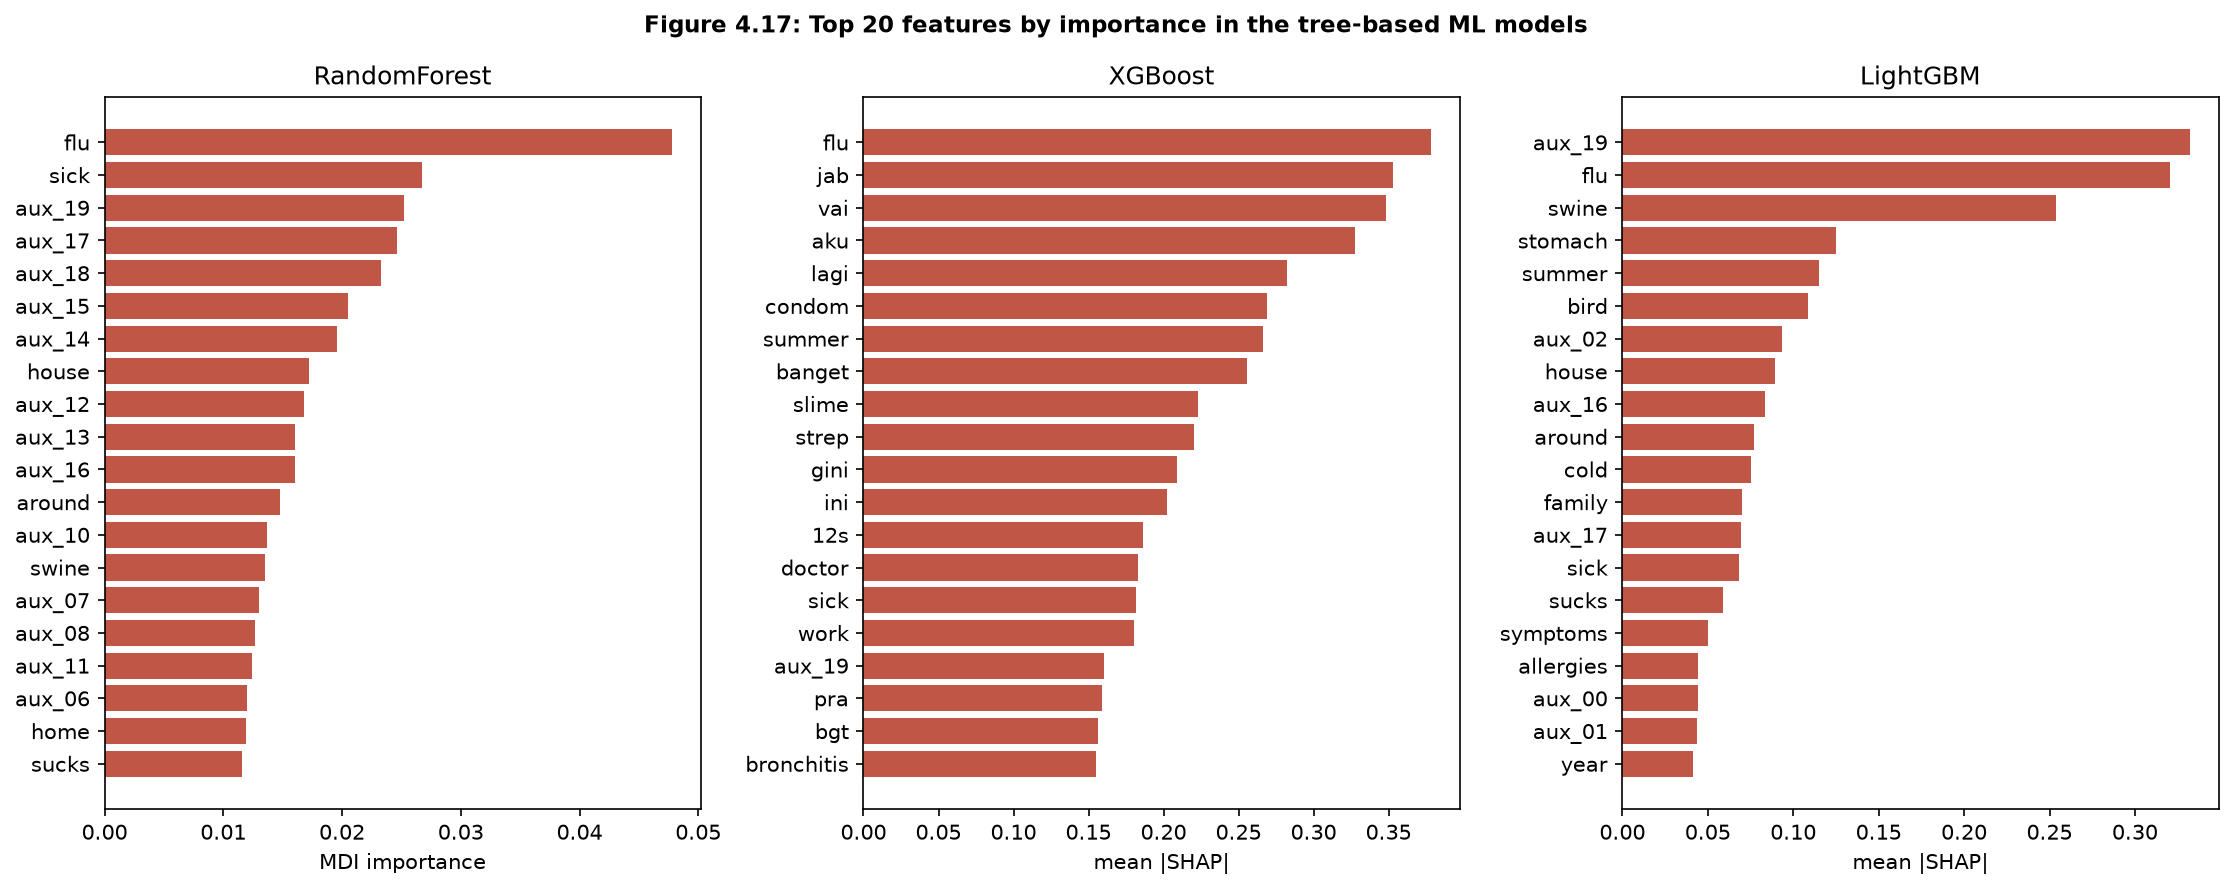

'figures/fig4_17_ml_feature_importance.png'

In [32]:
fig, ax = plt.subplots(1, 2, figsize=(13, 6))
s = pd.concat([L2_NEG, L2_POS[::-1]])
ax[0].barh(s.index, s.values, color=["#2a6f97" if v < 0 else "#c05746" for v in s.values]); ax[0].set_xlabel("Coefficient (log1p+MaxAbs scale)")
ax[0].set_title("LogReg-L2: 15 most positive / negative")
bm = pd.Series(bayes.coef_mean, index=bayes.feature_names); bsd_ = pd.Series(bayes.b_draws.std(0), index=bayes.feature_names)
top_b = bm.abs().sort_values(ascending=False).head(20).index[::-1]
lo = np.percentile(bayes.b_draws, 3, axis=0); hi = np.percentile(bayes.b_draws, 97, axis=0); pos = {f: i for i, f in enumerate(bayes.feature_names)}
ax[1].errorbar(bm[top_b], range(len(top_b)), xerr=[bm[top_b] - lo[[pos[f] for f in top_b]], hi[[pos[f] for f in top_b]] - bm[top_b]], fmt="o", color="#2a6f97")
ax[1].set_yticks(range(len(top_b))); ax[1].set_yticklabels(top_b); ax[1].axvline(0, color="k", lw=0.8)
ax[1].set_title("Bayesian horseshoe LR: posterior mean, 94% interval (top 20)"); ax[1].set_xlabel("Coefficient (standardised log1p)")
save_fig(fig, "logistic_coefficients", "Keyword effects in the statistical models")

fig = plt.figure(figsize=(9, 7))
shap.summary_plot(SHAP_VALS[BEST_ML if BEST_ML in SHAP_VALS else "LightGBM"], Xs_dense, feature_names=feature_names, max_display=20, show=False, plot_size=None)
fig = plt.gcf(); save_fig(fig, "shap_summary", f"SHAP summary for {BEST_ML if BEST_ML in SHAP_VALS else 'LightGBM'} (3,000 random test rows, top 20 features)")

fig, ax = plt.subplots(1, 3, figsize=(15, 6))
for a, n in zip(ax, ("RandomForest", "XGBoost", "LightGBM")):
    t = IMP[n].sort_values(ascending=False).head(20)[::-1]; a.barh(t.index, t.values, color="#c05746"); a.set_title(n)
    a.set_xlabel("MDI importance" if n == "RandomForest" else "mean |SHAP|")
save_fig(fig, "ml_feature_importance", "Top 20 features by importance in the tree-based ML models")

## 13. Compute time (RQ4)

,tuning_s,fit_s,predict_test_s,predict_per_1k_ms
LightGBM,56.470,0.778,0.034,1.467
XGBoost,34.968,0.714,0.035,1.492
LogReg-L1,17.736,3.977,0.016,0.706
LogReg-L2,1.383,0.277,0.011,0.473
RandomForest,153.075,10.362,0.103,4.413
NegBin-count,0.000,2.392,0.009,0.380
Bayesian-LR (horseshoe),0.000,91.572,0.210,9.014
Poisson-count,0.000,1.287,0.009,0.390
MLP,59.282,46.476,0.050,2.162


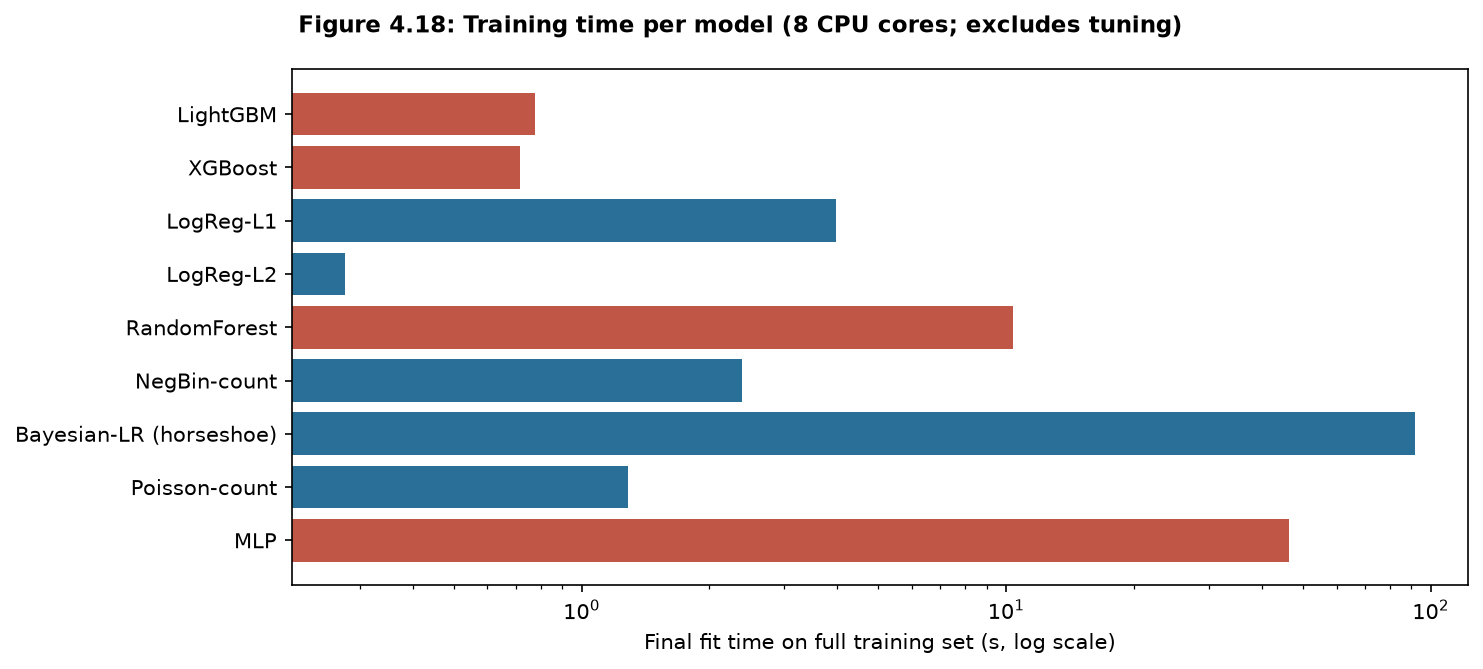

{'python': '3.13.5',
 'sklearn': '1.9.1',
 'lightgbm': '4.7.0',
 'xgboost': '3.4.1',
 'shap': '0.54.1',
 'cpu_cores': 8,
 'platform': 'Linux-6.12.113+-x86_64-with-glibc2.41',
 'pymc': '6.4.0'}

In [33]:
TIM = pd.DataFrame(TIMES).T.loc[RES.index]; TIM.to_csv(os.path.join(RES_DIR, "runtime.csv")); display(TIM.round(3))
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(TIM.index[::-1], TIM.fit_s[::-1], color=["#2a6f97" if RES.loc[n, "family"] == "Statistical" else "#c05746" for n in TIM.index[::-1]])
ax.set_xscale("log"); ax.set_xlabel("Final fit time on full training set (s, log scale)")
save_fig(fig, "runtime", f"Training time per model ({N_JOBS} CPU cores; excludes tuning)")
import platform, sklearn
ENV = dict(python=platform.python_version(), sklearn=sklearn.__version__, lightgbm=lgb.__version__, xgboost=xgb.__version__, shap=shap.__version__,
           cpu_cores=N_JOBS, platform=platform.platform())
try: ENV["pymc"] = pm.__version__
except Exception: pass
ENV

## 14. Improved models and statistical validation (strictly temporal protocol)
This section was added to answer two questions left open by sections 7–11: *can the Twitter models be made more accurate without touching the test split?*, and *are the differences between models statistically significant?*

**Protocol (no tuning on test).** The last two of the five contiguous training blocks (time steps 657–1094, all 48 states) form a validation block, scored by rolling origin:
the models are fitted on steps 0–656 and predict steps 657–875, then fitted on steps 0–875 and predict steps 876–1094. The pooled out-of-time predictions are used for
every choice in this section: feature set, LightGBM and LogReg-L1 settings, calibration method, ensemble weight and decision thresholds. The chosen configurations are then
refitted on the full training period (steps 0–1094) and the test split (steps 1095–1579) is scored once.

**14.1 Temporal features.** Rows are time steps, not weeks, so the windows below are in steps. For each state, using only rows at or before step *t*: lags 1, 2, 4, 7 and 14,
trailing means and standard deviations over 7 and 28 steps, the 7-step change in the 7-step mean, and the difference between the 7- and 28-step means. These are computed on
log(1 + count) for the 20 aux columns, the 50 most frequent keywords (chosen on training counts) and the total keyword count. Train and test are one contiguous series per state
(checked below), so the first test steps use the end of the training period as history, which is information available at prediction time.

A separate **label-history** block (the outbreak label 14 and 21 steps earlier and its 28-step mean) assumes that surveillance labels become known with a delay of at least 14 steps.
Models that use it are reported as a separate *surveillance-augmented* track, because they no longer rely on Twitter data alone; a persistence baseline (predict the label from
14 steps earlier) and a label-history-only model are included as references.

In [34]:
# ---------------------------------------------------------------------------------------------- 14.1 temporal features
# All features for row t of a state use only rows <= t of that state's contiguous train+test series
# (the test steps directly follow the training steps; see the boundary check printed below).
from sklearn.base import clone
N_TOPKW = 50
kw_tot_tr = np.asarray(X_tr[:, N_AUX:].sum(0)).ravel()
TOPKW_IDX = N_AUX + np.argsort(-kw_tot_tr)[:N_TOPKW]            # chosen on training counts only
SERIES_IDX = np.r_[np.arange(N_AUX), TOPKW_IDX]                  # aux columns + top-50 keywords (+ total, added below)
SERIES_NAMES = [feature_names[j] for j in SERIES_IDX] + ["kw_total"]
LAGS, WINS = (1, 2, 4, 7, 14), (7, 28)
LABEL_DELAY = 14                                                 # label history is only used with a reporting delay of >= 14 steps

def _lag(A, k):
    out = np.zeros_like(A, dtype=np.float64)
    if k < A.shape[0]: out[k:] = A[:-k]
    return out
def _roll(A, w):
    """Trailing mean and std over rows t-w+1..t (shorter window at the series start)."""
    c1 = np.cumsum(np.vstack([np.zeros((1, A.shape[1])), A]), 0); c2 = np.cumsum(np.vstack([np.zeros((1, A.shape[1])), A ** 2]), 0)
    t = np.arange(A.shape[0]); lo = np.maximum(0, t - w + 1); n = (t + 1 - lo)[:, None]
    m = (c1[t + 1] - c1[lo]) / n; v = np.clip((c2[t + 1] - c2[lo]) / n - m ** 2, 0, None)
    return m, np.sqrt(v)

def build_temporal(label_delays=()):
    n_tr, n_te = DATASET["steps_train"], DATASET["steps_test"]
    F_tr, F_te, names = [], [], None
    for i, s in enumerate(states):
        A = sp.vstack([X_tr[i * n_tr:(i + 1) * n_tr], X_te[i * n_te:(i + 1) * n_te]]).toarray()
        yv = np.r_[y_tr[i * n_tr:(i + 1) * n_tr], y_te[i * n_te:(i + 1) * n_te]].astype(float)[:, None]
        assert (A[:n_tr] == X_tr[i * n_tr:(i + 1) * n_tr].toarray()).all() and state_tr[i * n_tr] == s
        S = np.log1p(np.c_[A[:, SERIES_IDX], A[:, N_AUX:].sum(1)])          # log1p series
        parts, nm = [], []
        for k in LAGS: parts.append(_lag(S, k)); nm += [f"{n}_lag{k}" for n in SERIES_NAMES]
        for w in WINS:
            m, sd = _roll(S, w); parts += [m, sd]; nm += [f"{n}_mean{w}" for n in SERIES_NAMES] + [f"{n}_std{w}" for n in SERIES_NAMES]
        m7, _ = _roll(S, 7); m28, _ = _roll(S, 28)
        parts += [m7 - _lag(m7, 7), m7 - m28]; nm += [f"{n}_chg7" for n in SERIES_NAMES] + [f"{n}_m7_minus_m28" for n in SERIES_NAMES]
        for d in label_delays:
            parts += [_lag(yv, d), _lag(yv, d + 7), _roll(_lag(yv, d), 28)[0]]
            nm += [f"y_lag{d}", f"y_lag{d + 7}", f"y_lag{d}_mean28"]
        F = np.hstack(parts).astype(np.float32)
        F_tr.append(F[:n_tr]); F_te.append(F[n_tr:]); names = nm
    return np.vstack(F_tr), np.vstack(F_te), names

t0 = time.time()
FT_tr, FT_te, FT_names = build_temporal()
FL_tr, FL_te, FL_names = build_temporal(label_delays=(LABEL_DELAY,))
FL_tr, FL_te, FL_names = FL_tr[:, -3:], FL_te[:, -3:], FL_names[-3:]           # label-history block only
print(f"temporal block: {FT_tr.shape[1]} columns; label-history block: {FL_names}; built in {time.time() - t0:.1f}s")

# boundary check: is the first test step a continuation of the last training step?
def _cos(a, b):
    a = np.log1p(a.toarray().ravel()); b = np.log1p(b.toarray().ravel()); return float(a @ b / np.sqrt((a @ a) * (b @ b) + 1e-12))
rng_ = np.random.default_rng(SEED); n_tr, n_te = DATASET["steps_train"], DATASET["steps_test"]
BOUNDARY = dict(
    cos_last_two_train_steps=np.mean([_cos(X_tr[i * n_tr + n_tr - 2], X_tr[i * n_tr + n_tr - 1]) for i in range(len(states))]),
    cos_last_train_first_test=np.mean([_cos(X_tr[i * n_tr + n_tr - 1], X_te[i * n_te]) for i in range(len(states))]),
    cos_random_train_test_pair=np.mean([_cos(X_tr[i * n_tr + rng_.integers(n_tr)], X_te[i * n_te + rng_.integers(n_te)]) for i in range(len(states))]),
    label_agreement_at_boundary=float(np.mean([y_tr[i * n_tr + n_tr - 1] == y_te[i * n_te] for i in range(len(states))])))
print(BOUNDARY)

FEATURE_SETS = {
    "base (545)": (X_tr, X_te),
    "base + temporal": (sp.hstack([X_tr, sp.csr_matrix(FT_tr)]).tocsr(), sp.hstack([X_te, sp.csr_matrix(FT_te)]).tocsr()),
    "temporal only": (sp.csr_matrix(FT_tr), sp.csr_matrix(FT_te)),
    "base + temporal + label history": (sp.hstack([X_tr, sp.csr_matrix(FT_tr), sp.csr_matrix(FL_tr)]).tocsr(),
                                        sp.hstack([X_te, sp.csr_matrix(FT_te), sp.csr_matrix(FL_te)]).tocsr()),
}
FEATURE_NAMES = {"base (545)": feature_names, "base + temporal": feature_names + FT_names, "temporal only": FT_names,
                 "base + temporal + label history": feature_names + FT_names + FL_names}


temporal block: 781 columns; label-history block: ['y_lag14', 'y_lag21', 'y_lag14_mean28']; built in 1.4s
{'cos_last_two_train_steps': np.float64(0.725546698403862), 'cos_last_train_first_test': np.float64(0.7149280034937965), 'cos_random_train_test_pair': np.float64(0.5043506134855557), 'label_agreement_at_boundary': 1.0}


**14.2 Validation block** (rolling origin, pooled).

In [35]:
# ---------------------------------------------------------------------------------------------- 14.2 strictly temporal validation
# Validation = the last two of five contiguous training blocks, scored by rolling origin, per state and in time order:
#   origin 1: fit on steps 0-656    -> predict steps 657-875
#   origin 2: fit on steps 0-875    -> predict steps 876-1094
# The pooled out-of-time predictions (both origins, all 48 states) form the validation set used for every choice below
# (feature set, LightGBM settings, calibrator, thresholds, ensemble weight). The test split is used only once, at the end.
VAL_ORIGINS = (3, 4)
VAL_FOLDS = [(np.isin(t_tr, np.concatenate(blocks[:k])), np.isin(t_tr, blocks[k])) for k in VAL_ORIGINS]
y_val = np.concatenate([y_tr[va] for _, va in VAL_FOLDS])
t_val = np.concatenate([t_tr[va] for _, va in VAL_FOLDS]); state_val = np.concatenate([state_tr[va] for _, va in VAL_FOLDS])
VAL_INFO = dict(val_steps=f"{blocks[VAL_ORIGINS[0]][0]}-{blocks[VAL_ORIGINS[-1]][-1]}", n_val=len(y_val), val_positives=int(y_val.sum()),
                val_prevalence=float(y_val.mean()), origin1_train_steps=f"0-{blocks[VAL_ORIGINS[0]][0] - 1}",
                origin2_train_steps=f"0-{blocks[VAL_ORIGINS[1]][0] - 1}")
print(VAL_INFO)

def lin_matrix(Xa, F=None):
    """Linear-model input: log1p of the raw counts, then the (already log-scaled) temporal columns."""
    parts = [sparse_log1p(Xa)] + ([sp.csr_matrix(F)] if F is not None else [])
    return sp.hstack(parts).tocsr()
LIN_SETS = {"base (545)": (lin_matrix(X_tr), lin_matrix(X_te)),
            "base + temporal": (lin_matrix(X_tr, FT_tr), lin_matrix(X_te, FT_te)),
            "temporal only": (sp.csr_matrix(FT_tr), sp.csr_matrix(FT_te)),
            "base + temporal + label history": (lin_matrix(X_tr, np.c_[FT_tr, FL_tr]), lin_matrix(X_te, np.c_[FT_te, FL_te]))}

def make_lgbm(y_fit, **kw):
    p = dict(subsample=0.8, subsample_freq=1, colsample_bytree=0.8, n_jobs=N_JOBS, random_state=SEED, verbose=-1,
             learning_rate=0.05, n_estimators=400, num_leaves=15)            # the CV-tuned baseline settings (section 6)
    p.update(kw); p["scale_pos_weight"] = float((y_fit == 0).sum() / (y_fit == 1).sum())
    return lgb.LGBMClassifier(**p)
def make_l1(C=0.1):
    return Pipeline([("scale", MaxAbsScaler()), ("clf", LogisticRegression(penalty="l1", solver="liblinear", class_weight="balanced",
                                                                             C=C, max_iter=5000, random_state=SEED))])
def val_predict(kind, Xa, **kw):
    out = []
    for tr_m, va_m in VAL_FOLDS:
        m = (make_lgbm(y_tr[tr_m], **kw) if kind == "LightGBM" else make_l1(**kw)).fit(Xa[tr_m], y_tr[tr_m])
        out.append(m.predict_proba(Xa[va_m])[:, 1])
    return np.concatenate(out)


{'val_steps': '657-1094', 'n_val': 21024, 'val_positives': 1981, 'val_prevalence': 0.09422564687975647, 'origin1_train_steps': '0-656', 'origin2_train_steps': '0-875'}


**14.3 Candidate grid.** LightGBM: `num_leaves` ∈ {7, 31}, `min_child_samples` ∈ {20, 200}, `n_estimators` ∈ {100, 200, 400} (learning rate 0.05, fold-specific `scale_pos_weight`). LogReg-L1: C ∈ {0.003, 0.005, 0.01, 0.03, 0.1}. Each is scored by validation PR-AUC on three feature sets.

In [36]:
# ---------------------------------------------------------------------------------------------- 14.3 candidate grid, scored on validation only
import itertools
from sklearn.isotonic import IsotonicRegression
LGB_GRID = [dict(num_leaves=nl, min_child_samples=mcs, n_estimators=ne) for nl, mcs, ne in itertools.product((7, 31), (20, 200), (100, 200, 400))]
L1_GRID = [dict(C=c) for c in (0.003, 0.005, 0.01, 0.03, 0.1)]
CAND_SETS = ["base (545)", "base + temporal", "base + temporal + label history"]
TWITTER_ONLY = {"base (545)", "base + temporal"}
VAL_ROWS, VALP = [], {}
t_grid = time.time()
for fs in CAND_SETS:
    for kind, grid, Xa in (("LightGBM", LGB_GRID, FEATURE_SETS[fs][0]), ("LogReg-L1", L1_GRID, LIN_SETS[fs][0])):
        for g in grid:
            t0 = time.time(); p = val_predict(kind, Xa, **g); key = (kind, fs, json.dumps(g)); VALP[key] = p
            VAL_ROWS.append(dict(model=kind, feature_set=fs, settings=json.dumps(g), n_features=Xa.shape[1],
                                 val_pr_auc=average_precision_score(y_val, p), val_roc_auc=roc_auc_score(y_val, p), seconds=time.time() - t0))
# reference points on the same validation rows
y_lag_val = np.concatenate([FL_tr[va, 0] for _, va in VAL_FOLDS])
VAL_ROWS.append(dict(model="Persistence (label 14 steps earlier)", feature_set="label history", settings="none", n_features=1,
                     val_pr_auc=average_precision_score(y_val, y_lag_val), val_roc_auc=roc_auc_score(y_val, y_lag_val), seconds=0.0))
p = val_predict("LogReg-L1", sp.csr_matrix(FL_tr), C=1.0); VALP[("LogReg-L1", "label history only", '{"C": 1.0}')] = p
VAL_ROWS.append(dict(model="LogReg-L1", feature_set="label history only", settings='{"C": 1.0}', n_features=FL_tr.shape[1],
                     val_pr_auc=average_precision_score(y_val, p), val_roc_auc=roc_auc_score(y_val, p), seconds=0.0))
VALGRID = pd.DataFrame(VAL_ROWS); VALGRID.to_csv(os.path.join(RES_DIR, "improve_validation_grid.csv"), index=False)
print(f"validation grid: {len(VALGRID)} runs in {time.time() - t_grid:.0f}s")
BEST_CFG = (VALGRID[VALGRID.model.isin(["LightGBM", "LogReg-L1"]) & VALGRID.feature_set.isin(CAND_SETS)]
            .sort_values("val_pr_auc", ascending=False).groupby(["model", "feature_set"], sort=False).head(1)
            .set_index(["model", "feature_set"]).sort_index())
display(BEST_CFG)


validation grid: 53 runs in 414s


settings  \
model     feature_set                                                                          
LightGBM  base (545)                       {"num_leaves": 7, "min_child_samples": 200, "n...   
          base + temporal                  {"num_leaves": 31, "min_child_samples": 200, "...   
          base + temporal + label history  {"num_leaves": 31, "min_child_samples": 200, "...   
LogReg-L1 base (545)                                                             {"C": 0.03}   
          base + temporal                                                       {"C": 0.005}   
          base + temporal + label history                                        {"C": 0.01}   

                                           n_features  val_pr_auc  \
model     feature_set                                               
LightGBM  base (545)                              545    0.285991   
          base + temporal                        1326    0.336014   
          base + temporal + label history        1329    0.562286   
LogReg-L1 base (545)                              545    0.399023   
          base + temporal                        1326    0.441696   
          base + temporal + label history        1329    0.568808   

                                           val_roc_auc   seconds  
model     feature_set                                             
LightGBM  base (545)                          0.733206  0.581376  
          base + temporal                     0.730160  8.053600  
          base + temporal + label history     0.834124  4.552077  
LogReg-L1 base (545)                          0.813650  1.035490  
          base + temporal                     0.851925  4.723213  
          base + temporal + label history     0.892365  5.730570

**14.4 Refit, calibration, ensemble and operating points.** Calibrators (Platt = logistic regression on the logit of the score; isotonic regression) are fitted on the
validation predictions only. The method is chosen by cross-fitted validation Brier score. The ensemble averages the calibrated Twitter-only LightGBM and LogReg-L1 probabilities,
with the LightGBM weight chosen on validation PR-AUC (grid 0, 0.05, …, 1). Three operating points are chosen on the calibrated validation predictions: best F1, best MCC and an
early-warning point (the highest threshold with validation recall ≥ 0.80). They are applied unchanged to the test split.

In [37]:
# ---------------------------------------------------------------------------------------------- 14.4 refit chosen configurations, calibrate, set thresholds
# For every (model, feature set) pair the best validation setting is refitted on the full training period and scored on test
# once. Which model is "the improved model" is decided from validation only:
#   * Twitter-only track  : best validation PR-AUC among the base and base + temporal feature sets
#   * surveillance-augmented track : base + temporal + label history (uses outbreak labels known >= 14 steps earlier)
def fit_full(kind, fs, g):
    if kind == "LightGBM": return make_lgbm(y_tr, **g).fit(FEATURE_SETS[fs][0], y_tr)
    return make_l1(**g).fit(LIN_SETS[fs][0], y_tr)
def test_input(kind, fs): return FEATURE_SETS[fs][1] if kind == "LightGBM" else LIN_SETS[fs][1]

NEW_MODELS, NEW_TEST_RAW, NEW_VAL_RAW, NEW_CFG = {}, {}, {}, {}
for (kind, fs), r in BEST_CFG.iterrows():
    g = json.loads(r.settings); nm = f"{kind} | {fs}"
    NEW_MODELS[nm] = fit_full(kind, fs, g); NEW_TEST_RAW[nm] = NEW_MODELS[nm].predict_proba(test_input(kind, fs))[:, 1]
    NEW_VAL_RAW[nm] = VALP[(kind, fs, r.settings)]; NEW_CFG[nm] = dict(model=kind, feature_set=fs, settings=r.settings)
# the original baselines (sections 5-7) under the same validation protocol: base features with their CV-tuned settings
for kind, g in (("LightGBM", dict(num_leaves=15, min_child_samples=20, n_estimators=400)), ("LogReg-L1", dict(C=0.1))):
    nm = f"{kind} (baseline)"
    NEW_VAL_RAW[nm] = val_predict(kind, FEATURE_SETS["base (545)"][0] if kind == "LightGBM" else LIN_SETS["base (545)"][0], **g)
    NEW_TEST_RAW[nm] = PROBS[kind]; NEW_CFG[nm] = dict(model=kind, feature_set="base (545)", settings=json.dumps(g) + " (sections 5-7)")
    NEW_MODELS[nm] = MODELS[kind]
# label history alone (no Twitter data): the reference for "what do the tweets add on top of surveillance history?"
nm = "LogReg-L1 | label history only"
NEW_MODELS[nm] = make_l1(C=1.0).fit(sp.csr_matrix(FL_tr), y_tr); NEW_TEST_RAW[nm] = NEW_MODELS[nm].predict_proba(sp.csr_matrix(FL_te))[:, 1]
NEW_VAL_RAW[nm] = VALP[("LogReg-L1", "label history only", '{"C": 1.0}')]; NEW_CFG[nm] = dict(model="LogReg-L1", feature_set="label history only", settings='{"C": 1.0}')
LABEL_ONLY = nm

tw = BEST_CFG.reset_index(); tw = tw[tw.feature_set.isin(TWITTER_ONLY)].sort_values("val_pr_auc", ascending=False)
BEST_TW = f"{tw.iloc[0].model} | {tw.iloc[0].feature_set}"
BEST_TW_LGB = f"LightGBM | {tw[tw.model == 'LightGBM'].iloc[0].feature_set}"; BEST_TW_L1 = f"LogReg-L1 | {tw[tw.model == 'LogReg-L1'].iloc[0].feature_set}"
lab = BEST_CFG.reset_index(); lab = lab[lab.feature_set == "base + temporal + label history"].sort_values("val_pr_auc", ascending=False)
BEST_LAB = f"{lab.iloc[0].model} | {lab.iloc[0].feature_set}"
print("Best Twitter-only (validation):", BEST_TW, "| ensemble members:", BEST_TW_LGB, "+", BEST_TW_L1, "| best label-augmented:", BEST_LAB)

# --- calibration: Platt (logistic regression on the logit) and isotonic, fitted on the pooled validation predictions.
# The method is chosen by cross-fitted validation Brier score (fit on one origin's block, score on the other). The chosen
# calibrator is then refitted on all validation predictions and applied to (a) the validation predictions, which are used to
# choose the ensemble weight and the thresholds, and (b) the test predictions.
VAL_ORIGIN_ID = np.concatenate([np.full(va.sum(), j) for j, (_, va) in enumerate(VAL_FOLDS)])
def _logit(p): p = np.clip(p, 1e-6, 1 - 1e-6); return np.log(p / (1 - p))
def fit_cal(method, p, y):
    if method == "Platt":
        lr = LogisticRegression(C=1e6, max_iter=1000).fit(_logit(p)[:, None], y)
        f = lambda q: lr.predict_proba(_logit(q)[:, None])[:, 1]; f.params = dict(slope=float(lr.coef_[0, 0]), intercept=float(lr.intercept_[0])); return f
    iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(p, y); f = iso.predict; return f
def crossfit_cal(method, p):
    out = np.empty_like(p, dtype=float)
    for j in (0, 1):
        f = fit_cal(method, p[VAL_ORIGIN_ID != j], y_val[VAL_ORIGIN_ID != j]); out[VAL_ORIGIN_ID == j] = f(p[VAL_ORIGIN_ID == j])
    return out
CAL_ROWS2, NEW_TEST_CAL, NEW_VAL_CAL, CAL_METHOD, CAL_FN = [], {}, {}, {}, {}
for nm in NEW_TEST_RAW:
    row = dict(model=nm, val_brier_uncalibrated=brier_score_loss(y_val, NEW_VAL_RAW[nm]), test_brier_uncalibrated=brier_score_loss(y_te, NEW_TEST_RAW[nm]))
    cf = {}
    for meth in ("Platt", "isotonic"):
        cf[meth] = crossfit_cal(meth, NEW_VAL_RAW[nm]); row[f"val_brier_{meth}_crossfit"] = brier_score_loss(y_val, cf[meth])
        f = fit_cal(meth, NEW_VAL_RAW[nm], y_val); pt = f(NEW_TEST_RAW[nm]); CAL_FN[(nm, meth)] = f
        row[f"test_brier_{meth}"] = brier_score_loss(y_te, pt); row[f"test_pr_auc_{meth}"] = average_precision_score(y_te, pt)
        NEW_TEST_CAL[(nm, meth)] = pt
    best_m = "Platt" if row["val_brier_Platt_crossfit"] <= row["val_brier_isotonic_crossfit"] else "isotonic"
    CAL_METHOD[nm] = best_m; NEW_VAL_CAL[nm] = CAL_FN[(nm, best_m)](NEW_VAL_RAW[nm]); row["chosen_on_validation"] = best_m
    CAL_ROWS2.append(row)
CAL2 = pd.DataFrame(CAL_ROWS2).set_index("model"); CAL2.to_csv(os.path.join(RES_DIR, "improve_calibration.csv")); display(CAL2)

# --- ensemble of the calibrated Twitter-only LightGBM and LogReg-L1 (weight on LightGBM chosen by validation PR-AUC)
W_GRID = np.round(np.arange(0, 1.0001, 0.05), 2)
ENS_W = pd.DataFrame([dict(w_lightgbm=w, val_pr_auc=average_precision_score(y_val, w * NEW_VAL_CAL[BEST_TW_LGB] + (1 - w) * NEW_VAL_CAL[BEST_TW_L1]),
                           val_roc_auc=roc_auc_score(y_val, w * NEW_VAL_CAL[BEST_TW_LGB] + (1 - w) * NEW_VAL_CAL[BEST_TW_L1])) for w in W_GRID])
ENS_W.to_csv(os.path.join(RES_DIR, "improve_ensemble_weights.csv"), index=False)
W_BEST = float(ENS_W.loc[ENS_W.val_pr_auc.idxmax(), "w_lightgbm"])
ENS = "Ensemble (calibrated LightGBM + LogReg-L1)"
NEW_VAL_CAL[ENS] = W_BEST * NEW_VAL_CAL[BEST_TW_LGB] + (1 - W_BEST) * NEW_VAL_CAL[BEST_TW_L1]
NEW_TEST_CAL[(ENS, "ensemble")] = (W_BEST * NEW_TEST_CAL[(BEST_TW_LGB, CAL_METHOD[BEST_TW_LGB])] + (1 - W_BEST) * NEW_TEST_CAL[(BEST_TW_L1, CAL_METHOD[BEST_TW_L1])])
CAL_METHOD[ENS] = "ensemble"; NEW_CFG[ENS] = dict(model="ensemble", feature_set="Twitter-only", settings=f"w_LightGBM={W_BEST}; members: {BEST_TW_LGB} + {BEST_TW_L1}")
print("Ensemble weight on LightGBM chosen on validation:", W_BEST)
# the recommended Twitter-only model is whichever has the higher validation PR-AUC: the single best model or the ensemble
VAL_PR_CAL = {nm: average_precision_score(y_val, NEW_VAL_CAL[nm]) for nm in NEW_VAL_CAL}
REC_TW = ENS if VAL_PR_CAL[ENS] > VAL_PR_CAL[BEST_TW] else BEST_TW
print("Validation PR-AUC (calibrated):", {k: round(v, 6) for k, v in VAL_PR_CAL.items()}, "| recommended Twitter-only model:", REC_TW)

# --- operating points chosen on the calibrated validation predictions, then applied unchanged to test
def threshold_scan(y, p):
    o = np.argsort(-p, kind="mergesort"); ps = p[o]; ys = y[o]
    tp = np.cumsum(ys); fp = np.cumsum(1 - ys); last = np.r_[ps[1:] != ps[:-1], True]
    tp, fp, thr = tp[last], fp[last], ps[last]; P = ys.sum(); N = len(ys) - P; fn = P - tp; tn = N - fp
    prec = tp / np.maximum(tp + fp, 1); rec = tp / P; f1 = 2 * tp / np.maximum(2 * tp + fp + fn, 1)
    den = np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)); mcc = np.where(den > 0, (tp * tn - fp * fn) / np.where(den > 0, den, 1), 0)
    return pd.DataFrame(dict(threshold=thr, precision=prec, recall=rec, f1=f1, mcc=mcc))
EW_RECALL = 0.80
def operating_points(y, p):
    sc = threshold_scan(y, p)
    ok = sc[sc.recall >= EW_RECALL]
    return {"best F1": float(sc.loc[sc.f1.idxmax(), "threshold"]), "best MCC": float(sc.loc[sc.mcc.idxmax(), "threshold"]),
            f"early warning (val recall >= {EW_RECALL:.2f})": float(ok.threshold.max())}
def test_prob(nm): return NEW_TEST_CAL[(nm, CAL_METHOD[nm])]
OP_ROWS, OPS = [], {}
for nm in NEW_VAL_CAL:
    OPS[nm] = operating_points(y_val, NEW_VAL_CAL[nm])
    for op, thr in OPS[nm].items():
        mv = metrics(y_val, NEW_VAL_CAL[nm], thr); mt = metrics(y_te, test_prob(nm), thr)
        OP_ROWS.append(dict(model=nm, calibration=CAL_METHOD[nm], operating_point=op, threshold=thr,
                            **{f"val_{k}": v for k, v in mv.items() if k != "threshold"}, **{f"test_{k}": v for k, v in mt.items() if k != "threshold"},
                            test_alerts_per_1000=1000 * float((test_prob(nm) >= thr).mean())))
OPT = pd.DataFrame(OP_ROWS); OPT.to_csv(os.path.join(RES_DIR, "improve_operating_points.csv"), index=False)

# persistence reference on test (binary score: outbreak label 14 steps earlier)
P_PERSIST = FL_te[:, 0].astype(float)
PERSIST_TEST = metrics(y_te, P_PERSIST, 0.5)
display(OPT[["model", "operating_point", "threshold", "val_f1", "val_mcc", "val_recall", "test_f1", "test_mcc", "test_precision", "test_recall"]])


Best Twitter-only (validation): LogReg-L1 | base + temporal | ensemble members: LightGBM | base + temporal + LogReg-L1 | base + temporal | best label-augmented: LogReg-L1 | base + temporal + label history


,val_brier_uncalibrated,test_brier_uncalibrated,val_brier_Platt_crossfit,test_brier_Platt,test_pr_auc_Platt,val_brier_isotonic_crossfit,test_brier_isotonic,test_pr_auc_isotonic,chosen_on_validation
model,,,,,,,,,
LightGBM | base (545),0.172094,0.149143,0.081662,0.076045,0.361561,0.082064,0.075994,0.346302,Platt
LightGBM | base + temporal,0.079486,0.067709,0.096190,0.070507,0.514190,0.097899,0.070442,0.484655,Platt
LightGBM | base + temporal + label history,0.058679,0.062935,0.062356,0.055763,0.628836,0.064492,0.056673,0.605814,Platt
LogReg-L1 | base (545),0.191274,0.153918,0.071871,0.076477,0.370651,0.072058,0.076129,0.354346,Platt
LogReg-L1 | base + temporal,0.181593,0.155351,0.066545,0.070287,0.429097,0.068596,0.070715,0.413138,Platt
LogReg-L1 | base + temporal + label history,0.102356,0.106971,0.065500,0.051070,0.660423,0.066122,0.051883,0.604962,Platt
LightGBM (baseline),0.136409,0.134990,0.091647,0.081625,0.382267,0.089443,0.075391,0.352840,isotonic
LogReg-L1 (baseline),0.179029,0.152987,0.075837,0.075969,0.376068,0.074821,0.075374,0.357812,isotonic
LogReg-L1 | label history only,0.122958,0.130957,0.070925,0.058355,0.463752,0.080349,0.060648,0.445051,Platt


Ensemble weight on LightGBM chosen on validation: 0.45
Validation PR-AUC (calibrated): {'LightGBM | base (545)': 0.285991, 'LightGBM | base + temporal': 0.336014, 'LightGBM | base + temporal + label history': 0.562286, 'LogReg-L1 | base (545)': 0.399023, 'LogReg-L1 | base + temporal': 0.441696, 'LogReg-L1 | base + temporal + label history': 0.568808, 'LightGBM (baseline)': 0.200117, 'LogReg-L1 (baseline)': 0.360332, 'LogReg-L1 | label history only': 0.45446, 'Ensemble (calibrated LightGBM + LogReg-L1)': 0.469692} | recommended Twitter-only model: Ensemble (calibrated LightGBM + LogReg-L1)


,model,operating_point,threshold,val_f1,val_mcc,val_recall,test_f1,test_mcc,test_precision,test_recall
0,LightGBM | base (545),best F1,0.152951,0.326515,0.246745,0.439172,0.396403,0.324449,0.346204,0.463628
1,LightGBM | base (545),best MCC,0.224130,0.310497,0.247502,0.283695,0.372386,0.319637,0.438056,0.323839
2,LightGBM | base (545),early warning (val recall >= 0.80),0.061384,0.246885,0.183038,0.800101,0.294923,0.243957,0.180687,0.801928
3,LightGBM | base + temporal,best F1,0.172238,0.363200,0.290246,0.420495,0.382187,0.349621,0.249698,0.814198
4,LightGBM | base + temporal,best MCC,0.172238,0.363200,0.290246,0.420495,0.382187,0.349621,0.249698,0.814198
5,LightGBM | base + temporal,early warning (val recall >= 0.80),0.059996,0.232712,0.159869,0.800101,0.204845,0.130709,0.114202,0.992989
6,LightGBM | base + temporal + label history,best F1,0.327063,0.574468,0.536213,0.531550,0.650436,0.616703,0.555556,0.784400
7,LightGBM | base + temporal + label history,best MCC,0.379052,0.571757,0.540231,0.501767,0.660121,0.625048,0.579960,0.765995
8,LightGBM | base + temporal + label history,early warning (val recall >= 0.80),0.050644,0.325328,0.287952,0.800101,0.268041,0.243610,0.155400,0.974145
9,LogReg-L1 | base (545),best F1,0.166864,0.429072,0.364906,0.494700,0.376784,0.318827,0.420399,0.341367


**14.5 Uncertainty and significance.** 95% confidence intervals come from a circular block bootstrap (Politis and Romano, 1992; a variant of the moving-block bootstrap of
Künsch, 1989) over the 485 test time steps. Each replicate draws blocks of 28 consecutive steps (wrapping at the end) and keeps all 48 states for every drawn step, so serial
and cross-state dependence are both preserved. B = 2,000 replicates, seed 42, and all models are scored on the same replicates (paired). Differences in PR-AUC, ROC-AUC, F1 and
MCC are tested with the paired bootstrap (two-sided percentile p-value, Holm-adjusted within each metric). ROC-AUC differences are also tested with DeLong et al. (1988), using
the fast algorithm of Sun and Xu (2014). The implementation was checked against a direct O(n²) computation. DeLong treats rows as independent, which these autocorrelated data
are not, so its p-values are reported for completeness and the block bootstrap is the primary test. Block length sensitivity (1, 7, 14, 28 and 56 steps) is reported for PR-AUC.

In [38]:
# ---------------------------------------------------------------------------------------------- DeLong test (fast algorithm)
# DeLong, DeLong & Clarke-Pearson (1988), using the O(n log n) midrank algorithm of Sun & Xu (2014).
from scipy import stats as _st
def _midrank(x):
    J = np.argsort(x, kind="mergesort"); Z = x[J]; N = len(x); T = np.zeros(N); i = 0
    while i < N:
        j = i
        while j < N and Z[j] == Z[i]: j += 1
        T[i:j] = 0.5 * (i + j - 1) + 1; i = j
    out = np.empty(N); out[J] = T; return out
def delong_cov(y, preds):
    """AUCs and their DeLong covariance matrix for k score vectors (rows of `preds`) on the same cases."""
    y = np.asarray(y).astype(int); order = np.r_[np.where(y == 1)[0], np.where(y == 0)[0]]; m = int(y.sum())
    P = np.atleast_2d(np.asarray(preds, dtype=float))[:, order]; n = P.shape[1] - m; k = P.shape[0]
    tx = np.array([_midrank(r[:m]) for r in P]); ty = np.array([_midrank(r[m:]) for r in P]); tz = np.array([_midrank(r) for r in P])
    auc = tz[:, :m].sum(1) / m / n - (m + 1.0) / (2.0 * n)
    v01 = (tz[:, :m] - tx) / n; v10 = 1.0 - (tz[:, m:] - ty) / m
    S = np.atleast_2d(np.cov(v01)) / m + np.atleast_2d(np.cov(v10)) / n
    return auc, S
def delong_test(y, p_a, p_b):
    auc, S = delong_cov(y, np.vstack([p_a, p_b]))
    d = auc[0] - auc[1]; se = float(np.sqrt(S[0, 0] + S[1, 1] - 2 * S[0, 1]))
    z = d / se if se > 0 else np.nan
    return dict(auc_a=float(auc[0]), auc_b=float(auc[1]), diff=float(d), se=se, z=float(z), p=float(2 * _st.norm.sf(abs(z))))

# ---------------------------------------------------------------------------------------------- 14.5 block bootstrap CIs and significance tests
# Circular block bootstrap (Politis & Romano, 1992) over the 485 test time steps. A replicate draws ceil(485 / L) blocks of
# L consecutive steps (wrapping at the end) and keeps all 48 states for each drawn step, so both the serial dependence within
# a state and the cross-state (seasonal) dependence are preserved. All models are scored on the same replicate (paired).
BOOT_B, BOOT_L, BOOT_SEED = 2000, 28, SEED
n_te_steps = DATASET["steps_test"]; n_st = len(states)
assert (t_te.reshape(n_st, n_te_steps) == np.arange(n_te_steps) + DATASET["steps_train"]).all()
def cbb_indices(B, L, seed):
    rng_b = np.random.default_rng(seed); nb = int(np.ceil(n_te_steps / L))
    starts = rng_b.integers(0, n_te_steps, size=(B, nb))
    steps = ((starts[:, :, None] + np.arange(L)[None, None, :]) % n_te_steps).reshape(B, -1)[:, :n_te_steps]
    return steps                                                    # (B, 485) time-step indices
def rows_for(steps): return (np.arange(n_st)[:, None] * n_te_steps + steps[None, :]).ravel()

# autocorrelation of the cross-state outbreak share in the test period (used to justify L)
share = y_te.reshape(n_st, n_te_steps).mean(0)
ACF = {lag: float(np.corrcoef(share[:-lag], share[lag:])[0, 1]) for lag in (1, 7, 14, 28, 56)}
RUNLEN = []
for i in range(n_st):
    d = np.diff(np.r_[0, y_te.reshape(n_st, n_te_steps)[i], 0]); RUNLEN += list(np.where(d == -1)[0] - np.where(d == 1)[0])
print("ACF of test outbreak share:", ACF, "| median positive run length in test (steps):", float(np.median(RUNLEN)))

BOOT_MODELS = {"LightGBM (baseline)": (NEW_TEST_RAW["LightGBM (baseline)"], THRESH["LightGBM"]),
               "LogReg-L1 (baseline)": (NEW_TEST_RAW["LogReg-L1 (baseline)"], THRESH["LogReg-L1"])}
for nm in dict.fromkeys([BEST_TW, BEST_TW_LGB, ENS, BEST_LAB, LABEL_ONLY]):
    BOOT_MODELS[f"{nm} [calibrated]"] = (test_prob(nm), OPS[nm]["best F1"])
BOOT_MODELS["Persistence (label 14 steps earlier)"] = (P_PERSIST, 0.5)

def _thr_metrics(y, yh):
    tp = float((yh & (y == 1)).sum()); fp = float((yh & (y == 0)).sum()); fn = float((~yh & (y == 1)).sum()); tn = float(len(y)) - tp - fp - fn
    f1 = 2 * tp / max(2 * tp + fp + fn, 1); den = np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    return f1, ((tp * tn - fp * fn) / den if den > 0 else 0.0)
def boot_stats(steps_mat):
    out = {nm: np.empty((len(steps_mat), 4)) for nm in BOOT_MODELS}
    for b, steps in enumerate(steps_mat):
        r = rows_for(steps); yb = y_te[r]
        for nm, (p, thr) in BOOT_MODELS.items():
            pb = p[r]; out[nm][b] = (average_precision_score(yb, pb), roc_auc_score(yb, pb), *_thr_metrics(yb, pb >= thr))
    return out
t0 = time.time(); BOOT = boot_stats(cbb_indices(BOOT_B, BOOT_L, BOOT_SEED)); print(f"bootstrap B={BOOT_B}, L={BOOT_L}: {time.time() - t0:.0f}s")
MET4 = ["pr_auc", "roc_auc", "f1", "mcc"]
CI_ROWS = []
for nm, (p, thr) in BOOT_MODELS.items():
    yh = p >= thr; f1_, mcc_ = _thr_metrics(y_te, yh); point = dict(pr_auc=average_precision_score(y_te, p), roc_auc=roc_auc_score(y_te, p), f1=f1_, mcc=mcc_)
    for j, mt in enumerate(MET4):
        lo, hi = np.percentile(BOOT[nm][:, j], [2.5, 97.5])
        CI_ROWS.append(dict(model=nm, metric=mt, threshold=thr if mt in ("f1", "mcc") else np.nan, estimate=point[mt], ci_low=lo, ci_high=hi,
                            boot_se=float(BOOT[nm][:, j].std(ddof=1))))
CI = pd.DataFrame(CI_ROWS); CI.to_csv(os.path.join(RES_DIR, "improve_bootstrap_ci.csv"), index=False)
display(CI.pivot(index="model", columns="metric", values="estimate"))

# --- paired comparisons: block-bootstrap difference CIs and p-values, plus DeLong for ROC-AUC
def boot_p(d):
    """Two-sided percentile-bootstrap p-value for H0: difference = 0 (consistent with the percentile CI; smallest value 2/(B+1))."""
    return float(min(1.0, 2 * min(np.sum(d <= 0) + 1, np.sum(d >= 0) + 1) / (len(d) + 1)))
def holm(pv):
    pv = np.asarray(pv, float); o = np.argsort(pv); m = len(pv); adj = np.empty(m); run = 0.0
    for k, i in enumerate(o): run = max(run, min(1.0, (m - k) * pv[i])); adj[i] = run
    return adj
B_TW, B_ENS, B_LAB, B_LO = f"{BEST_TW} [calibrated]", f"{ENS} [calibrated]", f"{BEST_LAB} [calibrated]", f"{LABEL_ONLY} [calibrated]"
PAIRS = [(B_TW, "LightGBM (baseline)"), (B_TW, "LogReg-L1 (baseline)"), (B_ENS, "LightGBM (baseline)"), (B_ENS, "LogReg-L1 (baseline)"),
         (B_ENS, B_TW), ("LightGBM (baseline)", "LogReg-L1 (baseline)"), (B_LAB, B_TW), (B_LAB, B_LO), (B_LAB, "Persistence (label 14 steps earlier)")]
SIG_ROWS = []
for a, b in PAIRS:
    for j, mt in enumerate(MET4):
        pa, ta = BOOT_MODELS[a]; pb_, tb = BOOT_MODELS[b]
        if mt == "pr_auc": d_hat = average_precision_score(y_te, pa) - average_precision_score(y_te, pb_)
        elif mt == "roc_auc": d_hat = roc_auc_score(y_te, pa) - roc_auc_score(y_te, pb_)
        else: d_hat = _thr_metrics(y_te, pa >= ta)[j - 2] - _thr_metrics(y_te, pb_ >= tb)[j - 2]
        d = BOOT[a][:, j] - BOOT[b][:, j]; lo, hi = np.percentile(d, [2.5, 97.5])
        p_boot = boot_p(d)
        row = dict(model_a=a, model_b=b, metric=mt, diff_a_minus_b=d_hat, boot_ci_low=lo, boot_ci_high=hi, p_block_bootstrap=p_boot,
                   share_boot_diff_gt0=float((d > 0).mean()))
        if mt == "roc_auc":
            dl = delong_test(y_te, pa, pb_); row.update(delong_z=dl["z"], delong_se=dl["se"], p_delong=dl["p"])
        SIG_ROWS.append(row)
SIG = pd.DataFrame(SIG_ROWS)
for mt in MET4:
    k = SIG.metric == mt; SIG.loc[k, "p_block_bootstrap_holm"] = holm(SIG.loc[k, "p_block_bootstrap"])
k = SIG.metric == "roc_auc"; SIG.loc[k, "p_delong_holm"] = holm(SIG.loc[k, "p_delong"])
SIG.to_csv(os.path.join(RES_DIR, "improve_significance.csv"), index=False)
display(SIG[SIG.metric.isin(["pr_auc", "roc_auc"])])

# --- sensitivity of the PR-AUC intervals to the block length (B = 1000 each, same seed)
SENS_ROWS = []
keep = {nm: BOOT_MODELS[nm] for nm in ("LightGBM (baseline)", "LogReg-L1 (baseline)", B_TW, B_ENS)}
for Ls in (1, 7, 14, 28, 56):
    steps_mat = cbb_indices(1000, Ls, BOOT_SEED)
    vals = {nm: np.array([average_precision_score(y_te[rows_for(s)], keep[nm][0][rows_for(s)]) for s in steps_mat]) for nm in keep}
    for nm in keep:
        lo, hi = np.percentile(vals[nm], [2.5, 97.5]); SENS_ROWS.append(dict(block_length=Ls, model=nm, metric="pr_auc", ci_low=lo, ci_high=hi, ci_width=hi - lo))
    for a, b in ((B_TW, "LightGBM (baseline)"), (B_TW, "LogReg-L1 (baseline)"), (B_ENS, "LightGBM (baseline)")):
        d = vals[a] - vals[b]; d_hat = average_precision_score(y_te, keep[a][0]) - average_precision_score(y_te, keep[b][0])
        lo, hi = np.percentile(d, [2.5, 97.5])
        SENS_ROWS.append(dict(block_length=Ls, model=f"{a} minus {b}", metric="pr_auc_diff", ci_low=lo, ci_high=hi, ci_width=hi - lo,
                              p_block_bootstrap=boot_p(d)))
SENS = pd.DataFrame(SENS_ROWS); SENS.to_csv(os.path.join(RES_DIR, "improve_block_length_sensitivity.csv"), index=False); display(SENS)


ACF of test outbreak share: {1: 0.9897699656740995, 7: 0.929140093252783, 14: 0.813279234346812, 28: 0.6076738398449425, 56: 0.03967057726081626} | median positive run length in test (steps): 21.0


bootstrap B=2000, L=28: 280s


metric,f1,mcc,pr_auc,roc_auc
model,,,,
Ensemble (calibrated LightGBM + LogReg-L1) [calibrated],0.495499,0.437573,0.494325,0.866587
LightGBM (baseline),0.395583,0.338649,0.382267,0.788750
LightGBM | base + temporal [calibrated],0.382187,0.349621,0.514190,0.855286
LogReg-L1 (baseline),0.363879,0.320335,0.376068,0.794664
LogReg-L1 | base + temporal + label history [calibrated],0.654891,0.618748,0.660423,0.924193
LogReg-L1 | base + temporal [calibrated],0.439139,0.383858,0.429097,0.853307
LogReg-L1 | label history only [calibrated],0.631897,0.590697,0.463752,0.823061
Persistence (label 14 steps earlier),0.640765,0.600472,0.443468,0.814312


,model_a,model_b,metric,diff_a_minus_b,boot_ci_low,boot_ci_high,p_block_bootstrap,share_boot_diff_gt0,delong_z,delong_se,p_delong,p_block_bootstrap_holm,p_delong_holm
0,LogReg-L1 | base + temporal [calibrated],LightGBM (baseline),pr_auc,0.046830,-0.008818,0.087778,0.085957,0.9575,NaN,NaN,NaN,0.171914,NaN
1,LogReg-L1 | base + temporal [calibrated],LightGBM (baseline),roc_auc,0.064557,0.026615,0.098267,0.003998,0.9985,13.235650,0.004878,5.462194e-40,0.011994,2.184878e-39
4,LogReg-L1 | base + temporal [calibrated],LogReg-L1 (baseline),pr_auc,0.053029,-0.002705,0.087461,0.054973,0.9730,NaN,NaN,NaN,0.164918,NaN
5,LogReg-L1 | base + temporal [calibrated],LogReg-L1 (baseline),roc_auc,0.058644,0.023649,0.090803,0.002999,0.9990,13.080975,0.004483,4.229796e-39,0.011994,1.268939e-38
8,Ensemble (calibrated LightGBM + LogReg-L1) [ca...,LightGBM (baseline),pr_auc,0.112057,0.067214,0.149958,0.004998,0.9980,NaN,NaN,NaN,0.024988,NaN
9,Ensemble (calibrated LightGBM + LogReg-L1) [ca...,LightGBM (baseline),roc_auc,0.077837,0.046247,0.105119,0.001999,0.9995,16.108278,0.004832,2.231526e-58,0.011994,1.338915e-57
12,Ensemble (calibrated LightGBM + LogReg-L1) [ca...,LogReg-L1 (baseline),pr_auc,0.118257,0.075498,0.151769,0.005997,0.9975,NaN,NaN,NaN,0.024988,NaN
13,Ensemble (calibrated LightGBM + LogReg-L1) [ca...,LogReg-L1 (baseline),roc_auc,0.071924,0.044809,0.096949,0.001999,0.9995,15.901395,0.004523,6.196976e-57,0.011994,3.098488e-56
16,Ensemble (calibrated LightGBM + LogReg-L1) [ca...,LogReg-L1 | base + temporal [calibrated],pr_auc,0.065228,0.040373,0.096493,0.001999,0.9995,NaN,NaN,NaN,0.015992,NaN
17,Ensemble (calibrated LightGBM + LogReg-L1) [ca...,LogReg-L1 | base + temporal [calibrated],roc_auc,0.013280,-0.000103,0.030501,0.052974,0.9740,6.964470,0.001907,3.296428e-12,0.105947,6.592856e-12


,block_length,model,metric,ci_low,ci_high,ci_width,p_block_bootstrap
0,1,LightGBM (baseline),pr_auc,0.343811,0.417731,0.073919,NaN
1,1,LogReg-L1 (baseline),pr_auc,0.339153,0.411362,0.072209,NaN
2,1,LogReg-L1 | base + temporal [calibrated],pr_auc,0.391430,0.465211,0.073781,NaN
3,1,Ensemble (calibrated LightGBM + LogReg-L1) [ca...,pr_auc,0.455614,0.529603,0.073989,NaN
4,1,LogReg-L1 | base + temporal [calibrated] minus...,pr_auc_diff,0.025520,0.071409,0.045889,0.001998
5,1,LogReg-L1 | base + temporal [calibrated] minus...,pr_auc_diff,0.034383,0.073896,0.039513,0.001998
6,1,Ensemble (calibrated LightGBM + LogReg-L1) [ca...,pr_auc_diff,0.089832,0.135320,0.045488,0.001998
7,7,LightGBM (baseline),pr_auc,0.292963,0.466853,0.173890,NaN
8,7,LogReg-L1 (baseline),pr_auc,0.285993,0.458047,0.172054,NaN
9,7,LogReg-L1 | base + temporal [calibrated],pr_auc,0.337275,0.509610,0.172335,NaN


**14.6 Figures.**

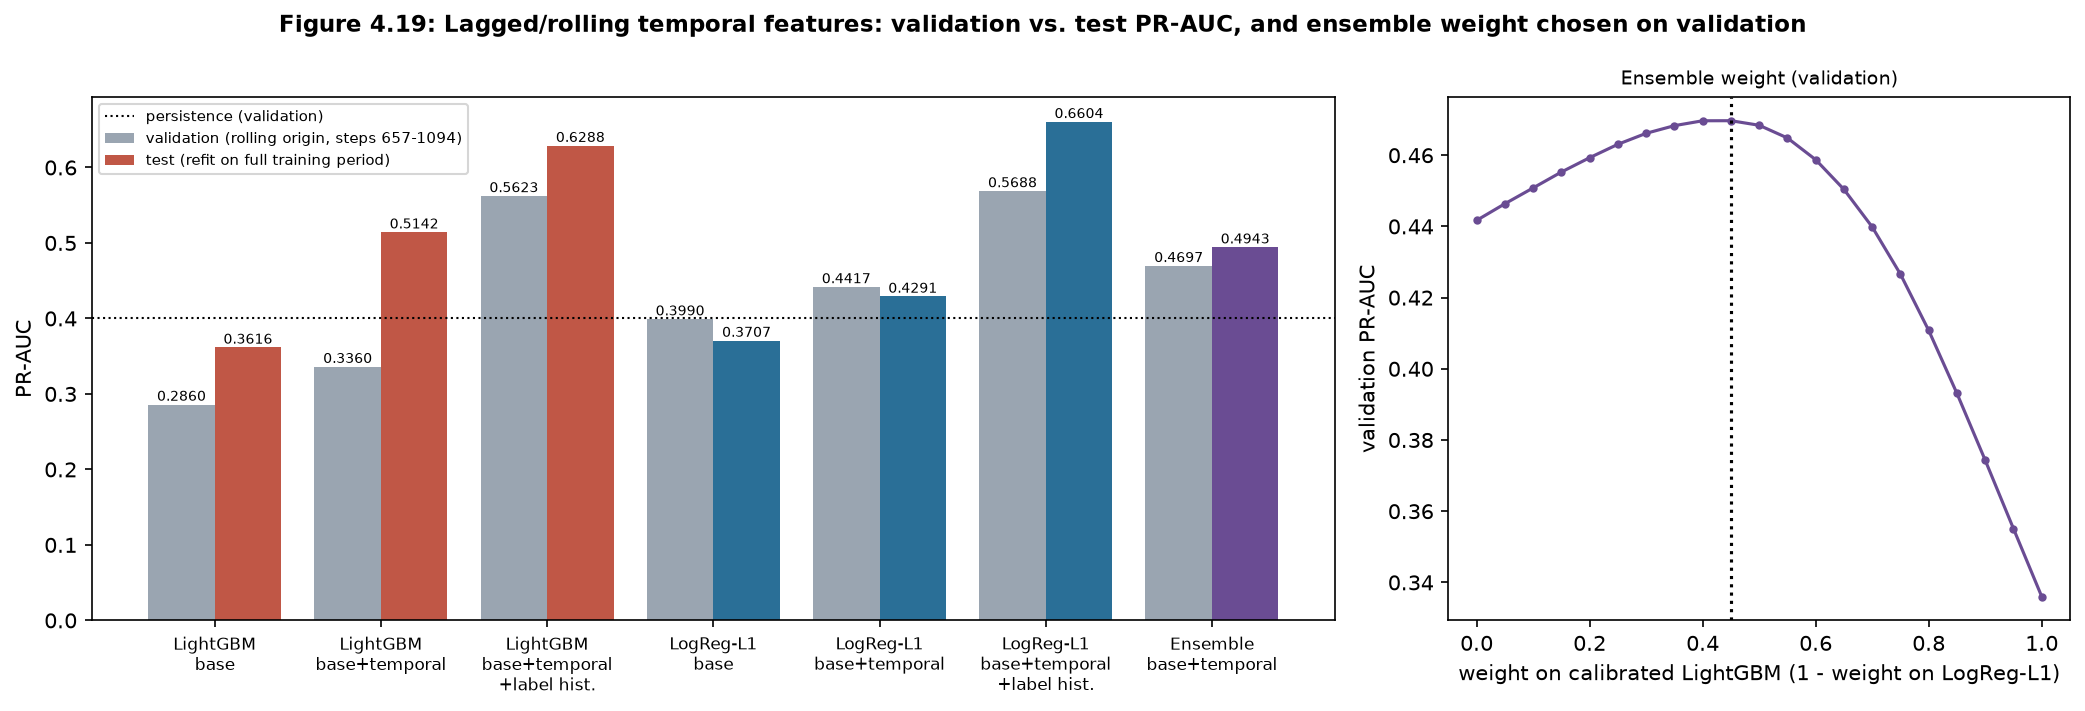

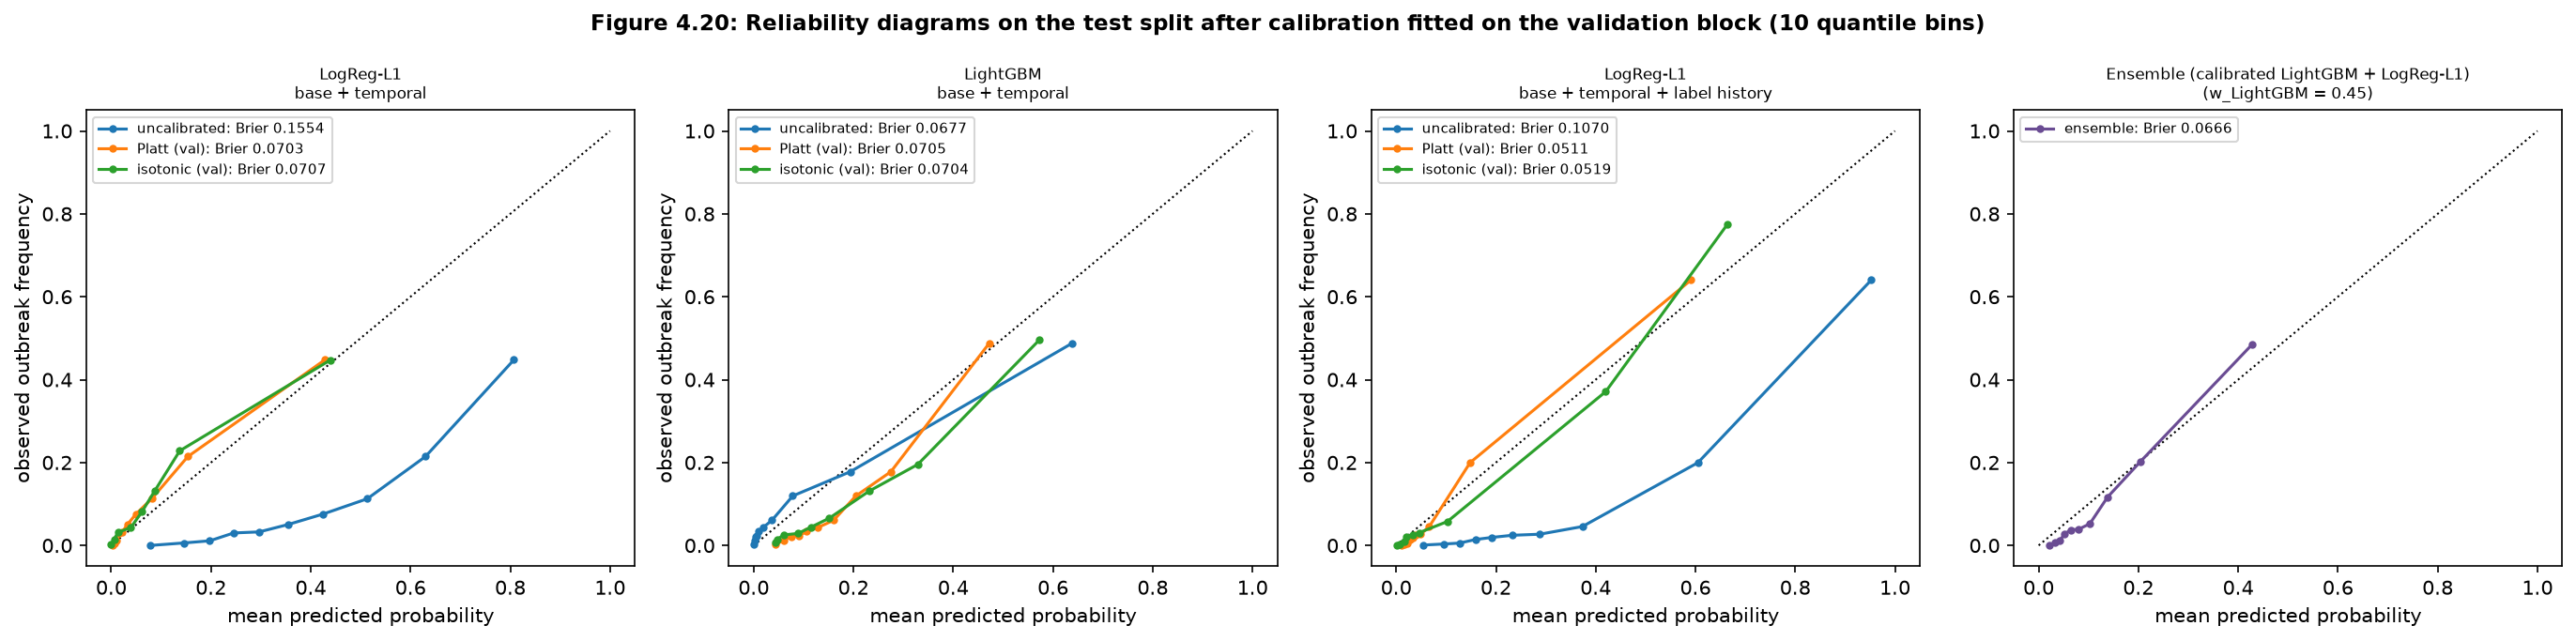

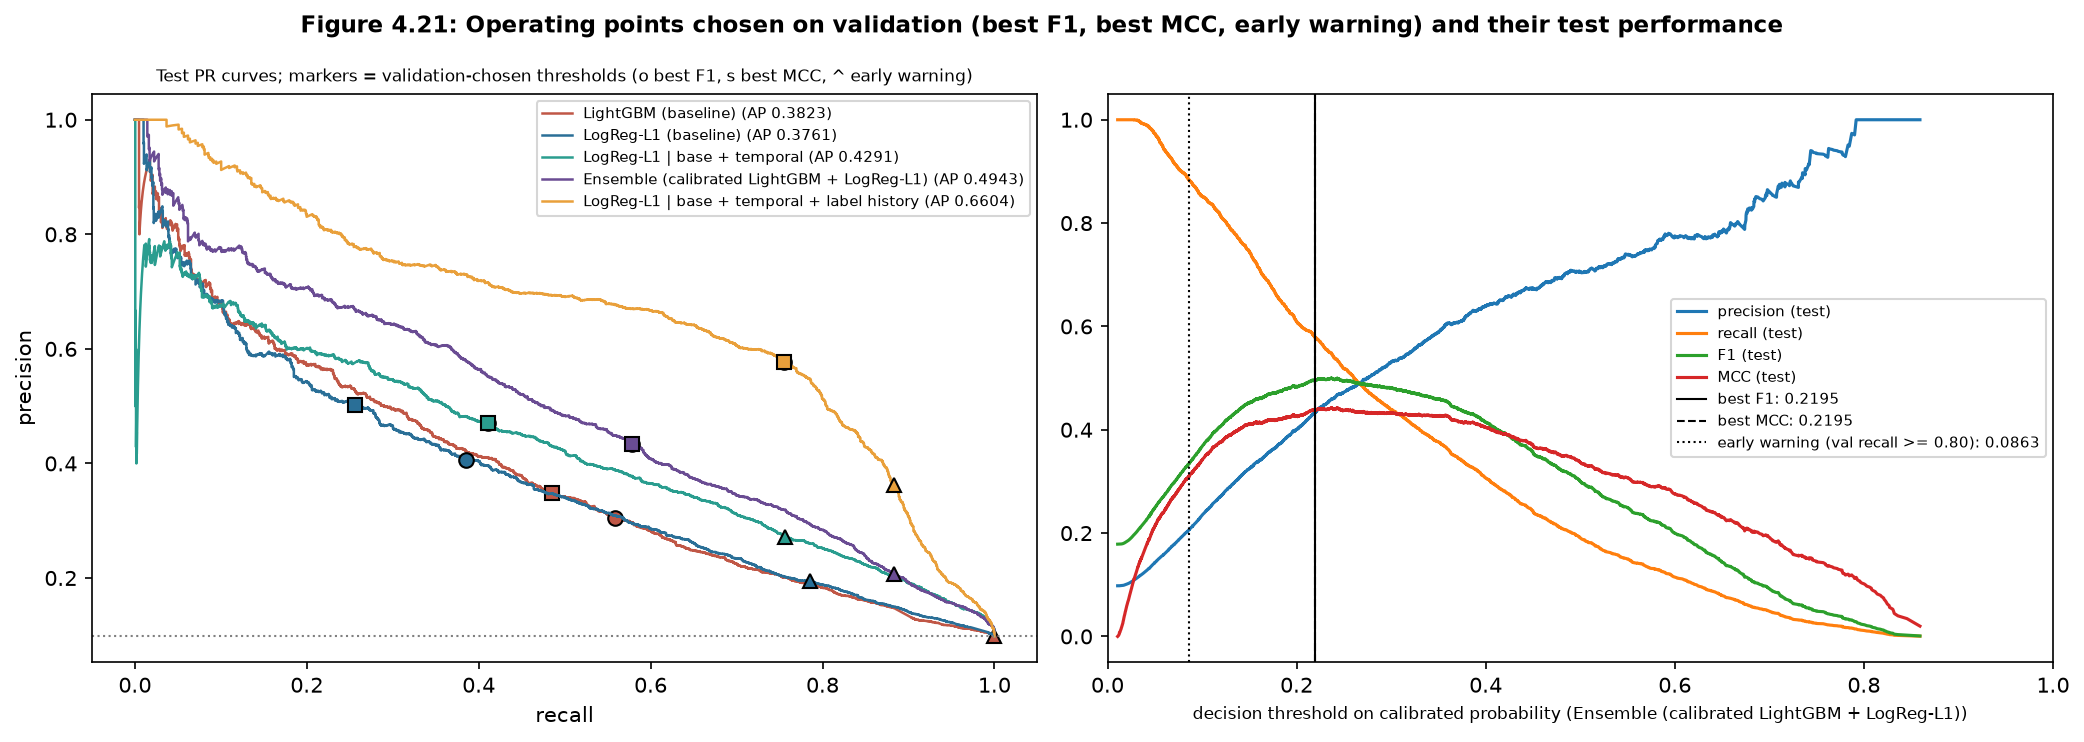

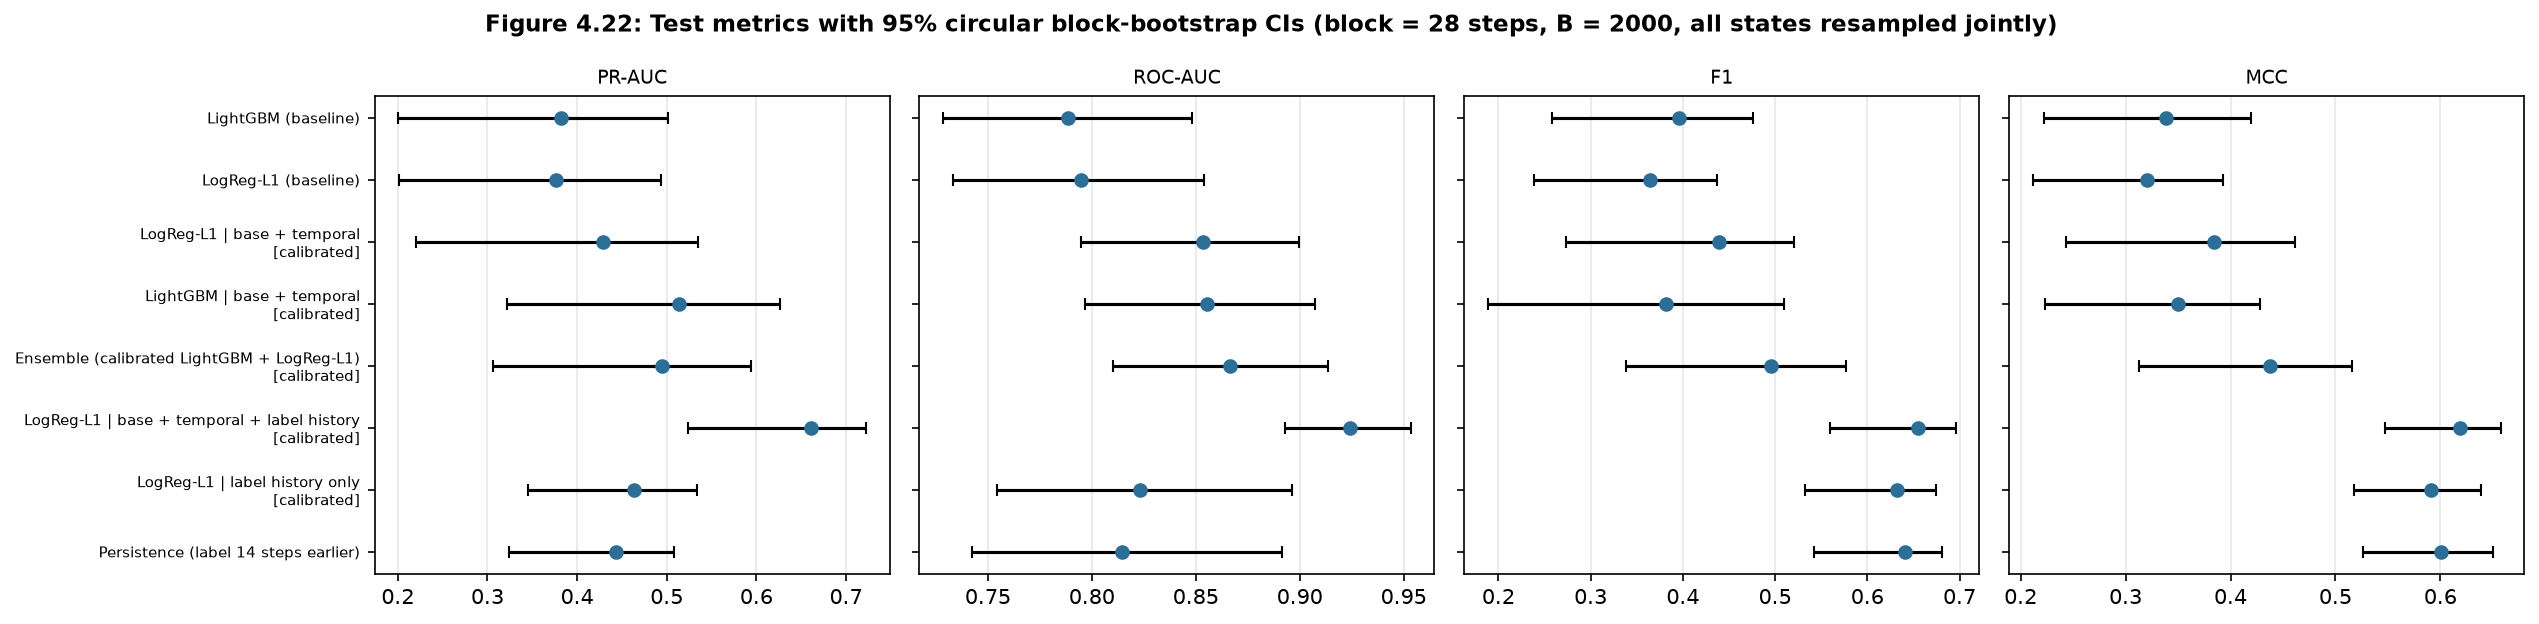

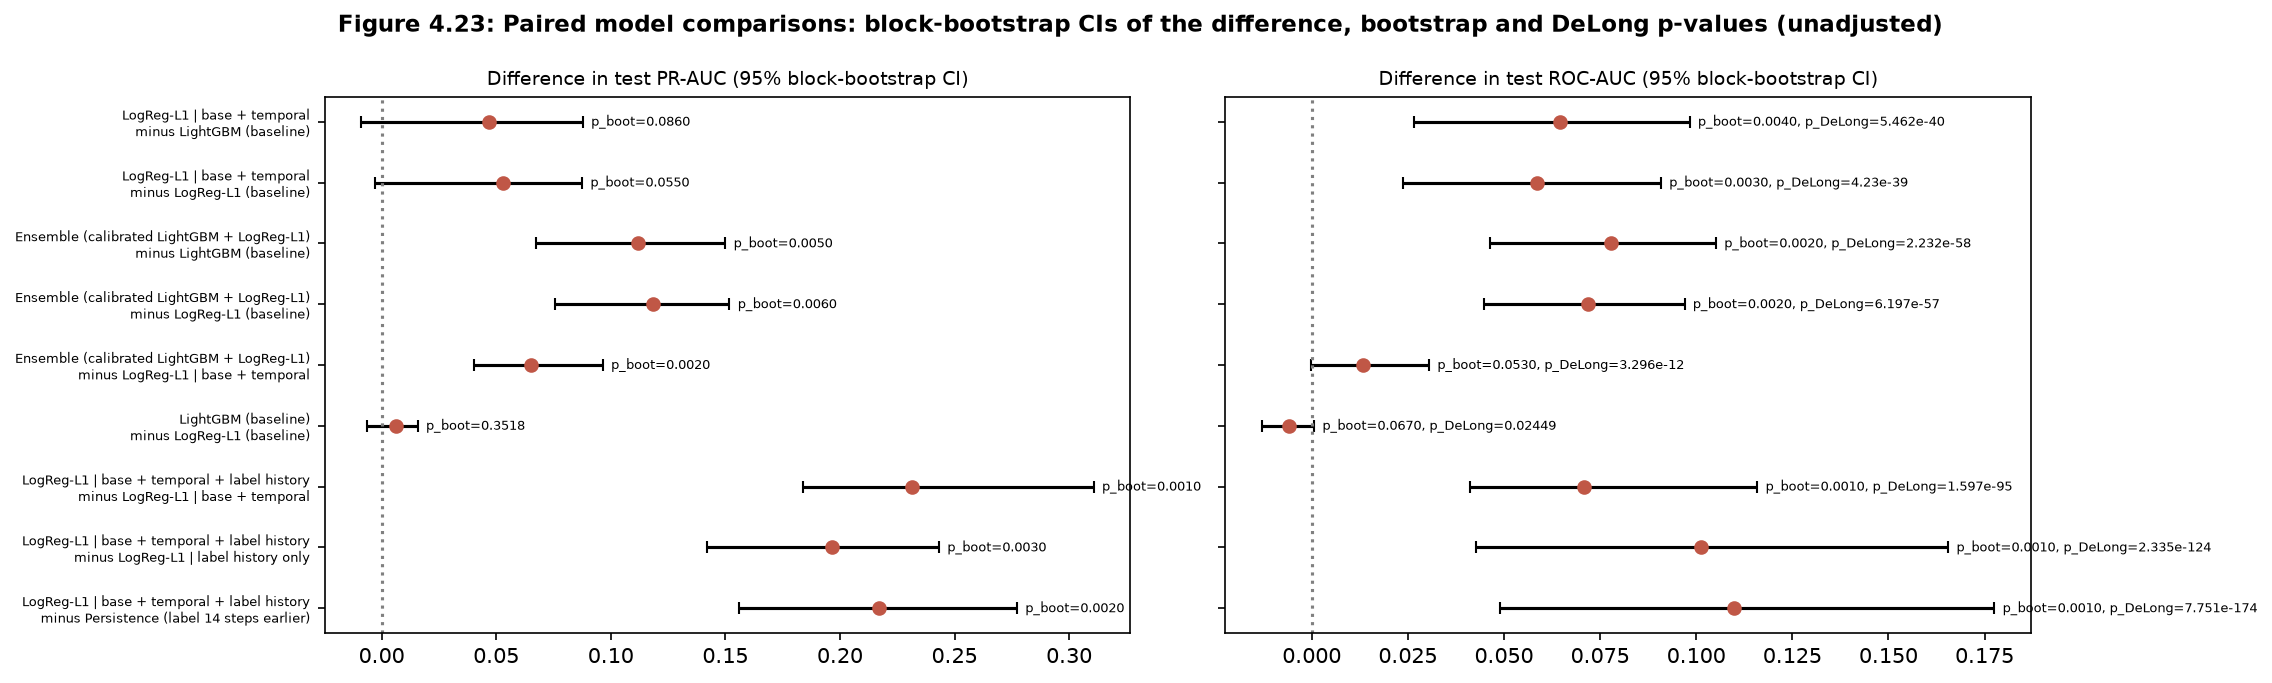

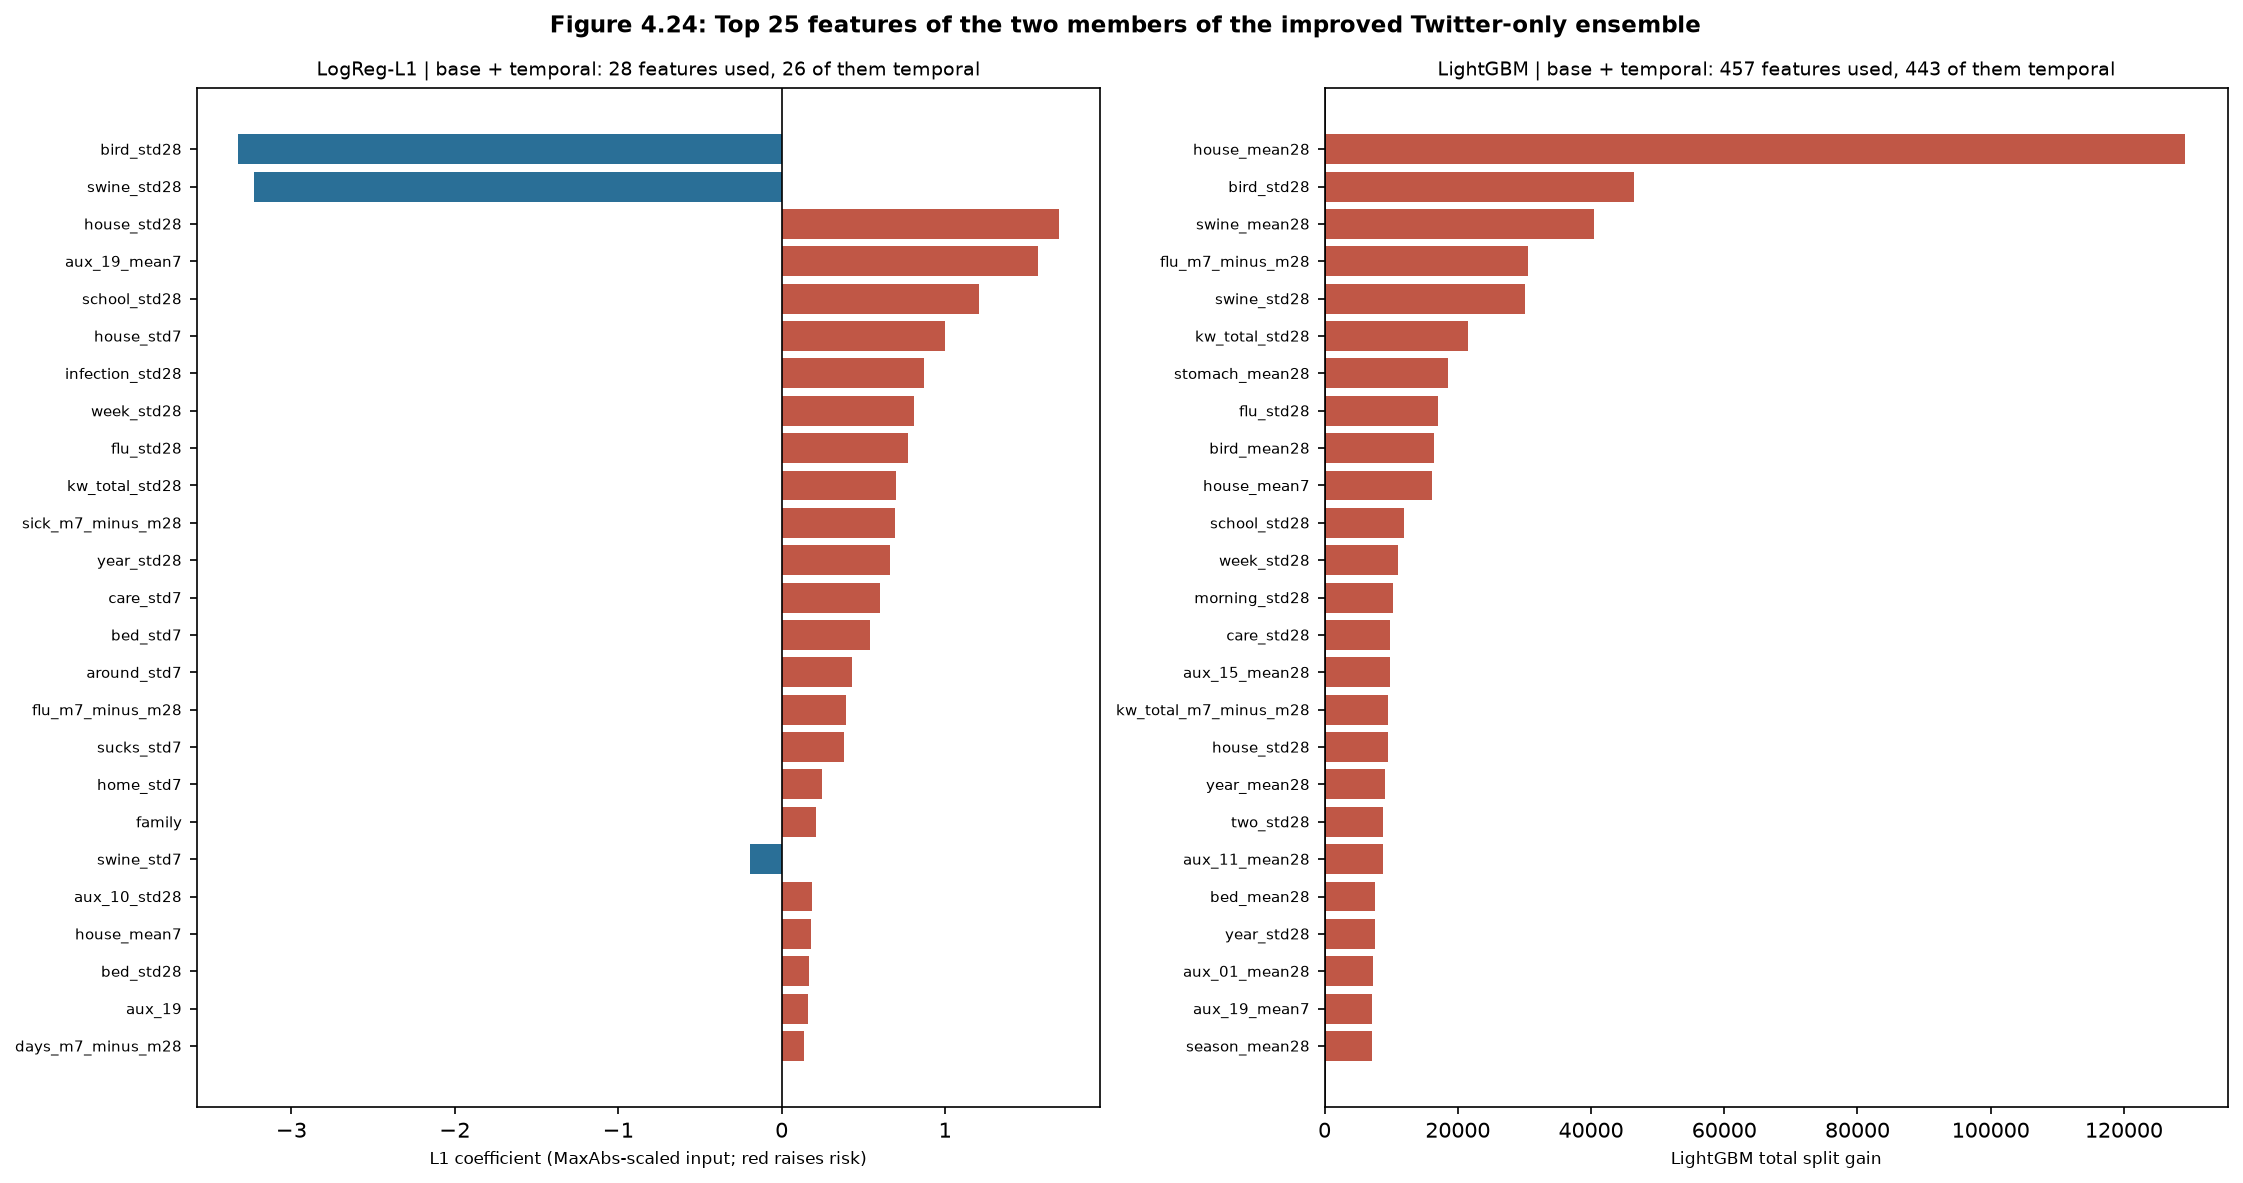

In [39]:
# ---------------------------------------------------------------------------------------------- 14.6 figures (Figure 4.19 onwards)
SHORT = {"base (545)": "base", "base + temporal": "base+temporal", "base + temporal + label history": "base+temporal\n+label hist."}
# Figure: validation PR-AUC of every candidate (best setting) with the test PR-AUC of the refitted model, and the ensemble weight curve
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw=dict(width_ratios=[2, 1]))
bc = BEST_CFG.reset_index()[["model", "feature_set", "val_pr_auc"]]
bc = pd.concat([bc, pd.DataFrame([dict(model="Ensemble", feature_set="base + temporal", val_pr_auc=VAL_PR_CAL[ENS])])], ignore_index=True)
te_pr = [average_precision_score(y_te, NEW_TEST_RAW[f"{r.model} | {r.feature_set}"]) if r.model != "Ensemble" else average_precision_score(y_te, test_prob(ENS)) for r in bc.itertuples()]
xx = np.arange(len(bc))
ax[0].bar(xx - 0.2, bc.val_pr_auc, 0.4, color="#9aa5b1", label="validation (rolling origin, steps 657-1094)")
ax[0].bar(xx + 0.2, te_pr, 0.4, color=["#2a6f97" if m == "LogReg-L1" else ("#6a4c93" if m == "Ensemble" else "#c05746") for m in bc.model],
          label="test (refit on full training period)")
for x_, v, w_ in zip(xx, bc.val_pr_auc, te_pr): ax[0].text(x_ - 0.2, v + 0.005, f"{v:.4f}", ha="center", fontsize=6.5); ax[0].text(x_ + 0.2, w_ + 0.005, f"{w_:.4f}", ha="center", fontsize=6.5)
ax[0].axhline(VALGRID.loc[VALGRID.model.str.startswith("Persistence"), "val_pr_auc"].iloc[0], color="k", ls=":", lw=1, label="persistence (validation)")
ax[0].set_xticks(xx); ax[0].set_xticklabels([f"{r.model}\n{SHORT[r.feature_set]}" for r in bc.itertuples()], fontsize=8)
ax[0].set_ylabel("PR-AUC"); ax[0].legend(fontsize=7, loc="upper left")
ax[1].plot(ENS_W.w_lightgbm, ENS_W.val_pr_auc, "o-", ms=3, color="#6a4c93"); ax[1].axvline(W_BEST, color="k", ls=":")
ax[1].set_xlabel("weight on calibrated LightGBM (1 - weight on LogReg-L1)"); ax[1].set_ylabel("validation PR-AUC"); ax[1].set_title("Ensemble weight (validation)", fontsize=9)
save_fig(fig, "temporal_features_validation", "Lagged/rolling temporal features: validation vs. test PR-AUC, and ensemble weight chosen on validation")

# Figure: reliability (test) before and after validation-fitted calibration
REL_MODELS = list(dict.fromkeys([BEST_TW, BEST_TW_LGB, BEST_LAB]))
fig, axes = plt.subplots(1, len(REL_MODELS) + 1, figsize=(4.6 * (len(REL_MODELS) + 1), 4.6))
for ax_, nm in zip(axes, REL_MODELS):
    ax_.plot([0, 1], [0, 1], "k:", lw=1)
    for lab_, pp_ in (("uncalibrated", NEW_TEST_RAW[nm]), ("Platt (val)", NEW_TEST_CAL[(nm, "Platt")]), ("isotonic (val)", NEW_TEST_CAL[(nm, "isotonic")])):
        fp_, mp_ = calibration_curve(y_te, pp_, n_bins=10, strategy="quantile"); ax_.plot(mp_, fp_, "o-", ms=3, label=f"{lab_}: Brier {brier_score_loss(y_te, pp_):.4f}")
    ax_.set_title(nm.replace(" | ", "\n"), fontsize=8); ax_.set_xlabel("mean predicted probability"); ax_.set_ylabel("observed outbreak frequency"); ax_.legend(fontsize=7)
ax_ = axes[-1]; ax_.plot([0, 1], [0, 1], "k:", lw=1)
fp_, mp_ = calibration_curve(y_te, test_prob(ENS), n_bins=10, strategy="quantile")
ax_.plot(mp_, fp_, "o-", ms=3, color="#6a4c93", label=f"ensemble: Brier {brier_score_loss(y_te, test_prob(ENS)):.4f}")
ax_.set_title(f"{ENS}\n(w_LightGBM = {W_BEST})", fontsize=8); ax_.set_xlabel("mean predicted probability"); ax_.legend(fontsize=7)
save_fig(fig, "reliability_validation_calibrated", "Reliability diagrams on the test split after calibration fitted on the validation block (10 quantile bins)")

# Figure: test precision-recall curves with the validation-chosen operating points
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for nm, col in (("LightGBM (baseline)", "#c05746"), ("LogReg-L1 (baseline)", "#2a6f97"), (BEST_TW, "#2a9d8f"), (ENS, "#6a4c93"), (BEST_LAB, "#e9a03b")):
    pp_ = NEW_TEST_RAW[nm] if "(baseline)" in nm else test_prob(nm)
    pr_, rc_, _ = precision_recall_curve(y_te, pp_); ax[0].plot(rc_, pr_, color=col, lw=1.2, label=f"{nm} (AP {average_precision_score(y_te, pp_):.4f})")
    if nm in OPS:
        for (op, thr), mk in zip(OPS[nm].items(), ("o", "s", "^")):
            mt_ = metrics(y_te, test_prob(nm), thr); ax[0].plot(mt_["recall"], mt_["precision"], mk, color=col, ms=7, mec="k")
ax[0].axhline(y_te.mean(), color="grey", ls=":", lw=1); ax[0].set_xlabel("recall"); ax[0].set_ylabel("precision"); ax[0].legend(fontsize=7)
ax[0].set_title("Test PR curves; markers = validation-chosen thresholds (o best F1, s best MCC, ^ early warning)", fontsize=8)
sc_ = threshold_scan(y_te, test_prob(REC_TW))
ax[1].plot(sc_.threshold, sc_.precision, label="precision (test)"); ax[1].plot(sc_.threshold, sc_.recall, label="recall (test)")
ax[1].plot(sc_.threshold, sc_.f1, label="F1 (test)"); ax[1].plot(sc_.threshold, sc_.mcc, label="MCC (test)")
for (op, thr), ls_ in zip(OPS[REC_TW].items(), ("-", "--", ":")): ax[1].axvline(thr, color="k", ls=ls_, lw=1, label=f"{op}: {thr:.4f}")
ax[1].set_xlabel(f"decision threshold on calibrated probability ({REC_TW})", fontsize=8); ax[1].legend(fontsize=7); ax[1].set_xlim(0, 1)
save_fig(fig, "operating_points", "Operating points chosen on validation (best F1, best MCC, early warning) and their test performance")

# Figure: bootstrap CI forest plot
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), sharey=True)
mnames = list(BOOT_MODELS)
for ax_, mt in zip(axes, MET4):
    d_ = CI[CI.metric == mt].set_index("model").loc[mnames]; yy = np.arange(len(mnames))[::-1]
    ax_.errorbar(d_.estimate, yy, xerr=[d_.estimate - d_.ci_low, d_.ci_high - d_.estimate], fmt="o", color="#2a6f97", ecolor="k", capsize=3)
    ax_.set_title(mt.upper().replace("_", "-"), fontsize=9); ax_.grid(axis="x", alpha=0.3)
axes[0].set_yticks(np.arange(len(mnames))[::-1]); axes[0].set_yticklabels([m.replace(" [calibrated]", "\n[calibrated]") for m in mnames], fontsize=7)
save_fig(fig, "bootstrap_ci_forest", f"Test metrics with 95% circular block-bootstrap CIs (block = {BOOT_L} steps, B = {BOOT_B}, all states resampled jointly)")

# Figure: paired differences
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), sharey=True)
lbl = [f"{a.replace(' [calibrated]', '')}\nminus {b.replace(' [calibrated]', '')}" for a, b in PAIRS]
for ax_, mt in zip(axes, ("pr_auc", "roc_auc")):
    d_ = SIG[SIG.metric == mt].reset_index(drop=True); yy = np.arange(len(d_))[::-1]
    ax_.errorbar(d_.diff_a_minus_b, yy, xerr=[d_.diff_a_minus_b - d_.boot_ci_low, d_.boot_ci_high - d_.diff_a_minus_b], fmt="o", color="#c05746", ecolor="k", capsize=3)
    ax_.axvline(0, color="grey", ls=":")
    for y_, r in zip(yy, d_.itertuples()):
        txt = f"p_boot={r.p_block_bootstrap:.4f}" + (f", p_DeLong={r.p_delong:.4g}" if mt == "roc_auc" else "")
        ax_.annotate(txt, (r.boot_ci_high, y_), xytext=(4, 0), textcoords="offset points", fontsize=6, va="center")
    ax_.set_title(f"Difference in test {mt.upper().replace('_', '-')} (95% block-bootstrap CI)", fontsize=9)
axes[0].set_yticks(np.arange(len(lbl))[::-1]); axes[0].set_yticklabels(lbl, fontsize=6)
save_fig(fig, "paired_differences", "Paired model comparisons: block-bootstrap CIs of the difference, bootstrap and DeLong p-values (unadjusted)")

# Figure: what the improved Twitter-only models rely on (both ensemble members)
IMP_TW = {}
fig, axes = plt.subplots(1, 2, figsize=(15, 8))
for ax_, nm in zip(axes, (BEST_TW_L1, BEST_TW_LGB)):
    mdl_ = NEW_MODELS[nm]; fs_ = NEW_CFG[nm]["feature_set"]
    if NEW_CFG[nm]["model"] == "LogReg-L1":
        imp_ = pd.Series(mdl_.named_steps["clf"].coef_.ravel(), index=FEATURE_NAMES[fs_]); xl_ = "L1 coefficient (MaxAbs-scaled input; red raises risk)"
    else:
        imp_ = pd.Series(mdl_.booster_.feature_importance("gain"), index=FEATURE_NAMES[fs_]); xl_ = "LightGBM total split gain"
    IMP_TW[nm] = imp_
    top_ = imp_[imp_.abs().sort_values(ascending=False).index[:25]][::-1]
    ax_.barh(top_.index, top_.values, color=["#c05746" if v > 0 else "#2a6f97" for v in top_.values]); ax_.axvline(0, color="k", lw=0.8)
    nz_ = int((imp_ != 0).sum()); nzt_ = int((imp_[[n for n in imp_.index if n not in set(feature_names)]] != 0).sum())
    ax_.set_xlabel(xl_, fontsize=8); ax_.tick_params(axis="y", labelsize=7); ax_.set_title(f"{nm}: {nz_} features used, {nzt_} of them temporal", fontsize=9)
save_fig(fig, "improved_model_features", "Top 25 features of the two members of the improved Twitter-only ensemble")
pd.concat({nm: v for nm, v in IMP_TW.items()}, names=["model", "feature"]).rename("weight_or_gain").reset_index().to_csv(
    os.path.join(RES_DIR, "improve_model_feature_weights.csv"), index=False)


**14.7 Summary tables** (also written to `results/improve_*.csv` and section 14 of `results_summary.md`).

In [40]:
def md(df, floatfmt=".4f"):
    return df.to_markdown(floatfmt=floatfmt)
# ---------------------------------------------------------------------------------------------- 14.7 summary table and results_summary.md section
SUMROWS = []
for nm in NEW_VAL_CAL:
    o = OPT[(OPT.model == nm) & (OPT.operating_point == "best F1")].iloc[0]
    tp_ = test_prob(nm)
    SUMROWS.append(dict(model=nm, feature_set=NEW_CFG[nm]["feature_set"], settings=NEW_CFG[nm]["settings"],
                        uses_label_history=("label history" in NEW_CFG[nm]["feature_set"]),
                        val_pr_auc_raw=average_precision_score(y_val, NEW_VAL_RAW[nm]) if nm in NEW_VAL_RAW else np.nan,
                        val_pr_auc_calibrated=VAL_PR_CAL[nm], val_roc_auc_calibrated=roc_auc_score(y_val, NEW_VAL_CAL[nm]),
                        test_pr_auc_raw=average_precision_score(y_te, NEW_TEST_RAW[nm]) if nm in NEW_TEST_RAW else np.nan,
                        test_roc_auc_raw=roc_auc_score(y_te, NEW_TEST_RAW[nm]) if nm in NEW_TEST_RAW else np.nan,
                        calibration=CAL_METHOD[nm], test_pr_auc_calibrated=average_precision_score(y_te, tp_), test_roc_auc_calibrated=roc_auc_score(y_te, tp_),
                        test_brier_uncalibrated=brier_score_loss(y_te, NEW_TEST_RAW[nm]) if nm in NEW_TEST_RAW else np.nan,
                        test_brier_calibrated=brier_score_loss(y_te, tp_), threshold_best_f1=o.threshold, test_f1=o.test_f1, test_mcc=o.test_mcc,
                        test_precision=o.test_precision, test_recall=o.test_recall))
SUMROWS.append(dict(model="Persistence (label 14 steps earlier)", feature_set="label history", settings="none", uses_label_history=True,
                    val_pr_auc_raw=average_precision_score(y_val, y_lag_val), val_pr_auc_calibrated=np.nan, val_roc_auc_calibrated=roc_auc_score(y_val, y_lag_val),
                    test_pr_auc_raw=PERSIST_TEST["pr_auc"], test_roc_auc_raw=PERSIST_TEST["roc_auc"], calibration="none",
                    test_brier_uncalibrated=PERSIST_TEST["brier"], threshold_best_f1=0.5, test_f1=PERSIST_TEST["f1"], test_mcc=PERSIST_TEST["mcc"],
                    test_precision=PERSIST_TEST["precision"], test_recall=PERSIST_TEST["recall"]))
IMPROVE = pd.DataFrame(SUMROWS).set_index("model"); IMPROVE.to_csv(os.path.join(RES_DIR, "improve_summary.csv"))
display(IMPROVE)

def _ci(nm, mt):
    r = CI[(CI.model == nm) & (CI.metric == mt)].iloc[0]; return f"{r.estimate:.4f} [{r.ci_low:.4f}, {r.ci_high:.4f}]"
CI_WIDE = pd.DataFrame({mt.upper().replace("_", "-"): {nm: _ci(nm, mt) for nm in BOOT_MODELS} for mt in MET4})
S14 = []
S14.append("\n## 14. Improved models and statistical validation (strictly temporal protocol)\n")
S14.append("*Added after the first submission draft. Every choice in this section (feature set, LightGBM/LogReg-L1 settings, calibrator, ensemble weight, "
           "thresholds) was made on a validation block carved from the end of the training period. The test split was scored once at the end.*\n")
S14.append("### 14.1 Protocol\n")
S14.append(md(pd.Series({**{k: str(v) for k, v in VAL_INFO.items()}, "validation_origins": "train on steps before the block, predict the block (two rolling origins, pooled)",
                          "temporal_feature_columns": str(FT_tr.shape[1]), "label_history_columns": ", ".join(FL_names),
                          "label_history_reporting_delay_steps": str(LABEL_DELAY), "ensemble_weight_on_lightgbm": str(W_BEST),
                          "recommended_twitter_only_model": REC_TW, "bootstrap": f"circular block bootstrap, L = {BOOT_L} steps, B = {BOOT_B}, seed = {BOOT_SEED}, all 48 states resampled jointly"}).to_frame("value")))
S14.append("\nBoundary check (train and test are one contiguous series per state):\n"); S14.append(md(pd.Series(BOUNDARY).to_frame("value"), ".6f"))
S14.append("\n### 14.2 Validation grid (best setting per model and feature set)\n"); S14.append(md(BEST_CFG.drop(columns=["seconds"]), ".6f"))
S14.append("\nReference points on the same validation rows:\n"); S14.append(VALGRID[~VALGRID.model.isin(["LightGBM", "LogReg-L1"]) | (VALGRID.feature_set == "label history only")]
                                                                        .drop(columns=["seconds"]).to_markdown(index=False, floatfmt=".6f"))
S14.append("\nFull grid: `results/improve_validation_grid.csv`.\n")
S14.append("\n### 14.3 Validation and test results (calibrated; thresholds = best validation F1)\n"); S14.append(md(IMPROVE.drop(columns=["settings"]), ".6f"))
S14.append("\nSettings:\n"); S14.append(IMPROVE[["settings"]].to_markdown())
S14.append("\n### 14.4 Calibration (fitted on validation; method chosen by cross-fitted validation Brier)\n"); S14.append(md(CAL2, ".6f"))
S14.append("\n### 14.5 Operating points (chosen on validation, applied unchanged to test)\n")
S14.append(OPT[["model", "operating_point", "threshold", "val_f1", "val_mcc", "val_precision", "val_recall", "test_f1", "test_mcc", "test_precision", "test_recall",
                "test_balanced_acc", "test_alerts_per_1000"]].to_markdown(index=False, floatfmt=".6f"))
S14.append("\n### 14.6 95% block-bootstrap confidence intervals (test)\n")
S14.append(f"F1 and MCC use each model's best-F1 threshold (baselines: the training-OOF threshold from section 4). Median positive run length in test: {float(np.median(RUNLEN))} steps; "
           f"autocorrelation of the cross-state outbreak share at lags 1/7/14/28/56: " + ", ".join(f"{ACF[k]:.6f}" for k in ACF) + ".\n")
S14.append(CI_WIDE.to_markdown()); S14.append("\nRaw values: `results/improve_bootstrap_ci.csv`.\n")
S14.append("\n### 14.7 Paired significance tests (test split)\n")
S14.append("p_block_bootstrap = two-sided percentile p-value of the paired block-bootstrap difference; Holm-adjusted within each metric. DeLong assumes independent rows "
           "and therefore understates the uncertainty for these autocorrelated data; the block bootstrap is the primary test.\n")
S14.append(SIG.to_markdown(index=False, floatfmt=".6g"))
S14.append("\n### 14.8 Block-length sensitivity (PR-AUC, B = 1000 per length)\n"); S14.append(SENS.to_markdown(index=False, floatfmt=".6f"))
print("\n".join(S14)[:3000])


,feature_set,settings,uses_label_history,val_pr_auc_raw,val_pr_auc_calibrated,val_roc_auc_calibrated,test_pr_auc_raw,test_roc_auc_raw,calibration,test_pr_auc_calibrated,test_roc_auc_calibrated,test_brier_uncalibrated,test_brier_calibrated,threshold_best_f1,test_f1,test_mcc,test_precision,test_recall
model,,,,,,,,,,,,,,,,,,
LightGBM | base (545),base (545),"{""num_leaves"": 7, ""min_child_samples"": 200, ""n...",False,0.285991,0.285991,0.733206,0.361561,0.788283,Platt,0.361561,0.788283,0.149143,0.076045,0.152951,0.396403,0.324449,0.346204,0.463628
LightGBM | base + temporal,base + temporal,"{""num_leaves"": 31, ""min_child_samples"": 200, ""...",False,0.336014,0.336014,0.730160,0.514190,0.855286,Platt,0.514190,0.855286,0.067709,0.070507,0.172238,0.382187,0.349621,0.249698,0.814198
LightGBM | base + temporal + label history,base + temporal + label history,"{""num_leaves"": 31, ""min_child_samples"": 200, ""...",True,0.562286,0.562286,0.834124,0.628836,0.917617,Platt,0.628836,0.917617,0.062935,0.055763,0.327063,0.650436,0.616703,0.555556,0.784400
LogReg-L1 | base (545),base (545),"{""C"": 0.03}",False,0.399023,0.399023,0.813650,0.370651,0.788213,Platt,0.370651,0.788213,0.153918,0.076477,0.166864,0.376784,0.318827,0.420399,0.341367
LogReg-L1 | base + temporal,base + temporal,"{""C"": 0.005}",False,0.441696,0.441696,0.851925,0.429097,0.853307,Platt,0.429097,0.853307,0.155351,0.070287,0.261313,0.439139,0.383858,0.471357,0.411043
LogReg-L1 | base + temporal + label history,base + temporal + label history,"{""C"": 0.01}",True,0.568808,0.568808,0.892365,0.660423,0.924193,Platt,0.660423,0.924193,0.106971,0.051070,0.167187,0.654891,0.618748,0.577942,0.755478
LightGBM (baseline),base (545),"{""num_leaves"": 15, ""min_child_samples"": 20, ""n...",False,0.210344,0.200117,0.642244,0.382267,0.788750,isotonic,0.352840,0.769785,0.134990,0.075391,0.148867,0.394981,0.326074,0.305462,0.558720
LogReg-L1 (baseline),base (545),"{""C"": 0.1} (sections 5-7)",False,0.370993,0.360332,0.785760,0.376068,0.794664,isotonic,0.357812,0.792435,0.152987,0.075374,0.203863,0.395772,0.332157,0.406467,0.385627
LogReg-L1 | label history only,label history only,"{""C"": 1.0}",True,0.454460,0.454460,0.839516,0.463752,0.823061,Platt,0.463752,0.823061,0.130957,0.058355,0.107095,0.631897,0.590697,0.584575,0.687555



## 14. Improved models and statistical validation (strictly temporal protocol)

*Added after the first submission draft. Every choice in this section (feature set, LightGBM/LogReg-L1 settings, calibrator, ensemble weight, thresholds) was made on a validation block carved from the end of the training period. The test split was scored once at the end.*

### 14.1 Protocol

|                                     | value                                                                                        |
|:------------------------------------|:---------------------------------------------------------------------------------------------|
| val_steps                           | 657-1094                                                                                     |
| n_val                               | 21024                                                                                        |
| val_positives                       | 1981                                          

## 15. Save prototype artefacts and write `results_summary.md`

In [41]:
import joblib
art = dict(best_stat=BEST_STAT, best_ml=BEST_ML, thresholds={BEST_STAT: THRESH[BEST_STAT], BEST_ML: THRESH[BEST_ML]},
           feature_names=feature_names, keywords=keywords, n_aux=N_AUX, states=states, train_steps=DATASET["steps_train"])
joblib.dump(MODELS[BEST_STAT], os.path.join(ART_DIR, "best_stat_model.joblib"))
joblib.dump(MODELS[BEST_ML], os.path.join(ART_DIR, "best_ml_model.joblib"))
sp.save_npz(os.path.join(ART_DIR, "X_test.npz"), X_te)
meta_te.to_csv(os.path.join(ART_DIR, "test_meta.csv"), index=False)
RES.to_csv(os.path.join(ART_DIR, "test_results.csv")); TIM.to_csv(os.path.join(ART_DIR, "runtime.csv")); CAL.to_csv(os.path.join(ART_DIR, "calibration_posthoc.csv"), index=False)
pd.DataFrame({"t": t_te, "state": state_te, "y": y_te, "p_stat": PROBS[BEST_STAT], "p_ml": PROBS[BEST_ML]}).to_csv(os.path.join(ART_DIR, "test_predictions.csv"), index=False)
art["aux_train_median"] = np.median(X_tr[:, :N_AUX].toarray(), axis=0).tolist()
json.dump(art, open(os.path.join(ART_DIR, "meta.json"), "w"), indent=1)
import shutil; shutil.copy("itrpa_models.py", os.path.join("prototype", "itrpa_models.py"))
print("Saved artefacts:", sorted(os.listdir(ART_DIR)))

Saved artefacts: ['X_test.npz', 'best_ml_model.joblib', 'best_stat_model.joblib', 'calibration_posthoc.csv', 'meta.json', 'runtime.csv', 'test_meta.csv', 'test_predictions.csv', 'test_results.csv']


In [42]:
# Improved-model artefacts for the prototype (written only if the recommended Twitter-only model beats both baselines on
# validation PR-AUC and its test PR-AUC improvement over both baselines is significant in the block bootstrap).
B_REC = f"{REC_TW} [calibrated]"
sig_ok = all(SIG[(SIG.model_a == B_REC) & (SIG.model_b == b) & (SIG.metric == "pr_auc")].p_block_bootstrap_holm.iloc[0] < 0.05
             for b in ("LightGBM (baseline)", "LogReg-L1 (baseline)")) if B_REC in set(SIG.model_a) else False
val_ok = VAL_PR_CAL[REC_TW] > max(VAL_PR_CAL["LightGBM (baseline)"], VAL_PR_CAL["LogReg-L1 (baseline)"])
UPDATE_PROTOTYPE = bool(sig_ok and val_ok)
print("Update prototype with the improved model:", UPDATE_PROTOTYPE, "| validation better:", val_ok, "| significant on test:", sig_ok)
if UPDATE_PROTOTYPE:
    members = [BEST_TW_LGB, BEST_TW_L1] if REC_TW == ENS else [REC_TW]
    imeta = dict(name=REC_TW, members=members, weights=([W_BEST, 1 - W_BEST] if REC_TW == ENS else [1.0]),
                 member_files={}, calibration={}, feature_sets={nm: NEW_CFG[nm]["feature_set"] for nm in members},
                 settings={nm: NEW_CFG[nm]["settings"] for nm in members}, operating_points=OPS[REC_TW],
                 temporal=dict(series=SERIES_NAMES, lags=list(LAGS), windows=list(WINS), top_keywords=N_TOPKW),
                 note="Probabilities are Platt/isotonic-calibrated on the training-period validation block (steps 657-1094). "
                      "Temporal features need each state's history, so the improved model is shown for the test-set lookup only.")
    for j, nm in enumerate(members):
        fn = f"improved_member{j + 1}.joblib"; joblib.dump(NEW_MODELS[nm], os.path.join(ART_DIR, fn)); imeta["member_files"][nm] = fn
        f = CAL_FN[(nm, CAL_METHOD[nm])]; imeta["calibration"][nm] = dict(method=CAL_METHOD[nm], **getattr(f, "params", {}))
    sp.save_npz(os.path.join(ART_DIR, "X_test_temporal_tree.npz"), FEATURE_SETS["base + temporal"][1])
    sp.save_npz(os.path.join(ART_DIR, "X_test_temporal_linear.npz"), LIN_SETS["base + temporal"][1])
    json.dump(imeta, open(os.path.join(ART_DIR, "improved_meta.json"), "w"), indent=1)
    pd.DataFrame({"t": t_te, "state": state_te, "y": y_te, "p_improved": test_prob(REC_TW),
                  **{f"p_member{j + 1}": test_prob(nm) for j, nm in enumerate(members)}}).to_csv(os.path.join(ART_DIR, "improved_test_predictions.csv"), index=False)
    for f in ("improve_summary.csv", "improve_bootstrap_ci.csv", "improve_significance.csv", "improve_operating_points.csv"):
        shutil.copy(os.path.join(RES_DIR, f), os.path.join(ART_DIR, f))
    print("Saved improved-model artefacts:", sorted(f for f in os.listdir(ART_DIR) if f.startswith(("improved", "improve_", "X_test_temporal"))))


Update prototype with the improved model: True | validation better: True | significant on test: True


Saved improved-model artefacts: ['X_test_temporal_linear.npz', 'X_test_temporal_tree.npz', 'improve_bootstrap_ci.csv', 'improve_operating_points.csv', 'improve_significance.csv', 'improve_summary.csv', 'improved_member1.joblib', 'improved_member2.joblib', 'improved_meta.json', 'improved_test_predictions.csv']


In [43]:
NOTES_S13 = "## 13. Notes, caveats and deviations from the proposal (written after reading the outputs above)\n\n**Data structure**\n* The X matrices have 545 columns, but `flu_keywords` lists 525. Columns 20\u2013544 line up with the keywords in order (column 20 = \"flu\" has the largest total).\n  Columns 0\u201319 are undocumented and non-decreasing within every row (aux_monotone_frac = 1.0). They were kept as `aux_00`\u2013`aux_19`.\n  They carry a lot of signal: dropping them lowers test PR-AUC from 0.3708 to 0.3393 (LogReg-L2) and from 0.3823 to 0.3396 (LightGBM) (\u00a77.1), and `aux_19` ranks near the top in most importance lists.\n  Because their meaning is unknown, this is a limitation for interpretation.\n* Each state has 1,095 training rows and 485 test rows (48 \u00d7 1,580 = 75,840 against 75,839 on UCI). Labels are piecewise constant, and 78.8% of positive runs are multiples of 7 rows.\n  This fits weekly CDC labels on rows that look like daily-indexed sliding windows. UCI calls each row a state-week, with the label = outbreak in the following week. The notebook uses the neutral term \"time step\".\n* The proposal planned an 80/20 stratified split. The **provided temporal split** was used instead (train = first 1,095 steps, test = last 485), as instructed. Prevalence differs: 5.53% in train and 9.80% in test.\n\n**Evaluation**\n* Thresholds for F1, precision, recall, MCC and balanced accuracy were tuned on training OOF predictions (max F1), never on test data.\n* Shuffled stratified CV on autocorrelated, overlapping time steps is optimistic. Forward-chaining temporal CV gave much lower PR-AUC for every model (for example LightGBM 0.1628 against 0.3843 OOF) (\u00a78).\n  Part of this gap comes from very low validation prevalence in temporal folds 1\u20132 (1.28% and 0.11%), so the fold values should be read with care.\n* Nested CV (proposal 3.5) was **not** run because of compute time. Single-level 5-fold CV tuning plus the held-out test split was used.\n* The differences between the top four models on test PR-AUC are small (0.3708\u20130.3823). Section 14 adds block-bootstrap CIs and paired tests: the LightGBM vs. LogReg-L1 baseline difference is not significant, so in sections 4\u201311 \"best\" means best point estimate on this split.\n\n**Models (deviations)**\n* **Poisson / NB**: implemented as generative count classifiers on total keyword volume with state fixed effects (see notebook \u00a75.2). The Poisson model's posteriors are extremely\n  over-confident: its tuned threshold is 1.0000 because overdispersion is ignored. NB (\u03b1 = 0.6168) is better behaved. In temporal CV the count models had the highest ROC-AUC (NB 0.8794).\n* **Bayesian LR**: full-data NUTS over 545 features was not feasible (a 50-feature NUTS test did not finish in about 11 minutes). Instead the model used a horseshoe prior on the top-50 \u03c7\u00b2 features with\n  **mean-field ADVI** (PyMC 6.4.0), which tends to underestimate posterior uncertainty. Its threshold was tuned on in-sample training predictions, not OOF.\n* **PCA** was replaced by **TruncatedSVD** (sparse input). 300 components (the cap) did not reach 95% explained variance, so the SVD rows use 300 components.\n* **MLP**: scikit-learn MLP (128, 64), with an L2 penalty instead of dropout, early stopping, and random oversampling for imbalance. It performed poorly (test ROC-AUC 0.5368), so the result reflects this specific set-up and is not a general verdict on neural networks.\n  The LSTM in the proposal was optional and was not run.\n* **RF** tuning grid was reduced (max_features fixed to \"sqrt\") to save compute time.\n* **XGBoost** importance includes several rare non-English tokens (for example \"vai\", \"aku\", \"lagi\", \"banget\") among its top 20 by mean |SHAP|. This suggests some splits on rare tokens and is worth discussing as possible spurious signal.\n\n**Calibration**\n* Class-weighted models over-predict risk before calibration (Brier score 0.13\u20130.15). Platt and isotonic calibration roughly halve the Brier score (for example LightGBM 0.1350 \u2192 0.0759 with Platt).\n  After calibration, the reliability curves *under*-predict on test, which fits the higher test prevalence (9.80% against 5.53%).\n\n**Live X dashboard** (prototype only): an illustration, with no labels and no evaluation. None of its numbers belong in the results chapter.\n"
def md(df, floatfmt=".4f"):
    return df.to_markdown(floatfmt=floatfmt)
L = []
L.append("# ITRPA4 Mini Dissertation: Results Summary\n")
L.append("*This file is generated automatically by `itrpa_experiments.ipynb`. Every number below comes from that notebook run (SEED = 42).*\n")
L.append("## 1. Dataset\n")
L.append(md(pd.Series(DATASET).to_frame("value"), ".4f"))
L.append("\n### 1.1 Sparsity\n"); L.append(md(pd.Series(SPARSITY).to_frame("value"), ".4f"))
L.append("\n### 1.2 Top 20 keywords by total training count\n"); L.append(top_kw.to_markdown(index=False, floatfmt=".4f"))
L.append("\n### 1.3 Class imbalance by split\n"); L.append(md(IMB.astype(float)))
L.append("\n### 1.4 Class imbalance by state\n"); L.append(md(by_state))
L.append("\n## 2. Preprocessing comparison (LogReg-L2, 5-fold stratified CV on train)\n"); L.append(PRE.to_markdown(index=False, floatfmt=".4f"))
L.append(f"\nSelected: **{BEST_PRE}**\n")
L.append("\n## 3. Hyperparameter tuning (5-fold stratified CV PR-AUC on train)\n"); L.append(md(CVB))
L.append("\n## 4. Test-set results (provided test split)\n"); L.append(md(RES))
L.append("\n### 4.1 Best model per metric (test)\n"); L.append(pd.Series(BEST_PER_METRIC).to_frame("best model").to_markdown())
L.append(f"\nBest statistical model (PR-AUC): **{BEST_STAT}**; best ML model (PR-AUC): **{BEST_ML}**\n")
L.append("\n### 4.2 Count-model coefficients\n"); L.append(md(pd.DataFrame(COUNT_COEFS).T))
L.append(f"\n### 4.3 Bayesian LR\n\nMethod: {BAYES_METHOD}\n\n"); L.append(md(pd.Series(BAYES_UNC).to_frame("value")))
L.append("\n### 4.4 Per-state test PR-AUC\n"); L.append(PER_STATE.to_markdown(index=False, floatfmt=".4f"))
L.append("\n## 5. Dimensionality reduction (RQ3)\n"); L.append(DRR.to_markdown(index=False, floatfmt=".4f"))
L.append("\n## 6. Imbalance handling (RQ3)\n"); L.append(IMR.to_markdown(index=False, floatfmt=".4f"))
L.append("\n## 7. Sparsity experiments (RQ1)\n"); L.append(SPR.to_markdown(index=False, floatfmt=".4f"))
L.append("\n### 7.1 Keywords-only sensitivity\n"); L.append(KWR.to_markdown(index=False, floatfmt=".4f"))
L.append("\n## 8. Temporal validation\n"); L.append(md(TEMP_SUM)); L.append("\nFolds:\n"); L.append(TEMP.to_markdown(index=False, floatfmt=".4f"))
L.append("\n## 9. Calibration (Brier score, test)\n"); L.append(md(CAL.pivot(index="model", columns="method", values="brier"), ".5f"))
L.append("\nPR-AUC after calibration:\n"); L.append(md(CAL.pivot(index="model", columns="method", values="pr_auc")))
L.append(f"\n## 10. Interpretability\n\nLogReg-L1 non-zero coefficients: {nz_l1} of {len(feature_names)}\n\n### Top 20 features per model\n"); L.append(TOP20.to_markdown())
L.append("\n### LogReg-L2 largest positive coefficients\n"); L.append(md(L2_POS.to_frame("coef")))
L.append("\n### LogReg-L2 largest negative coefficients\n"); L.append(md(L2_NEG.to_frame("coef")))
L.append("\n### Top-20 overlap (Jaccard)\n"); L.append(md(J, ".3f")); L.append("\n### Spearman correlation of |importance| (all features)\n"); L.append(md(R, ".3f"))
L.append("\n### Consensus top 20 (mean rank across models)\n"); L.append(md(CONSENSUS, ".2f"))
L.append("\n## 11. Compute time\n"); L.append(md(TIM, ".3f")); L.append("\nEnvironment: " + json.dumps(ENV))
L.append("\n## 12. Figures\n"); L.append(pd.DataFrame(FIGS, columns=["Figure", "file", "title"]).to_markdown(index=False, disable_numparse=True))
L.append("\n---\n")
L.append(NOTES_S13)
L += [x.replace("LightGBM | ", "LightGBM \\| ").replace("LogReg-L1 | ", "LogReg-L1 \\| ") for x in S14]  # escape pipes inside table cells
open("results_summary.md", "w").write("\n".join(L) + "\n")
print("Wrote results_summary.md with", len(L), "blocks;", len(FIGS), "figures")

Wrote results_summary.md with 91 blocks; 24 figures
